# 사기 탐지 EDA — 8개 카테고리 종합 시각화

| 카테고리 | 기법 |
|----------|------|
| 1) 단일 변수 분포/품질 | Histogram·KDE·Rug·ECDF·CDF·Box·Violin·Strip·Swarm·Ridgeline·QQ·Skewness·Outlier·Z-score |
| 2) 수치×수치 | Scatter·Bubble·Regression·LOESS·Hexbin·2D Hist·Contour·Joint·Binned |
| 3) 수치×범주 | Grouped Box·Violin·Mean±CI·Stacked·100%·Side-by-side·Category Heatmap |
| 4) 다변량 | Correlation·Pairplot·Parallel·Radar·PCA·t-SNE·FI·Permutation·PDP·ICE·SHAP |
| 5) 분리력 | PR·ROC·Threshold sweep·Lift·Gain·Confusion·Calibration |
| 6) 시간/순서 | Line·Rolling·Cumulative·ACF·Lag·Heatmap |
| 7) 텍스트 | 설명만 (이 데이터에 텍스트 없음) |
| 8) 품질 진단 | Train vs Test·KS test·Missingness vs class·Rare category·Drift 요약 |


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import warnings
from scipy import stats
from scipy.stats import ks_2samp
from sklearn.preprocessing import LabelEncoder
warnings.filterwarnings('ignore')

matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus'] = False
SEED = 42
np.random.seed(SEED)

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')

num_cols = [c for c in train.select_dtypes(include='number').columns
            if c not in ['id', 'fraud_bool']]
cat_cols = train.select_dtypes(include='object').columns.tolist()
fraud  = train[train['fraud_bool'] == 1]
normal = train[train['fraud_bool'] == 0]
CCAT   = cat_cols[0] if cat_cols else None

NCOLS_GRID = 4   # 그리드 한 행에 피처 몇 개씩

print('train:', train.shape, '  fraud:', len(fraud), '  normal:', len(normal))
print('수치형 칼럼:', num_cols)
print('범주형 칼럼:', cat_cols)


: 

---
## 1) 단일 변수 분포 / 품질


### 1-1. Histogram / KDE — 전체 피처

**뭐 보여주나:** 각 수치형 변수의 값이 어디에 얼마나 몰리는지. 파랑=정상, 빨강=사기.

**다음 단계:**
- 두 클래스 피크가 다른 변수 → 해당 구간 `bin` 피처 또는 임계값 플래그
- 분포가 한쪽으로 심하게 치우치면 → `log1p` 변환 시도


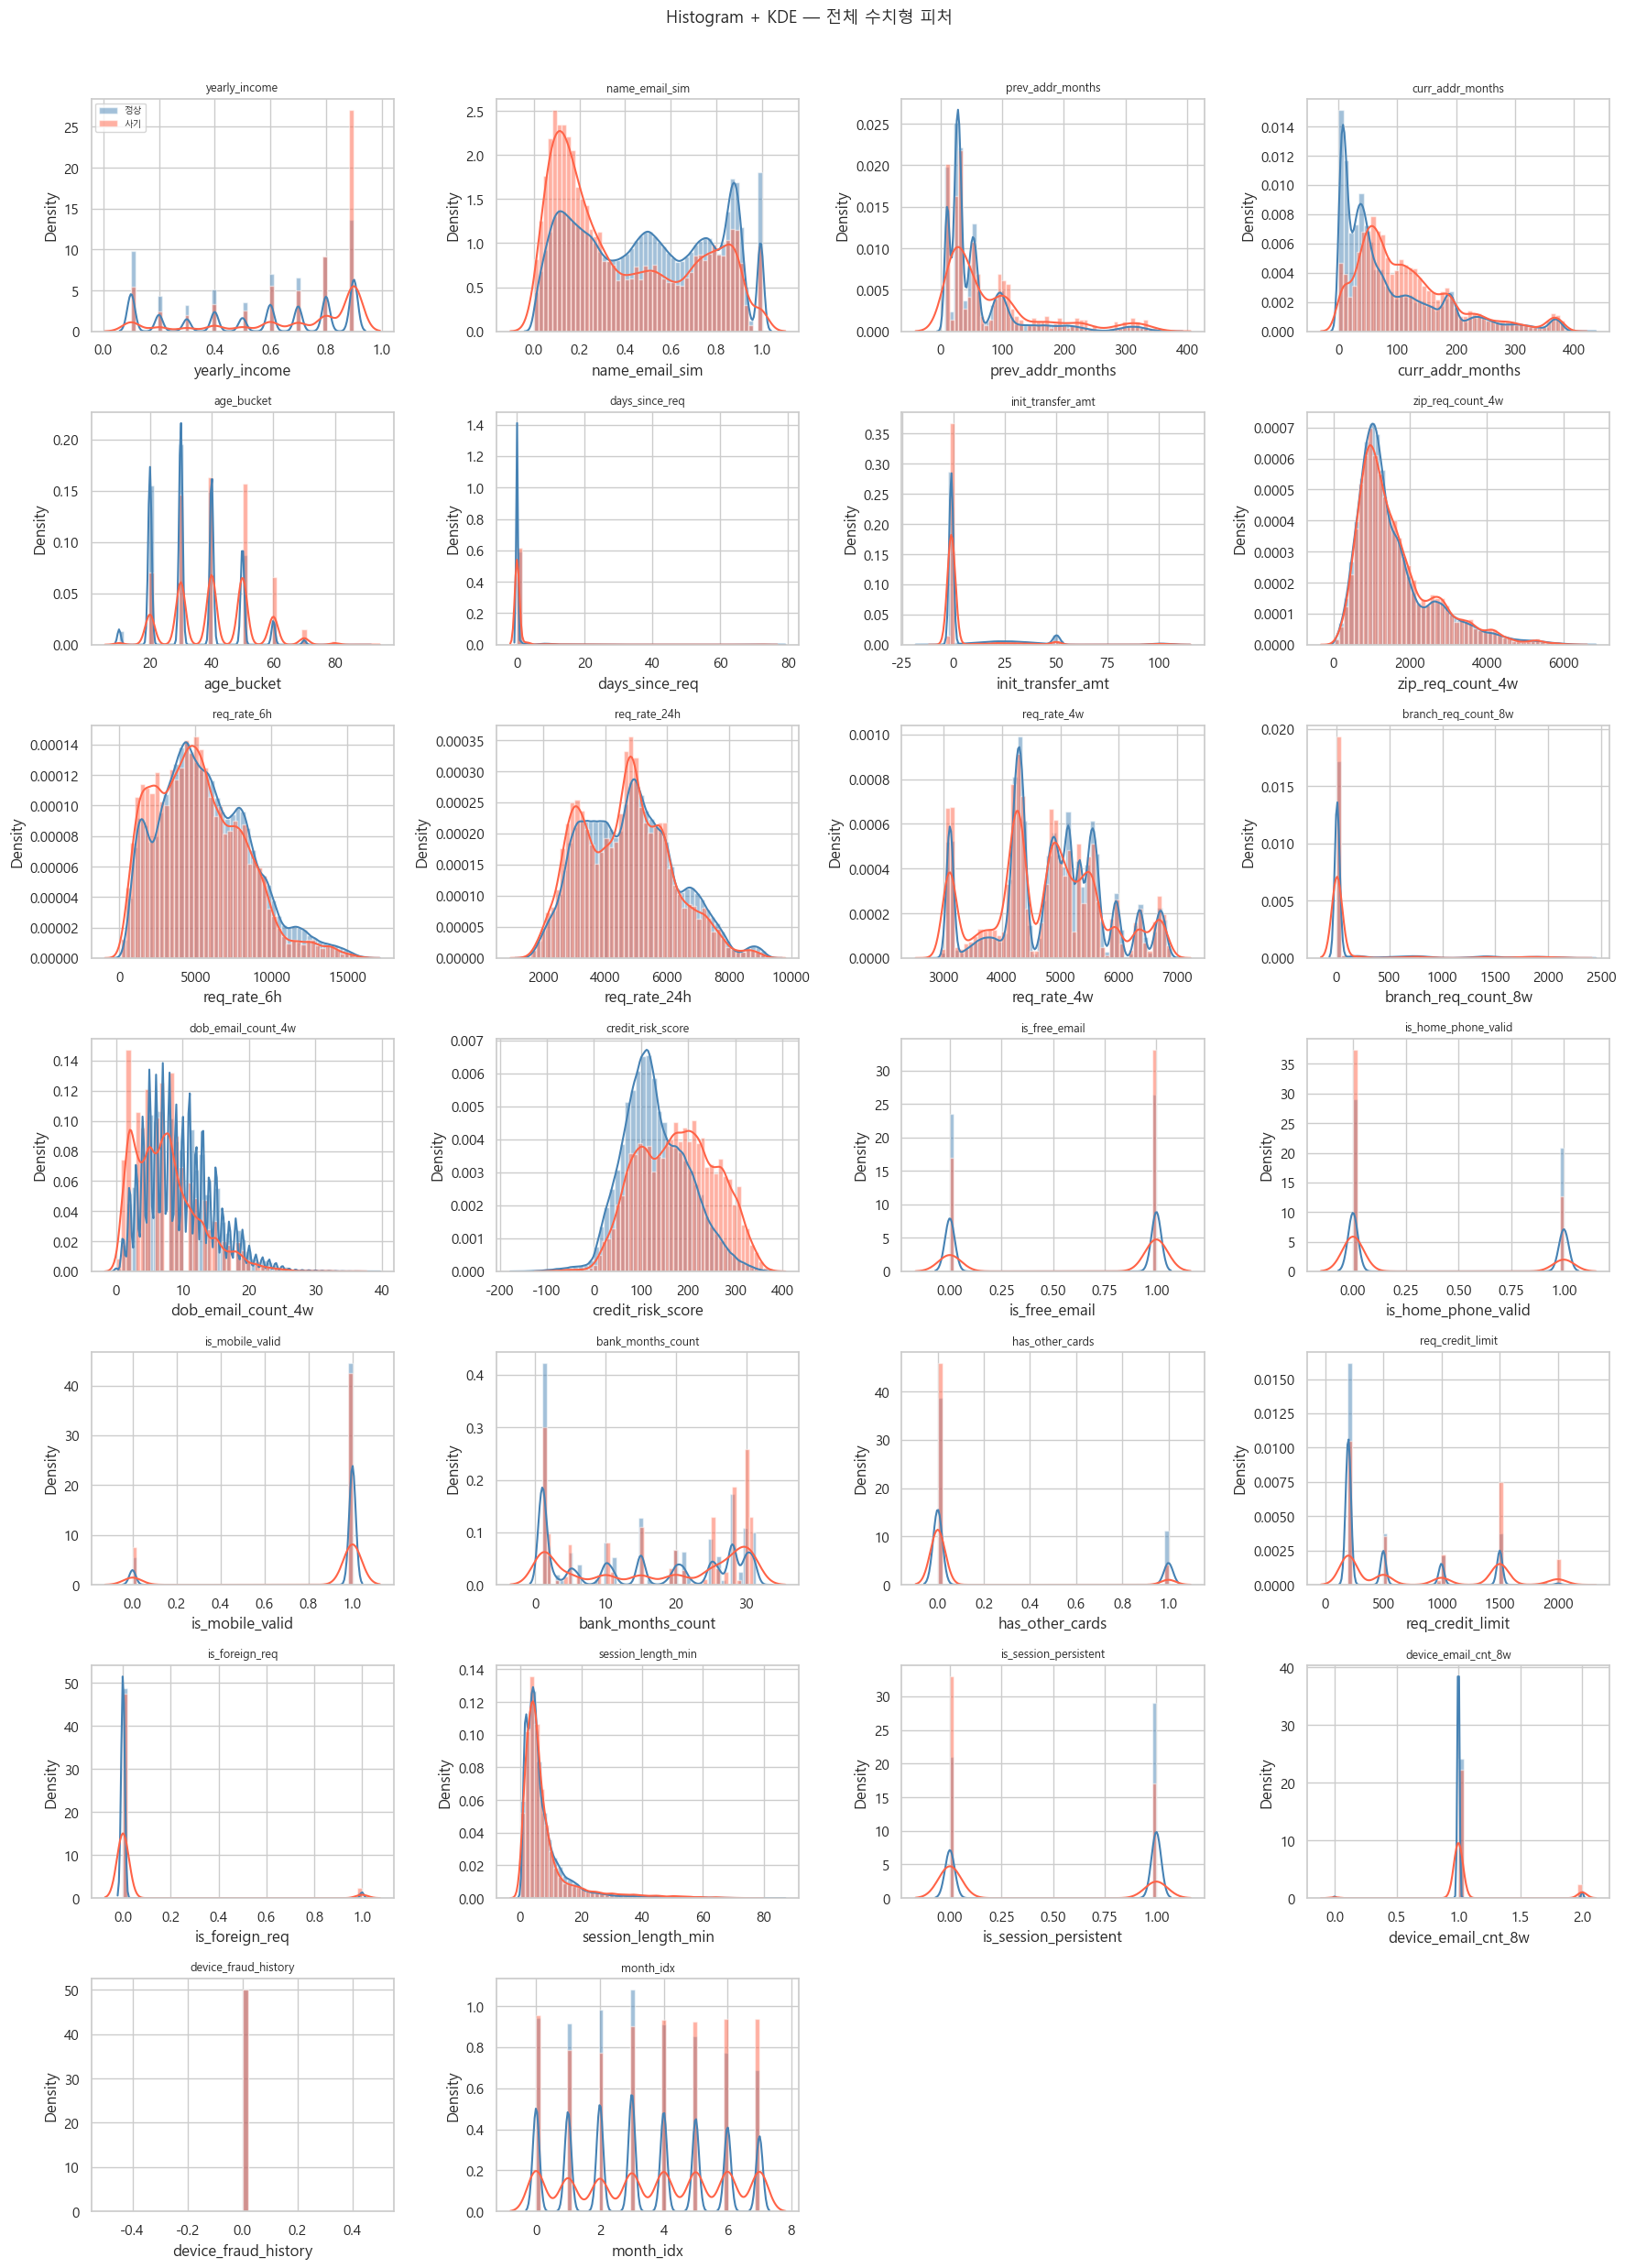

In [67]:
n = len(num_cols)
ncols = NCOLS_GRID
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 3.5))
axes = axes.flatten() if nrows > 1 else axes if n > 1 else [axes]

for i, col in enumerate(num_cols):
    ax = axes[i]
    vn = normal[col].replace(-1, np.nan).dropna()
    vf = fraud[col].replace(-1, np.nan).dropna()
    ax.hist(vn, bins=50, alpha=0.5, density=True, color='steelblue', label='정상')
    ax.hist(vf, bins=50, alpha=0.5, density=True, color='tomato',    label='사기')
    try:
        sns.kdeplot(vn, ax=ax, color='steelblue', bw_adjust=0.7, linewidth=1.5)
        sns.kdeplot(vf, ax=ax, color='tomato',    bw_adjust=0.7, linewidth=1.5)
    except Exception:
        pass
    ax.set_title(col, fontsize=9)
    if i == 0:
        ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Histogram + KDE — 전체 수치형 피처', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


### 1-2. ECDF / CDF by class — 전체 피처

**뭐 보여주나:** "이 값 이하가 전체의 몇 %인지" 누적 곡선. 두 클래스 곡선이 벌어지는 x 지점이 핵심.

**다음 단계:**
- 두 클래스 ECDF가 크게 벌어지는 x 값 → `x < τ` 이진 플래그 피처 (임계값 후보)
- 사기 곡선이 더 빨리 올라가면 → 해당 변수의 작은 값이 사기와 관련


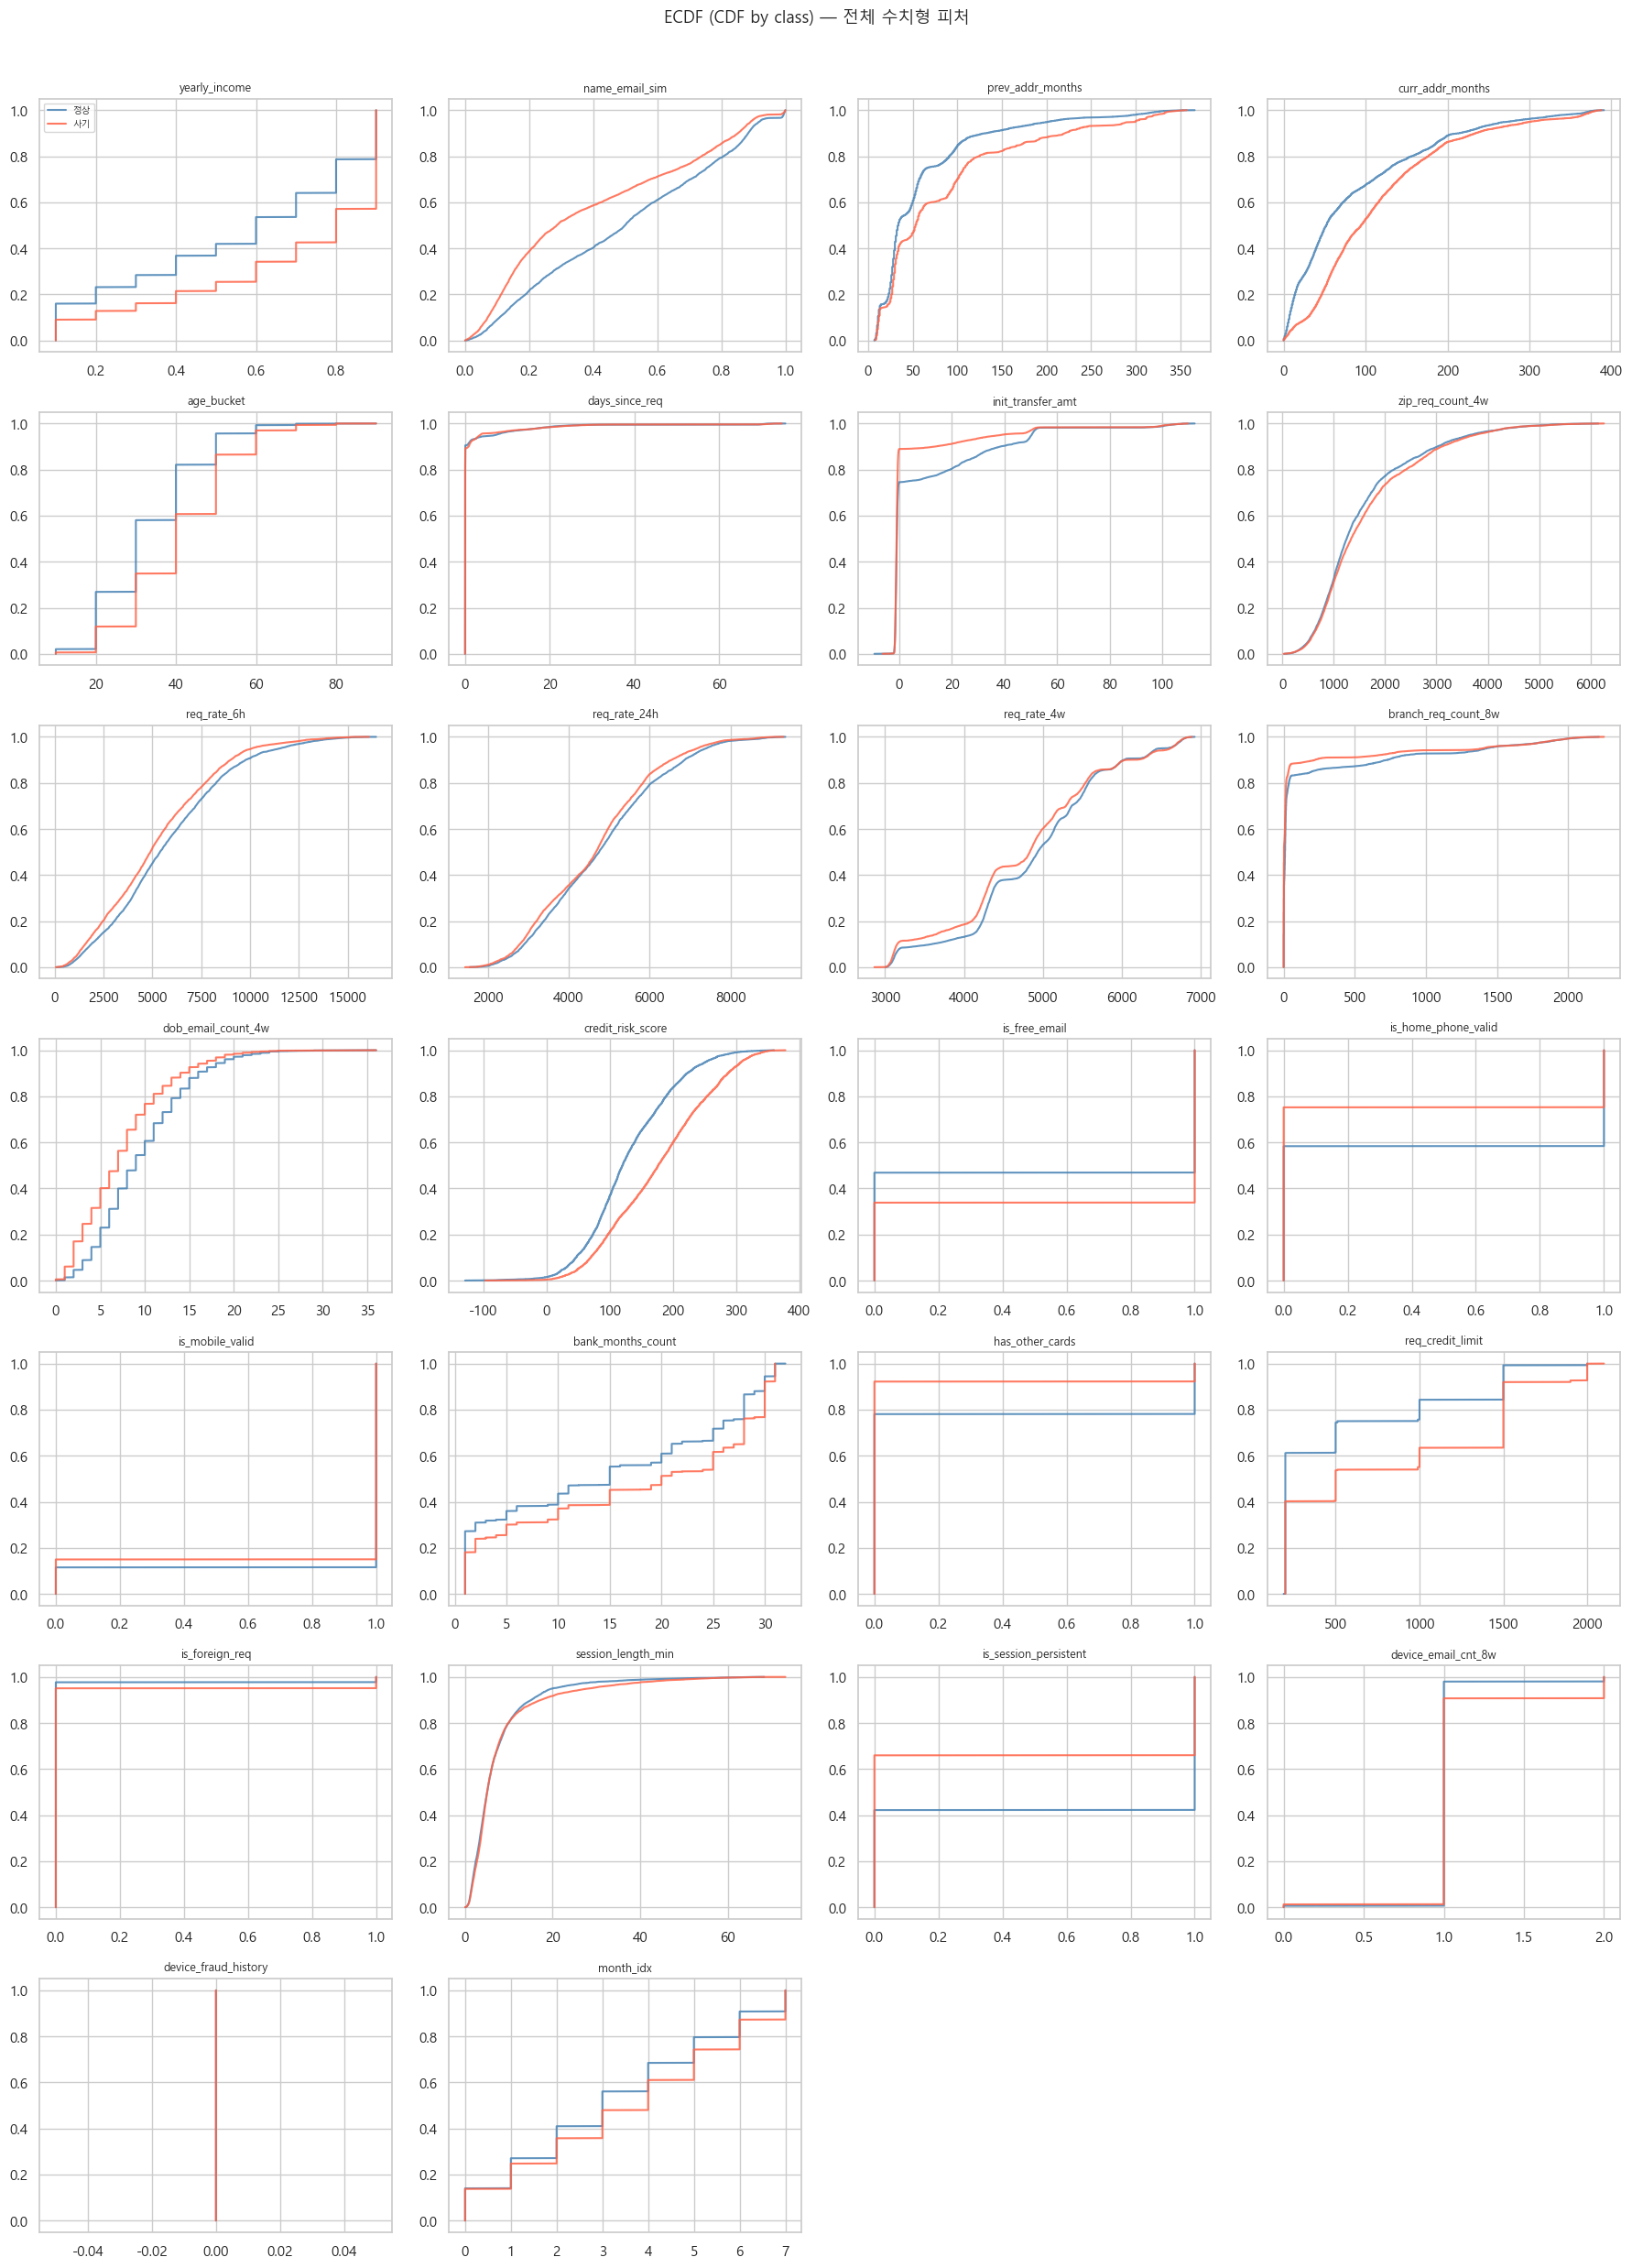

In [68]:
n = len(num_cols)
ncols = NCOLS_GRID
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 3.5))
axes = axes.flatten() if nrows > 1 else axes if n > 1 else [axes]

for i, col in enumerate(num_cols):
    ax = axes[i]
    for lbl, sub, c in [('정상', normal, 'steelblue'), ('사기', fraud, 'tomato')]:
        s = sub[col].replace(-1, np.nan).dropna()
        if len(s) == 0:
            continue
        s = np.sort(s.sample(min(5000, len(s)), random_state=SEED).values)
        y = np.arange(1, len(s) + 1) / len(s)
        ax.plot(s, y, color=c, label=lbl, lw=1.5, alpha=0.85)
    ax.set_title(col, fontsize=9)
    if i == 0:
        ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('ECDF (CDF by class) — 전체 수치형 피처', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


### 1-3. Box / Violin / Strip / Swarm — 전체 피처

**뭐 보여주나:**
- 전체 수평 박스플롯: 표준화 후 모든 피처를 한 그림에
- 피처별 바이올린: 각 변수의 분포 두께 + 클래스 비교

**다음 단계:**
- 중앙값이 클래스마다 다른 피처 → `quantile bin` 피처
- 사기에만 이상치가 몰리는 피처 → `outlier_flag` 파생


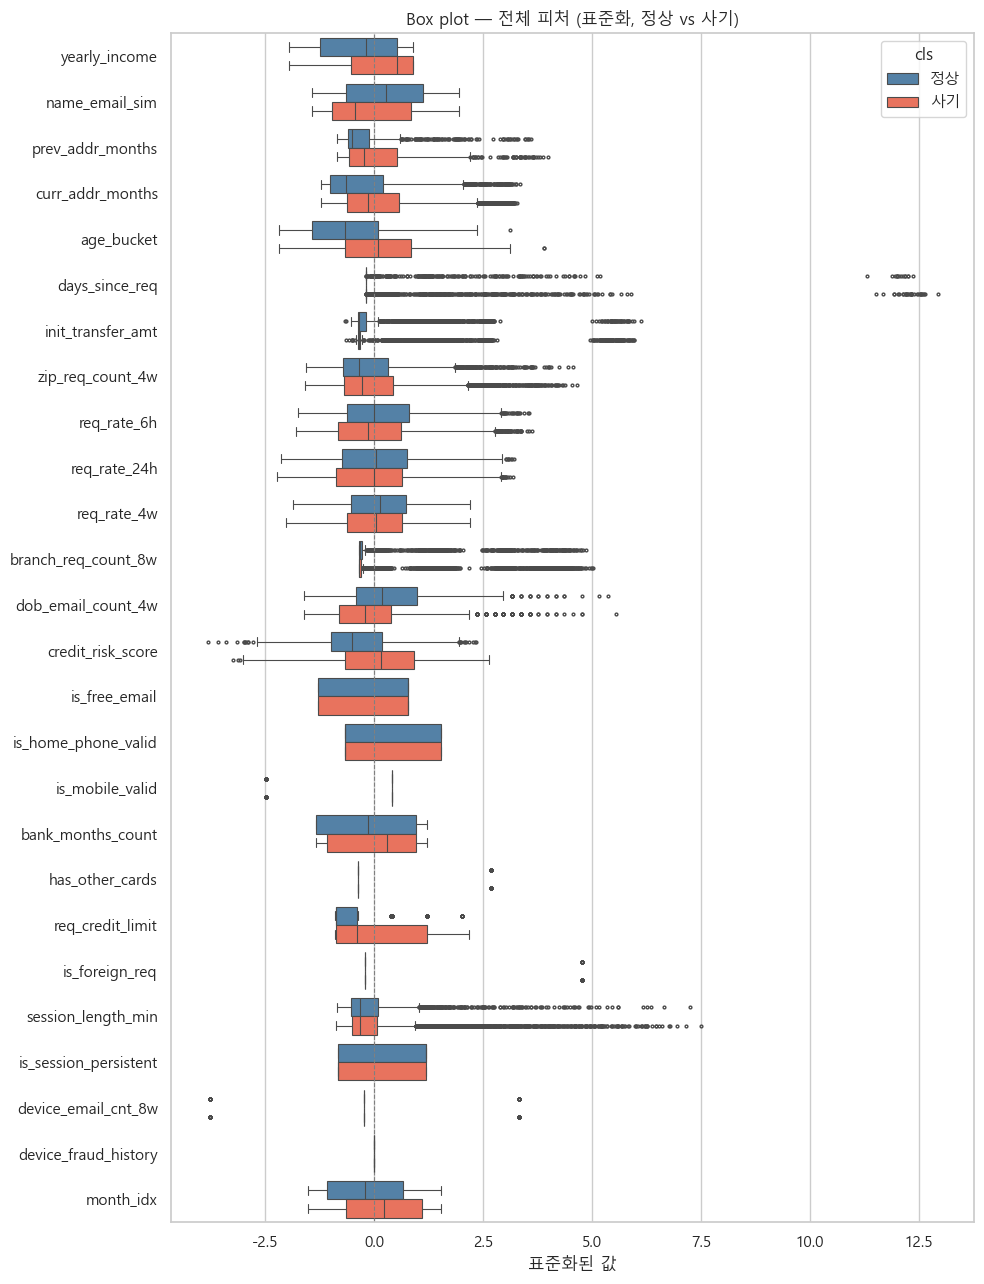

In [69]:
# ── 전체 피처 수평 Box plot (표준화) ──
samp_n = normal.sample(min(3000, len(normal)), random_state=SEED)[num_cols].assign(cls='정상')
samp_f = fraud[num_cols].assign(cls='사기')
df_all = pd.concat([samp_n, samp_f]).replace(-1, np.nan)

# 칼럼별 표준화
for col in num_cols:
    m, s = df_all[col].mean(), df_all[col].std()
    if s > 0:
        df_all[col] = (df_all[col] - m) / s

melted = df_all.melt(id_vars='cls', var_name='feature', value_name='value').dropna()

fig, ax = plt.subplots(figsize=(10, max(6, len(num_cols) * 0.5)))
sns.boxplot(data=melted, x='value', y='feature', hue='cls',
            palette={'정상': 'steelblue', '사기': 'tomato'}, ax=ax,
            linewidth=0.8, fliersize=2)
ax.set_title('Box plot — 전체 피처 (표준화, 정상 vs 사기)')
ax.set_xlabel('표준화된 값')
ax.set_ylabel('')
ax.axvline(0, color='gray', linestyle='--', lw=0.8)
plt.tight_layout()
plt.show()


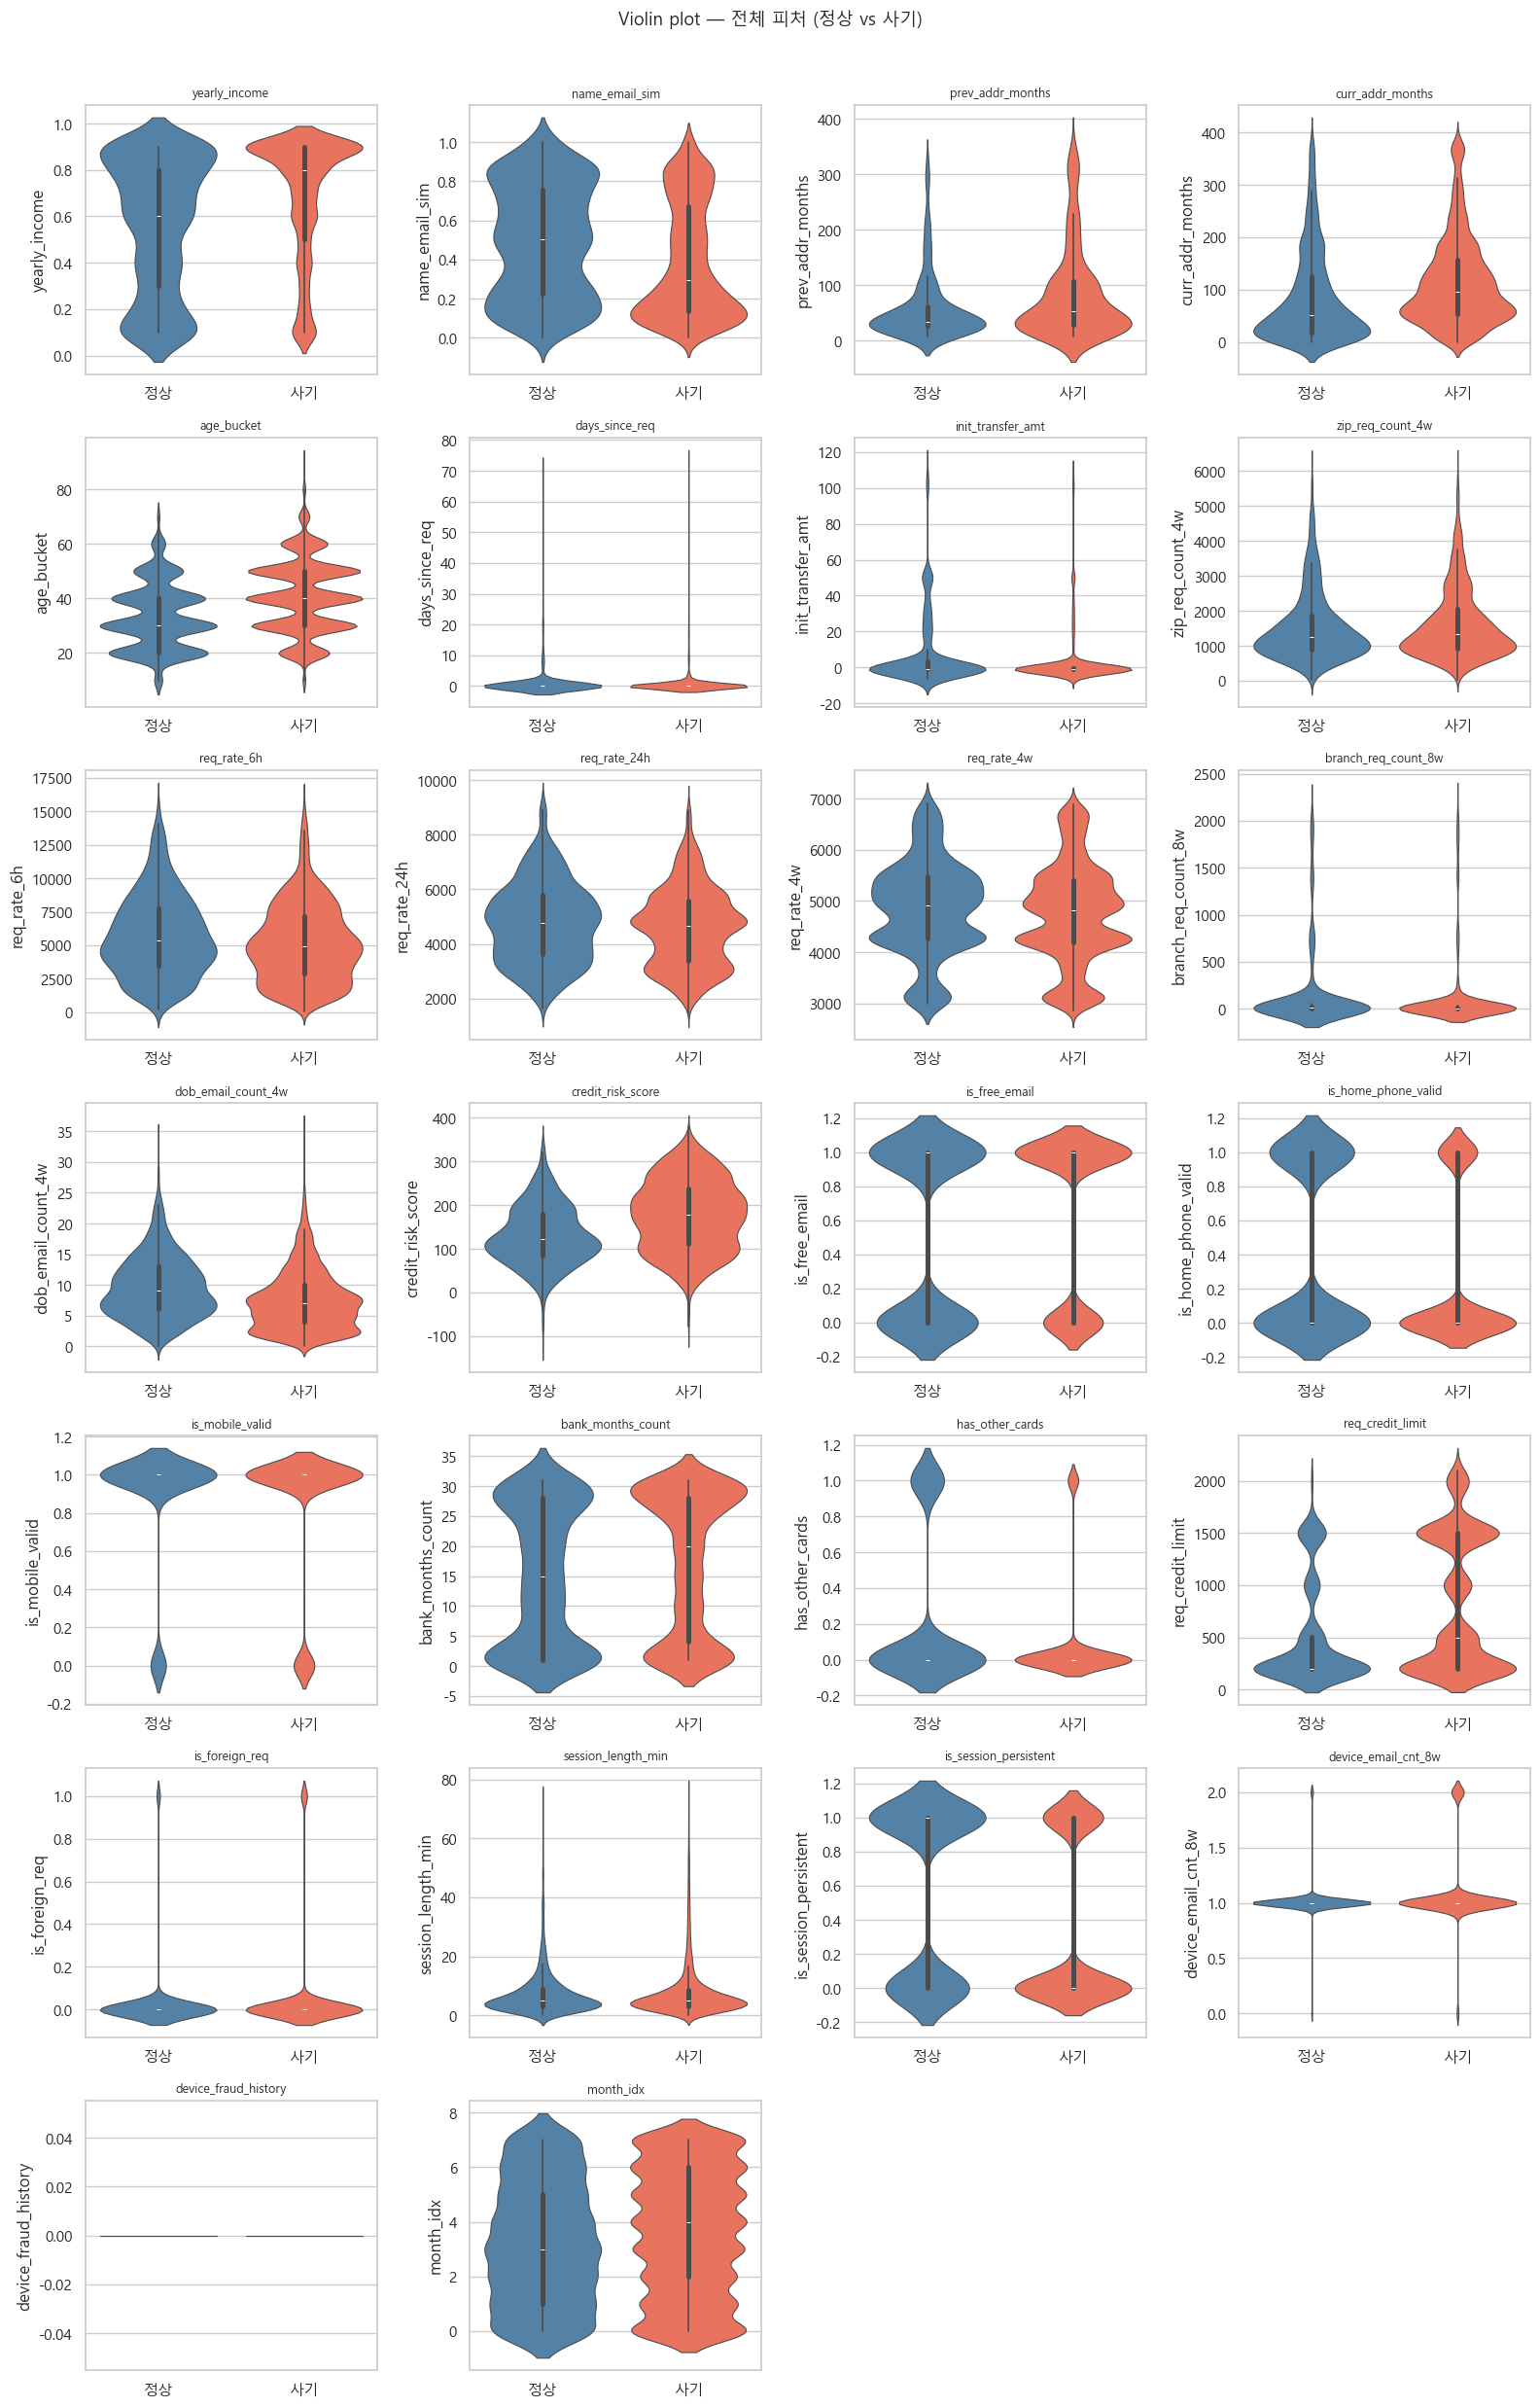

In [70]:
# ── 피처별 Violin plot 그리드 ──
n = len(num_cols)
ncols = NCOLS_GRID
nrows = (n + ncols - 1) // ncols

samp_n2 = normal.sample(min(2000, len(normal)), random_state=SEED)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.5))
axes = axes.flatten() if nrows > 1 else axes if n > 1 else [axes]

for i, col in enumerate(num_cols):
    ax = axes[i]
    df_v = pd.concat([
        samp_n2[[col, 'fraud_bool']],
        fraud[[col, 'fraud_bool']]
    ]).replace(-1, np.nan).dropna().rename(columns={'fraud_bool': 'cls'})
    df_v['cls'] = df_v['cls'].map({0: '정상', 1: '사기'})

    try:
        sns.violinplot(data=df_v, x='cls', y=col, ax=ax,
                       palette={'정상': 'steelblue', '사기': 'tomato'},
                       inner='box', linewidth=0.8)
    except Exception:
        sns.boxplot(data=df_v, x='cls', y=col, ax=ax,
                    palette={'정상': 'steelblue', '사기': 'tomato'})
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Violin plot — 전체 피처 (정상 vs 사기)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


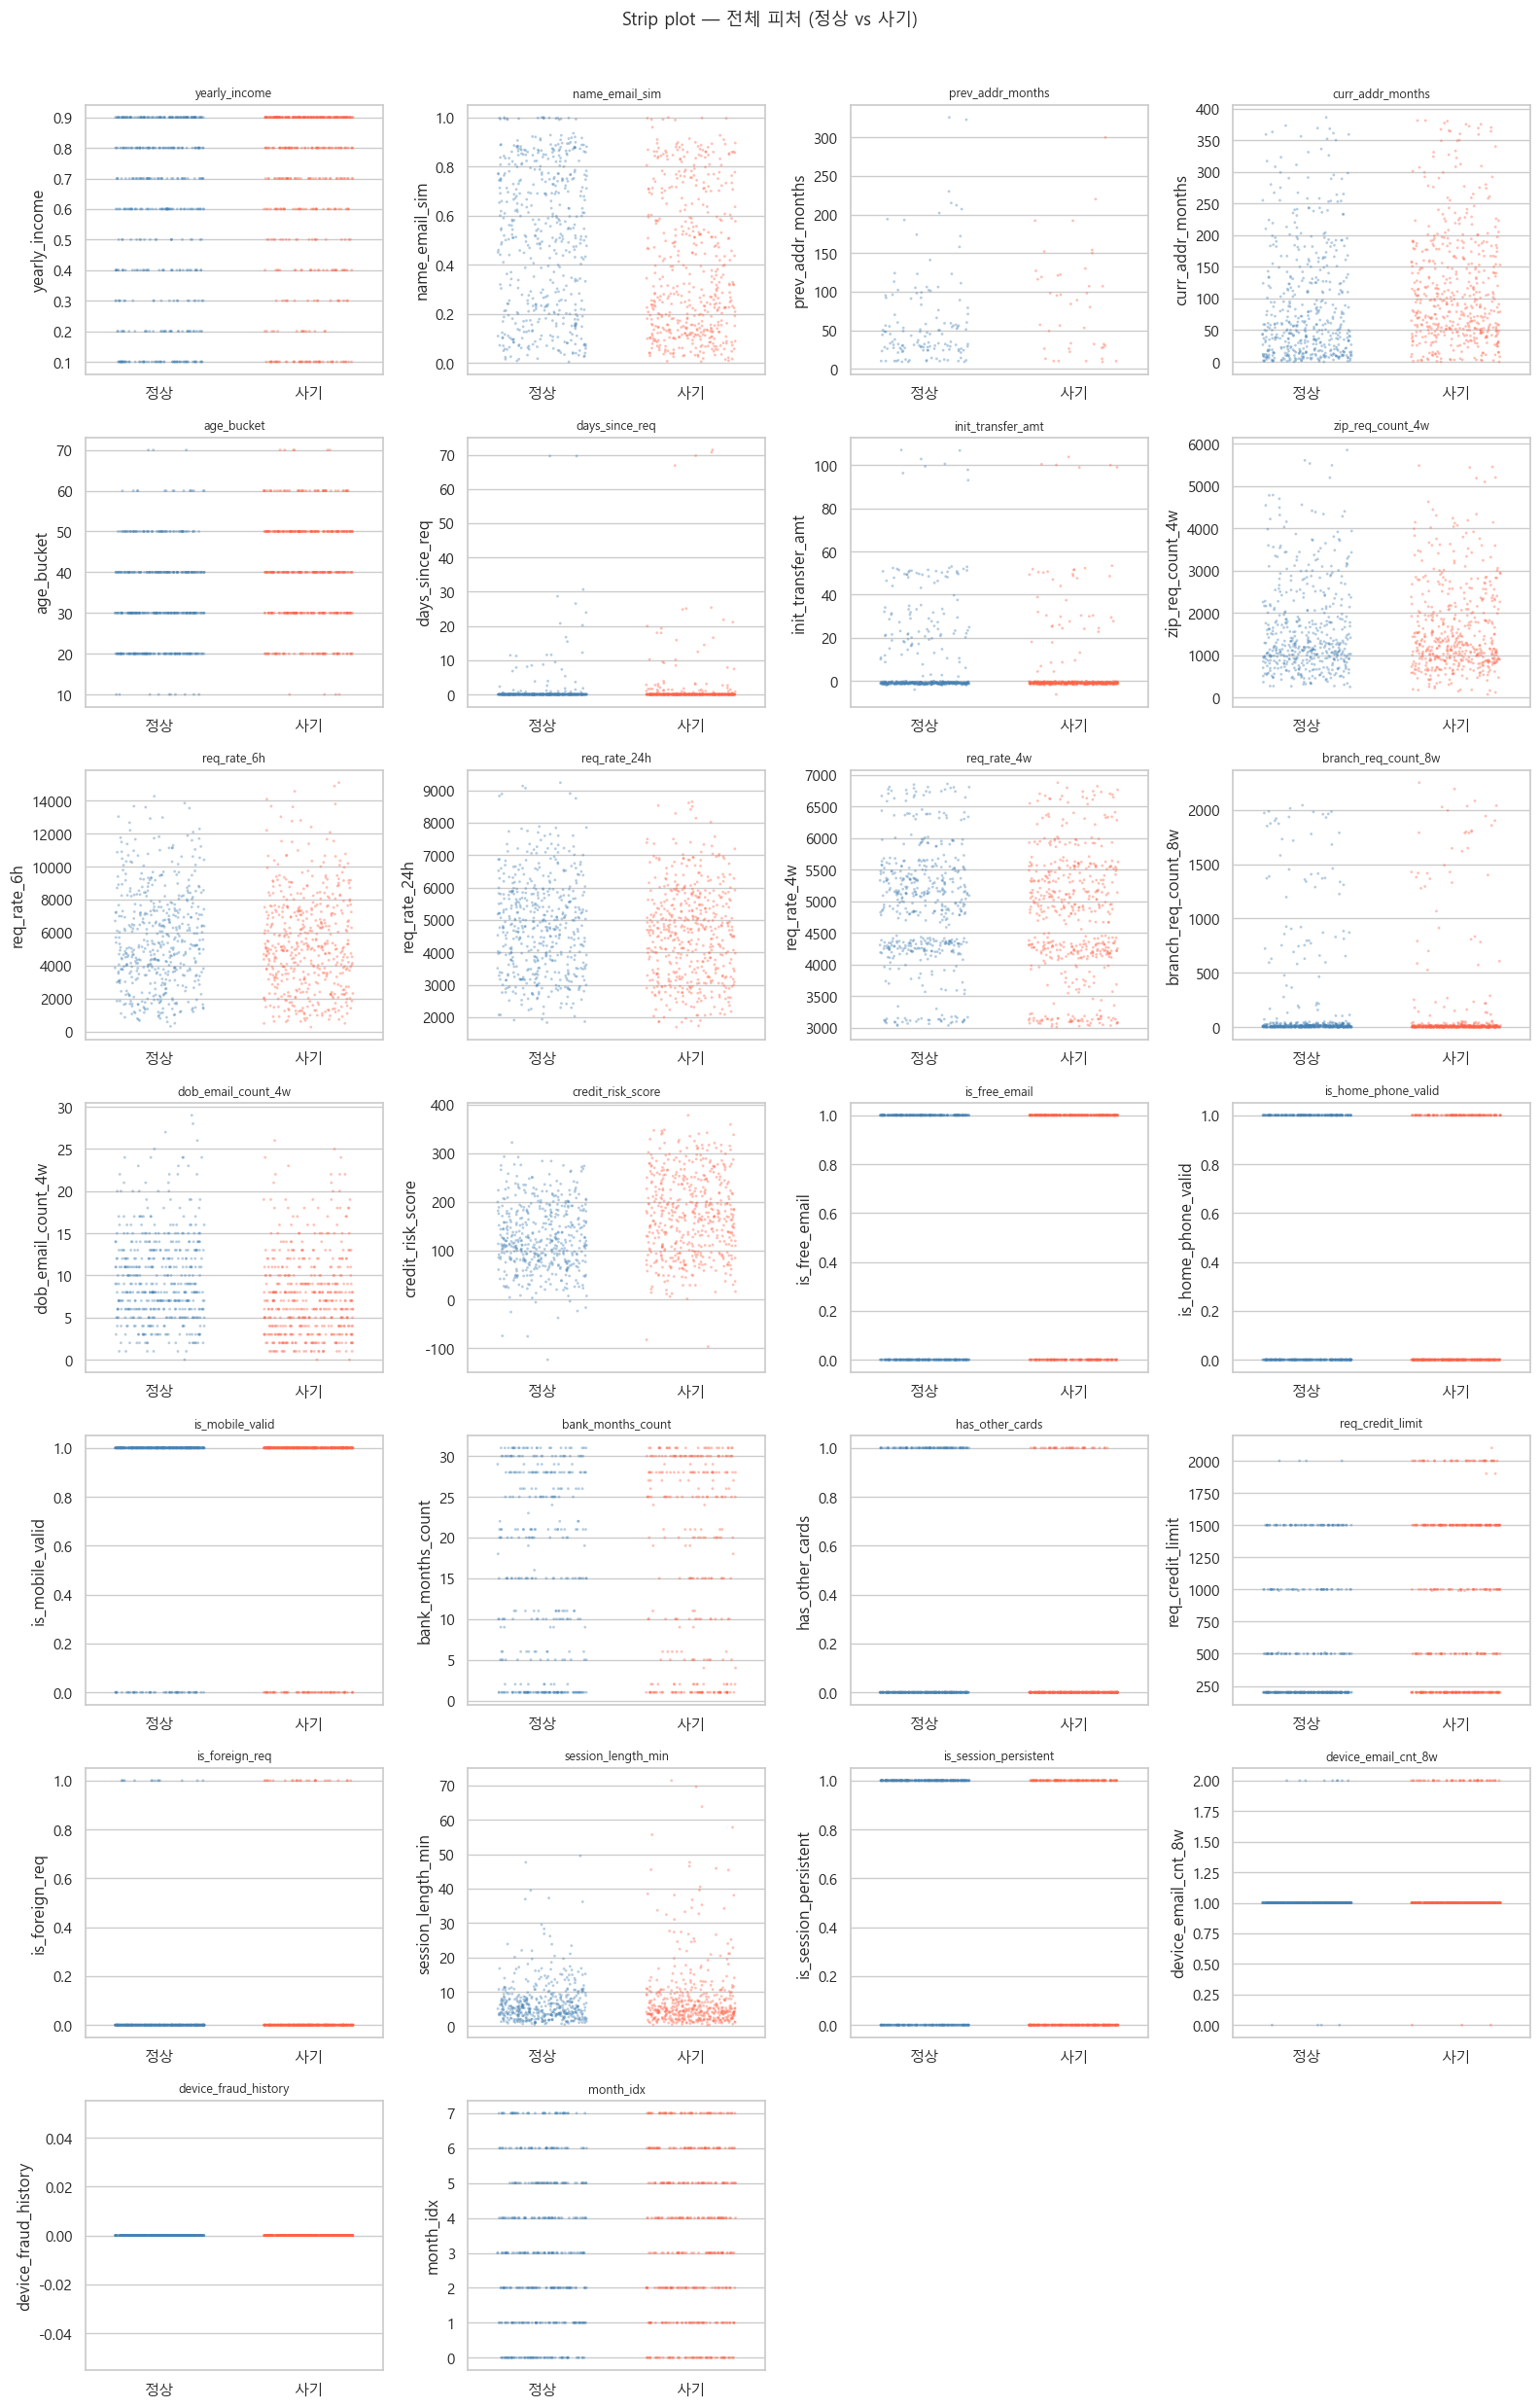

In [71]:
# ── 피처별 Strip plot 그리드 ──
n = len(num_cols)
ncols = NCOLS_GRID
nrows = (n + ncols - 1) // ncols

samp_n3 = normal.sample(min(500, len(normal)), random_state=SEED)
samp_f3 = fraud.sample(min(500, len(fraud)), random_state=SEED)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.5))
axes = axes.flatten() if nrows > 1 else axes if n > 1 else [axes]

for i, col in enumerate(num_cols):
    ax = axes[i]
    df_s = pd.concat([
        samp_n3[[col, 'fraud_bool']],
        samp_f3[[col, 'fraud_bool']]
    ]).replace(-1, np.nan).dropna().rename(columns={'fraud_bool': 'cls'})
    df_s['cls'] = df_s['cls'].map({0: '정상', 1: '사기'})
    sns.stripplot(data=df_s, x='cls', y=col, ax=ax,
                  palette={'정상': 'steelblue', '사기': 'tomato'},
                  alpha=0.4, jitter=0.3, size=2)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Strip plot — 전체 피처 (정상 vs 사기)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


### 1-4. Ridgeline / QQ plot — 전체 피처

**뭐 보여주나:**
- Ridgeline: 전체 수치형 변수 분포를 봉우리로 겹쳐 형태 비교
- QQ plot: 각 변수가 정규분포와 얼마나 다른지

**다음 단계:**
- QQ plot이 크게 꺾이는 변수 → log·BoxCox 변환 후 재확인
- Ridgeline에서 특이하게 뾰족하거나 치우친 변수 → 우선 변환 대상


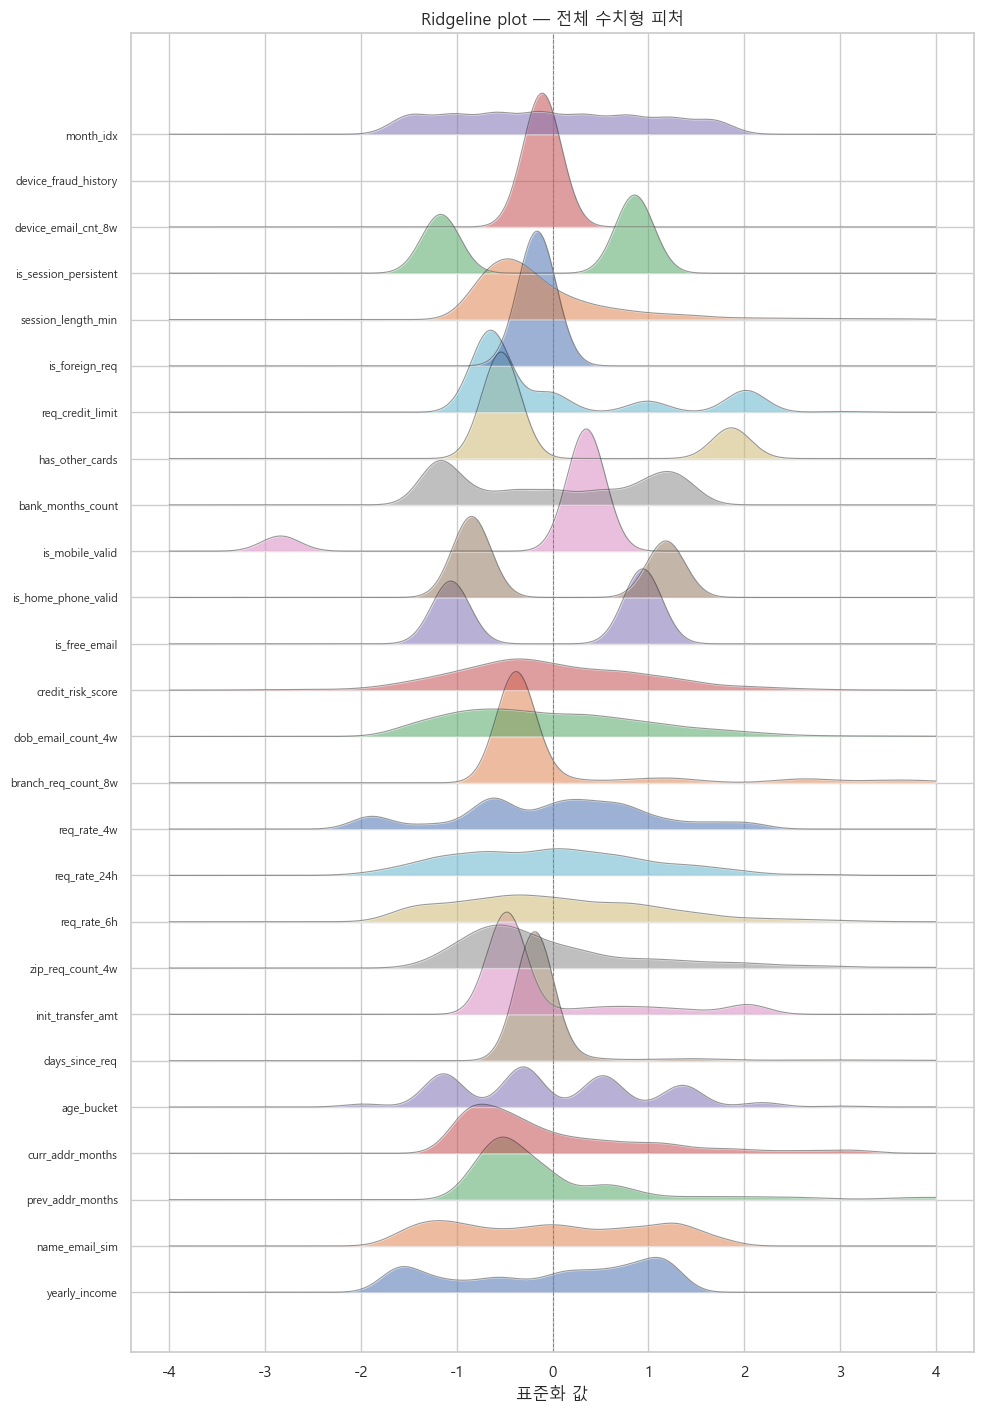

In [72]:
# ── Ridgeline — 전체 피처 ──
fig, ax = plt.subplots(figsize=(10, max(6, len(num_cols) * 0.55)))

for j, col in enumerate(num_cols):
    s = train[col].replace(-1, np.nan).dropna()
    if len(s) < 10 or s.std() == 0:
        continue
    s_norm = (s - s.mean()) / s.std()
    try:
        kde = stats.gaussian_kde(s_norm.sample(min(3000, len(s_norm)), random_state=SEED))
        xs = np.linspace(-4, 4, 300)
        ys = kde(xs) * 1.5
        ax.fill_between(xs, j + ys, j, alpha=0.55)
        ax.plot(xs, j + ys, lw=0.8, color='black', alpha=0.4)
    except Exception:
        pass

ax.set_yticks(range(len(num_cols)))
ax.set_yticklabels(num_cols, fontsize=8)
ax.set_xlabel('표준화 값')
ax.set_title('Ridgeline plot — 전체 수치형 피처')
ax.axvline(0, color='gray', linestyle='--', lw=0.7)
plt.tight_layout()
plt.show()


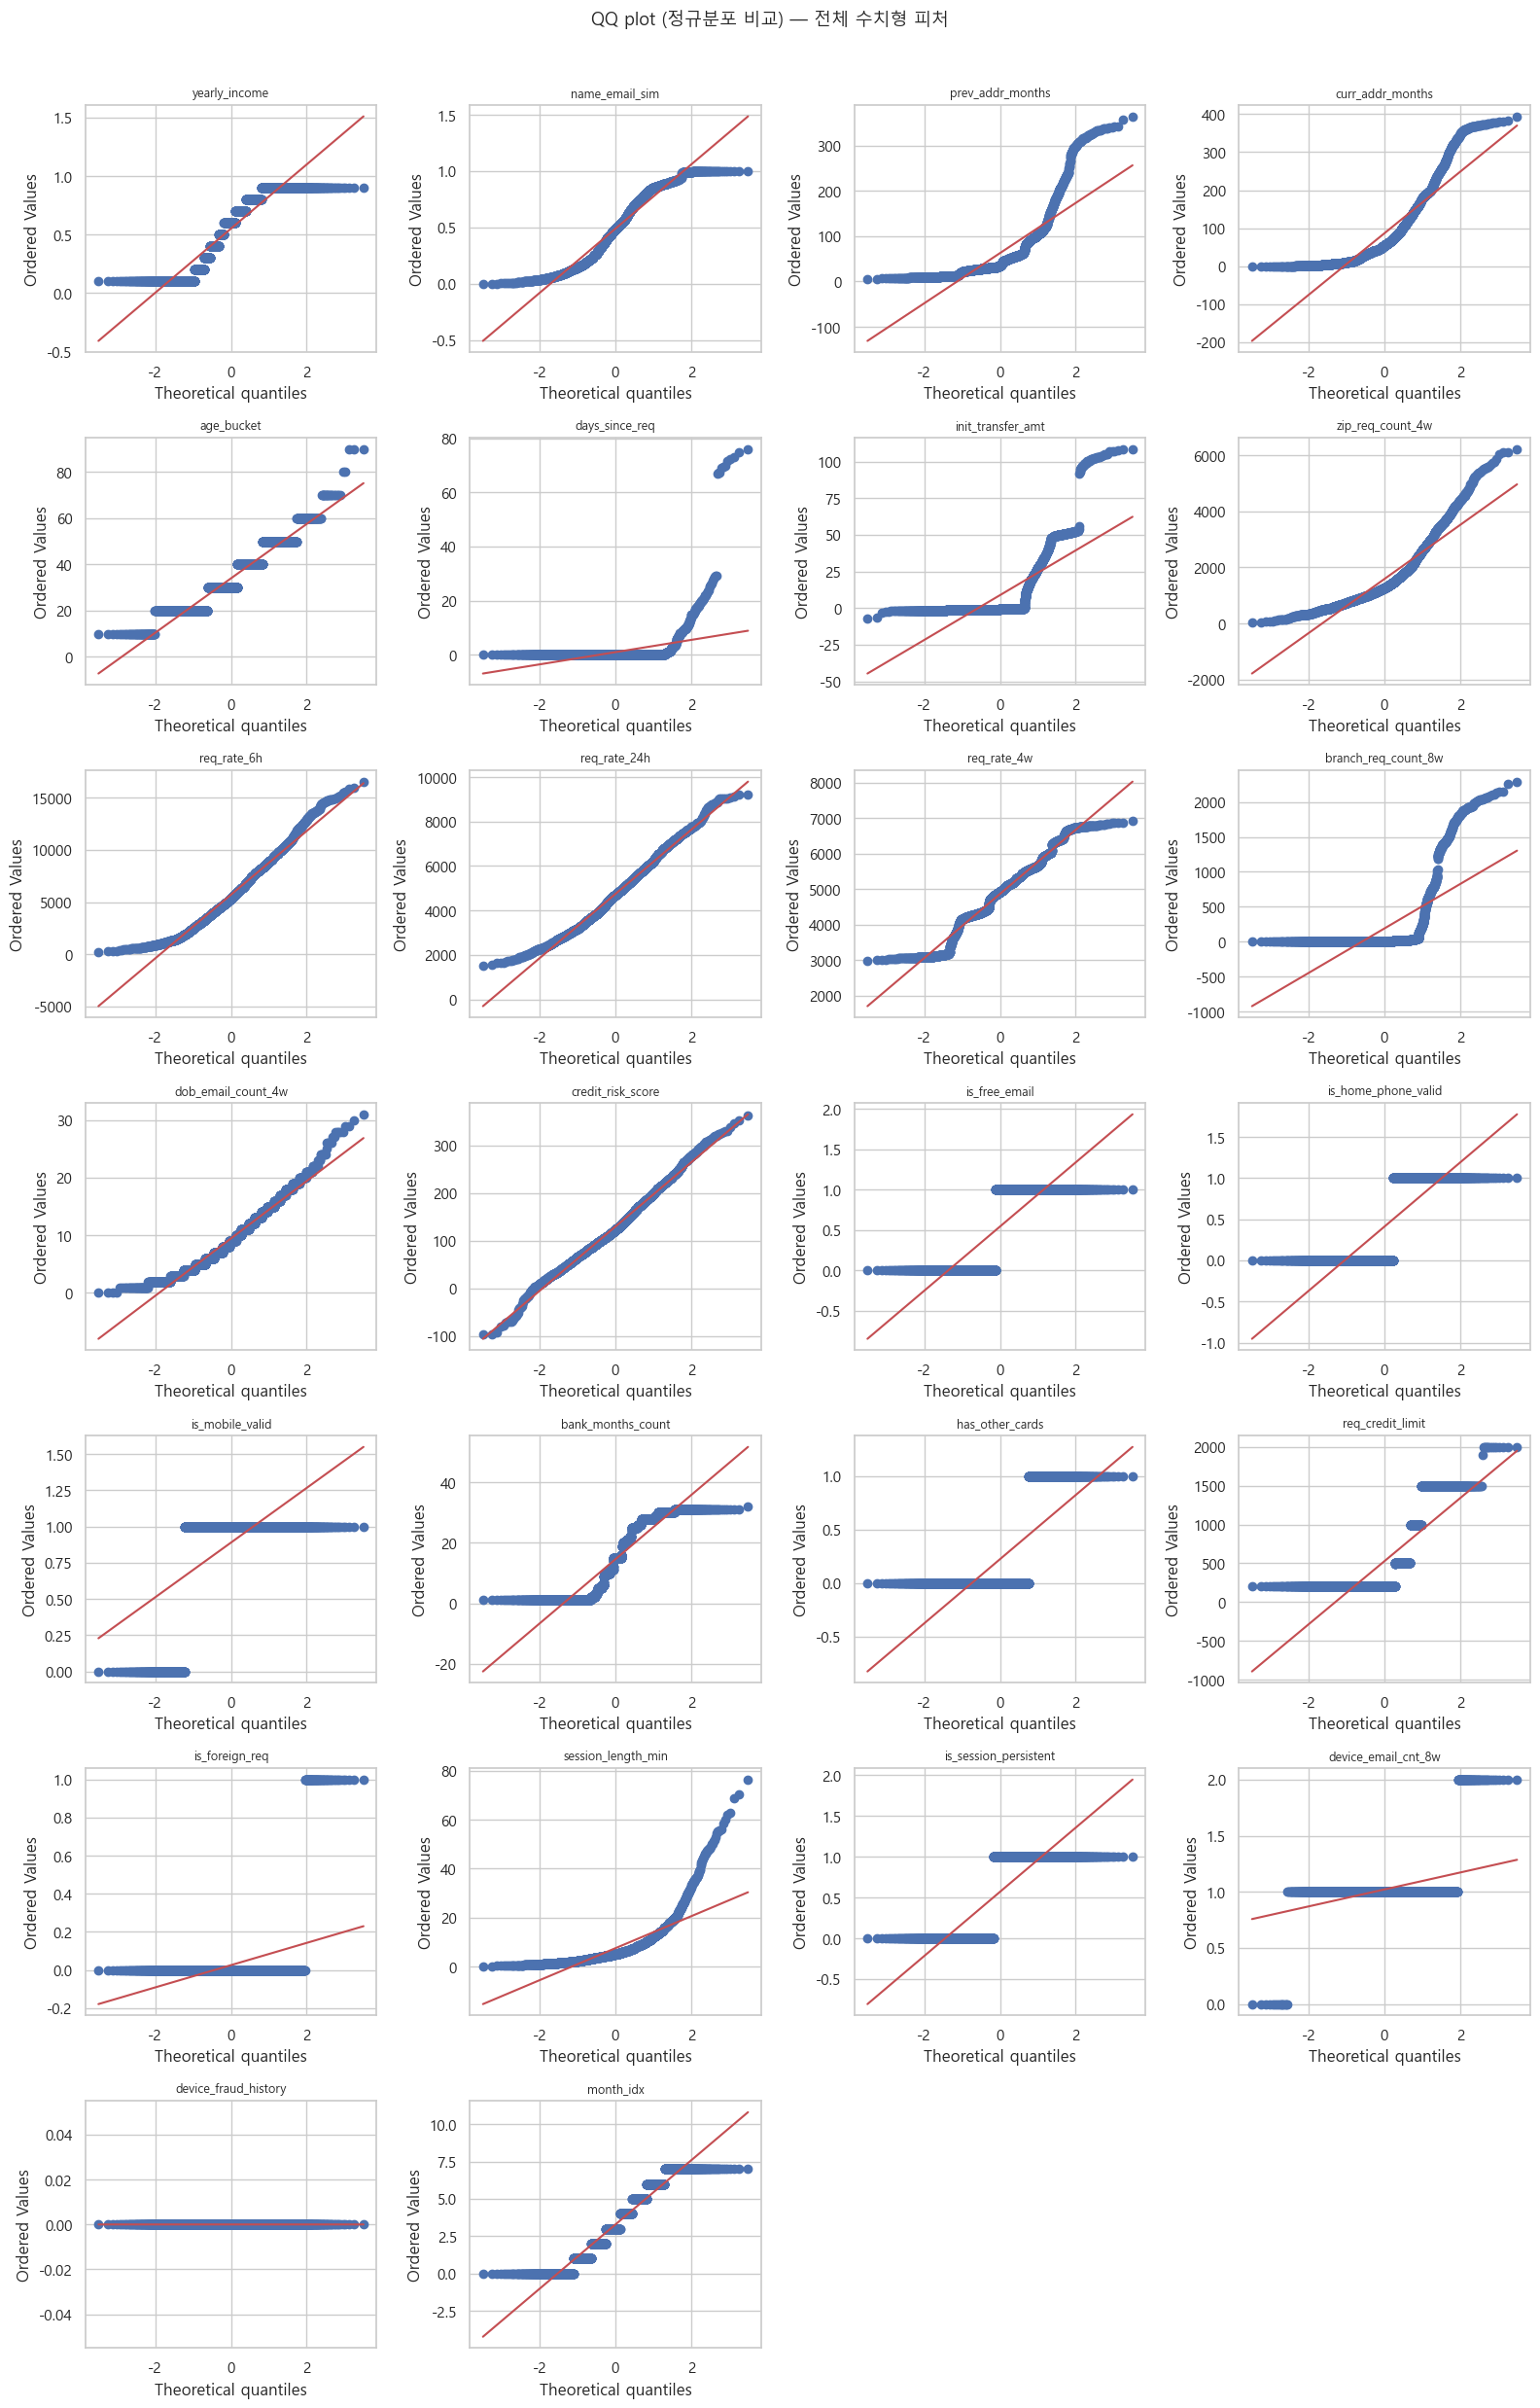

In [73]:
# ── QQ plot 그리드 — 전체 피처 ──
n = len(num_cols)
ncols = NCOLS_GRID
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.5))
axes = axes.flatten() if nrows > 1 else axes if n > 1 else [axes]

for i, col in enumerate(num_cols):
    ax = axes[i]
    vals = train[col].replace(-1, np.nan).dropna()
    if len(vals) < 5:
        ax.set_visible(False)
        continue
    try:
        stats.probplot(vals.sample(min(3000, len(vals)), random_state=SEED),
                       dist='norm', plot=ax)
    except Exception:
        ax.text(0.5, 0.5, 'QQ 계산 실패', transform=ax.transAxes, ha='center')
    ax.set_title(col, fontsize=9)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('QQ plot (정규분포 비교) — 전체 수치형 피처', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


### 1-5. Missingness / Cardinality / Skewness / Outlier ratio

**뭐 보여주나:**
- Missingness: -1 센티넬 포함 빈 값 비율
- Cardinality: 각 칼럼의 고유값 개수
- Skewness: 분포 비대칭 정도
- Outlier ratio: IQR 기준 극단값 비율

**다음 단계:**
- Missingness 큰 칼럼 → `is_missing` 플래그 피처 추가
- |Skewness| > 1 → log 변환 우선 시도
- Outlier ratio 높은 칼럼 → clip 또는 Robust Scaler


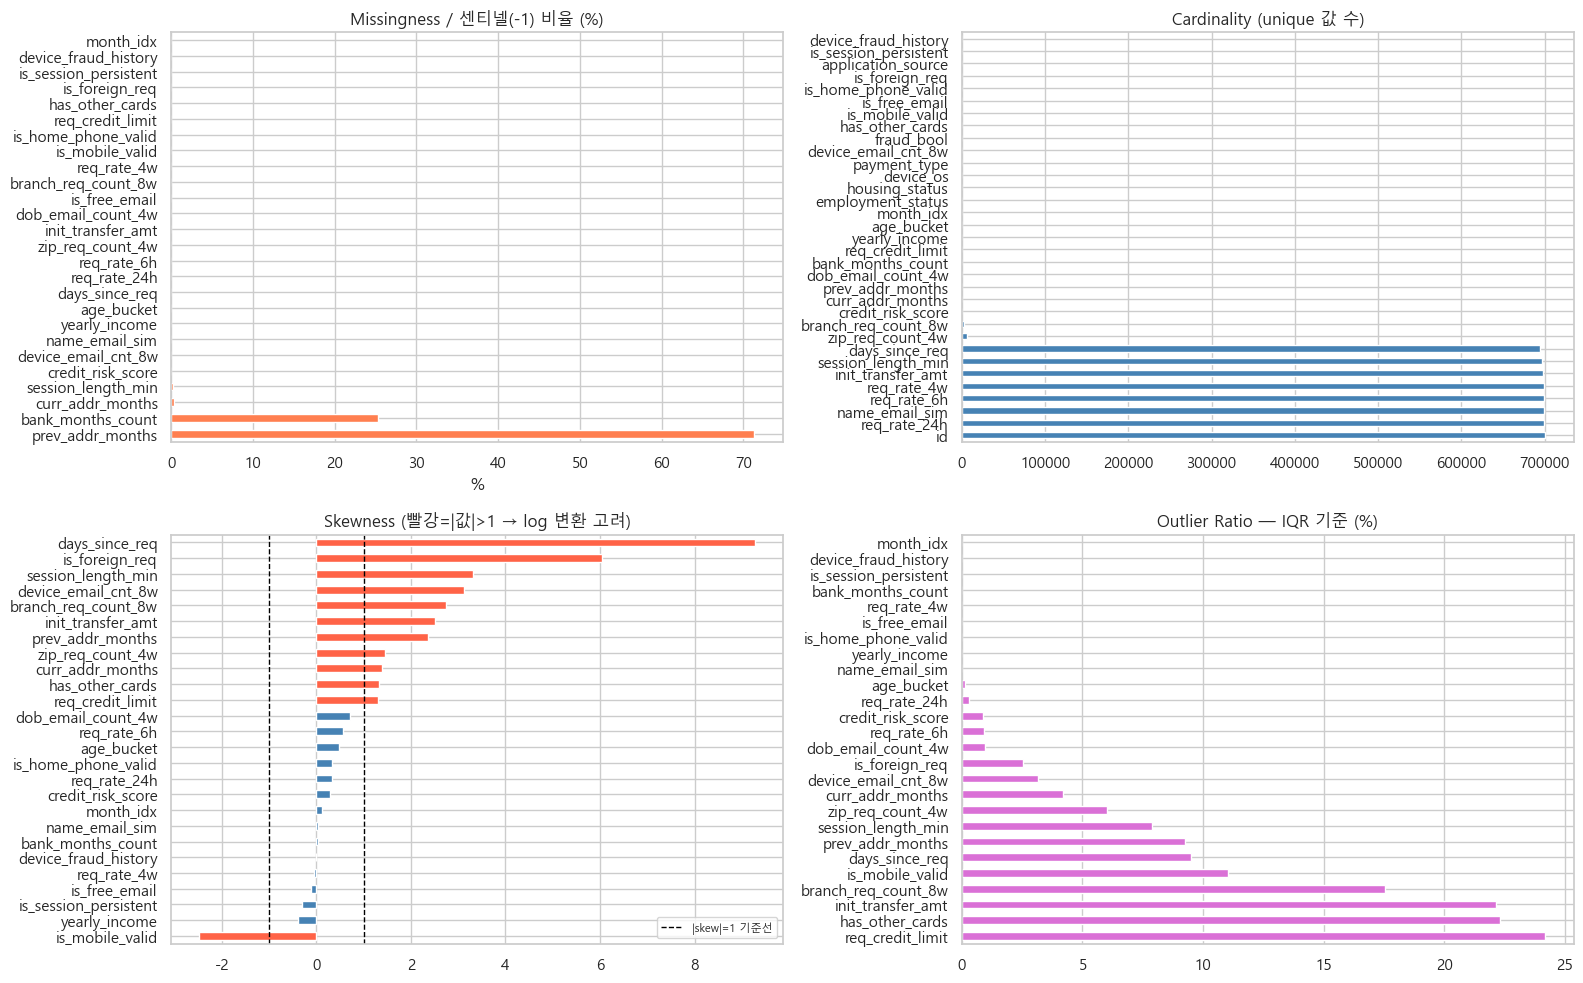

In [74]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Missingness (-1 포함)
miss = {c: ((train[c] == -1) | train[c].isna()).mean() * 100 for c in num_cols}
miss_s = pd.Series(miss).sort_values(ascending=False)
miss_s.plot.barh(ax=axes[0, 0], color='coral')
axes[0, 0].set_title('Missingness / 센티넬(-1) 비율 (%)')
axes[0, 0].set_xlabel('%')

# Cardinality
card = pd.Series({c: train[c].nunique() for c in train.columns}).sort_values(ascending=False)
card.plot.barh(ax=axes[0, 1], color='steelblue')
axes[0, 1].set_title('Cardinality (unique 값 수)')

# Skewness
skew = train[num_cols].replace(-1, np.nan).skew().sort_values()
colors_sk = ['tomato' if abs(v) > 1 else 'steelblue' for v in skew]
skew.plot.barh(ax=axes[1, 0], color=colors_sk)
axes[1, 0].axvline(1,  color='black', linestyle='--', lw=1)
axes[1, 0].axvline(-1, color='black', linestyle='--', lw=1, label='|skew|=1 기준선')
axes[1, 0].set_title('Skewness (빨강=|값|>1 → log 변환 고려)')
axes[1, 0].legend(fontsize=8)

# Outlier ratio
out_pct = {}
for c in num_cols:
    s = train[c].replace(-1, np.nan).dropna()
    if len(s) < 10:
        continue
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    out_pct[c] = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
pd.Series(out_pct).sort_values(ascending=False).plot.barh(ax=axes[1, 1], color='orchid')
axes[1, 1].set_title('Outlier Ratio — IQR 기준 (%)')

plt.tight_layout()
plt.show()


### 1-6. Z-score scatter / IQR whisker — 전체 피처

**뭐 보여주나:**
- Z-score scatter: 모든 수치형을 표준화한 뒤 |z|>3 극단값 히트맵
- IQR whisker: 모든 피처의 클래스별 수염 끝 비교

**다음 단계:**
- 사기에만 |z|>3 값이 몰리는 피처 → `extreme_flag` 이진 피처
- whisker 범위 차이가 큰 피처 → `quantile rank` 또는 clip 후 log


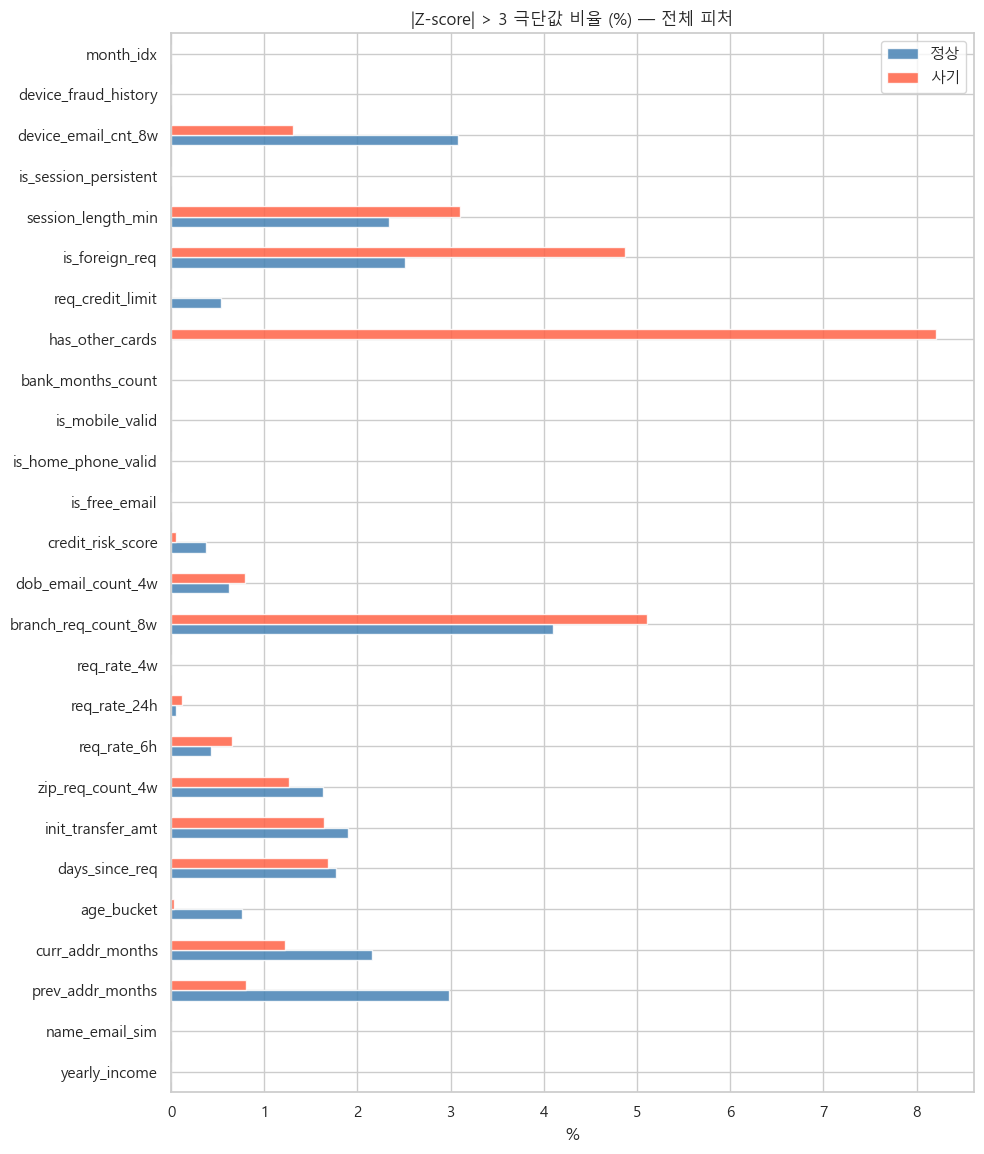

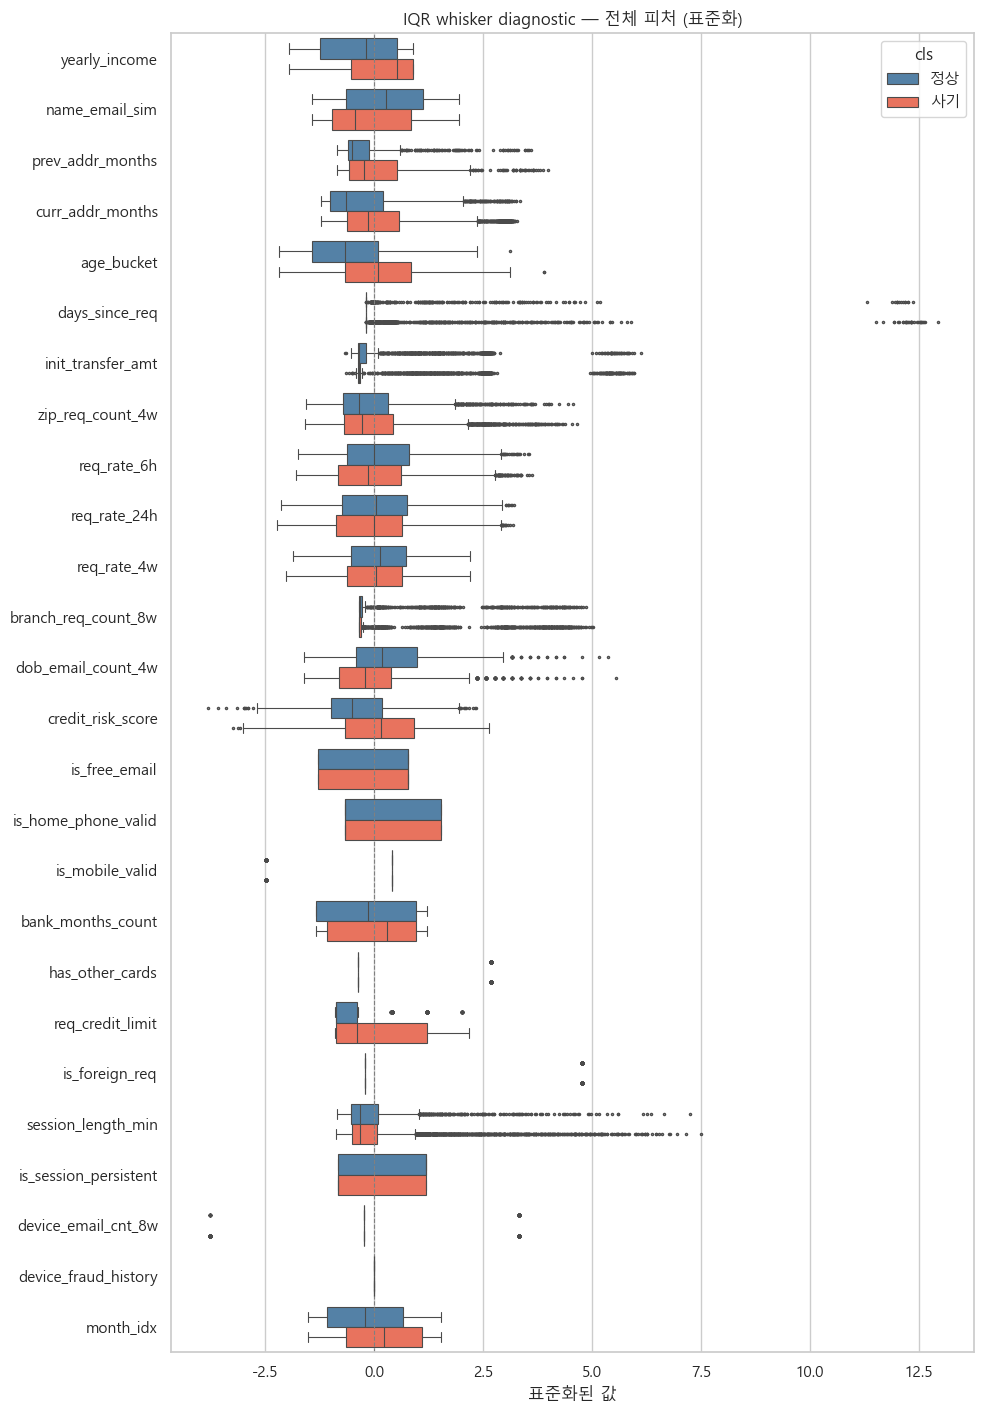

In [75]:
# ── Z-score 극단값 비율 (피처별, 클래스별) ──
z_ext = {}
for col in num_cols:
    for lbl, sub in [('정상', normal), ('사기', fraud)]:
        v = sub[col].replace(-1, np.nan).dropna()
        if len(v) < 10:
            continue
        z = (v - v.mean()) / v.std()
        z_ext.setdefault(col, {})[lbl] = (z.abs() > 3).mean() * 100

if z_ext:
    z_df = pd.DataFrame(z_ext).T.fillna(0)
    fig, ax = plt.subplots(figsize=(10, max(5, len(num_cols) * 0.45)))
    z_df.plot.barh(ax=ax, color=['steelblue', 'tomato'], alpha=0.85)
    ax.set_title('|Z-score| > 3 극단값 비율 (%) — 전체 피처')
    ax.set_xlabel('%')
    plt.tight_layout()
    plt.show()

# ── IQR whisker diagnostic — 전체 피처 (표준화 후 수평 박스) ──
samp_n = normal.sample(min(3000, len(normal)), random_state=SEED)
df_iqr = pd.concat([
    samp_n[num_cols].replace(-1, np.nan).assign(cls='정상'),
    fraud[num_cols].replace(-1, np.nan).assign(cls='사기')
])
for col in num_cols:
    m, s = df_iqr[col].mean(), df_iqr[col].std()
    if s > 0:
        df_iqr[col] = (df_iqr[col] - m) / s

melted_iqr = df_iqr.melt(id_vars='cls', var_name='feature', value_name='value').dropna()

fig, ax = plt.subplots(figsize=(10, max(6, len(num_cols) * 0.55)))
sns.boxplot(data=melted_iqr, x='value', y='feature', hue='cls',
            palette={'정상': 'steelblue', '사기': 'tomato'},
            ax=ax, linewidth=0.8, fliersize=1.5, showfliers=True)
ax.axvline(0, color='gray', linestyle='--', lw=0.8)
ax.set_title('IQR whisker diagnostic — 전체 피처 (표준화)')
ax.set_xlabel('표준화된 값')
ax.set_ylabel('')
plt.tight_layout()
plt.show()


---
## 2) 두 변수 관계 — 수치 × 수치


### 2-1. Scatter / Bubble / Regression line — 상위 상관 쌍

타겟(fraud_bool)과 상관이 높은 상위 변수들끼리 산점도를 그립니다.

**다음 단계:**
- 두 변수가 직선에 가깝다면 → 하나 제거 또는 비율 피처로 압축
- 사기가 회귀선 위·아래 한쪽에 몰리면 → 잔차(residual) 자체를 피처로


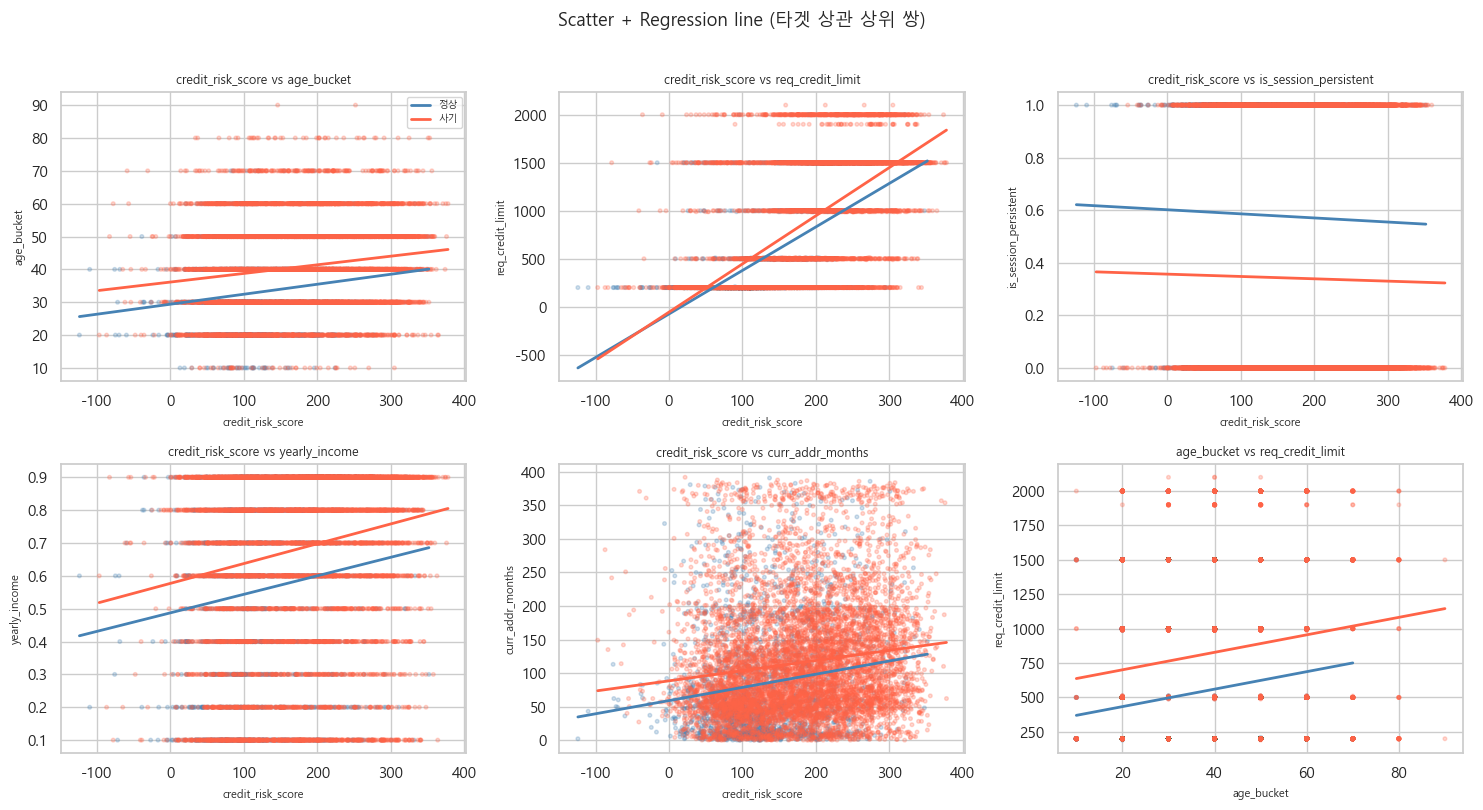

In [76]:
# 타겟 상관 기준 상위 6개 변수 선택
corr_target = (train[num_cols + ['fraud_bool']]
               .replace(-1, np.nan)
               .corr(method='spearman')['fraud_bool']
               .drop('fraud_bool').abs()
               .sort_values(ascending=False))
top_corr = corr_target.index[:min(6, len(num_cols))]

# 상위 쌍 산점도 (상위 3쌍)
pairs = [(top_corr[i], top_corr[j])
         for i in range(len(top_corr)) for j in range(i+1, len(top_corr))][:6]

ncols = 3
nrows = (len(pairs) + ncols - 1) // ncols

samp_n = normal.sample(min(2000, len(normal)), random_state=SEED)
df_scatter = pd.concat([samp_n, fraud]).replace(-1, np.nan)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
axes = axes.flatten() if nrows > 1 else [axes] if len(pairs) == 1 else axes.tolist()

for k, (c1, c2) in enumerate(pairs):
    ax = axes[k]
    sub = df_scatter[[c1, c2, 'fraud_bool']].dropna()
    colors = sub['fraud_bool'].map({0: 'steelblue', 1: 'tomato'})
    ax.scatter(sub[c1], sub[c2], c=colors, alpha=0.25, s=7)
    # 회귀선
    for lbl, df_r, col_r in [('정상', sub[sub['fraud_bool']==0], 'steelblue'),
                               ('사기', sub[sub['fraud_bool']==1], 'tomato')]:
        if len(df_r) < 5:
            continue
        try:
            m, b, *_ = stats.linregress(df_r[c1], df_r[c2])
            xs = np.linspace(df_r[c1].min(), df_r[c1].max(), 100)
            ax.plot(xs, m * xs + b, color=col_r, lw=2, label=lbl)
        except Exception:
            pass
    ax.set_xlabel(c1, fontsize=8); ax.set_ylabel(c2, fontsize=8)
    ax.set_title(f'{c1} vs {c2}', fontsize=9)
    if k == 0:
        ax.legend(fontsize=7)

for j in range(len(pairs), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Scatter + Regression line (타겟 상관 상위 쌍)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


### 2-2. Hexbin / 2D Histogram / Contour / LOESS

**뭐 보여주나:**
- Hexbin: 점이 너무 많을 때 육각형 밀도로 집계 (색 = 사기 비율)
- 2D Histogram: 두 변수의 동시 빈도
- Contour: 클래스별 밀도 등고선
- LOESS: 비선형 추세 곡선

**다음 단계:**
- Hexbin에서 사기가 특정 구석에 몰리면 → 두 변수의 곱·비율 피처
- LOESS 꺾이는 구간 → 해당 x 지점 기준 이진 피처


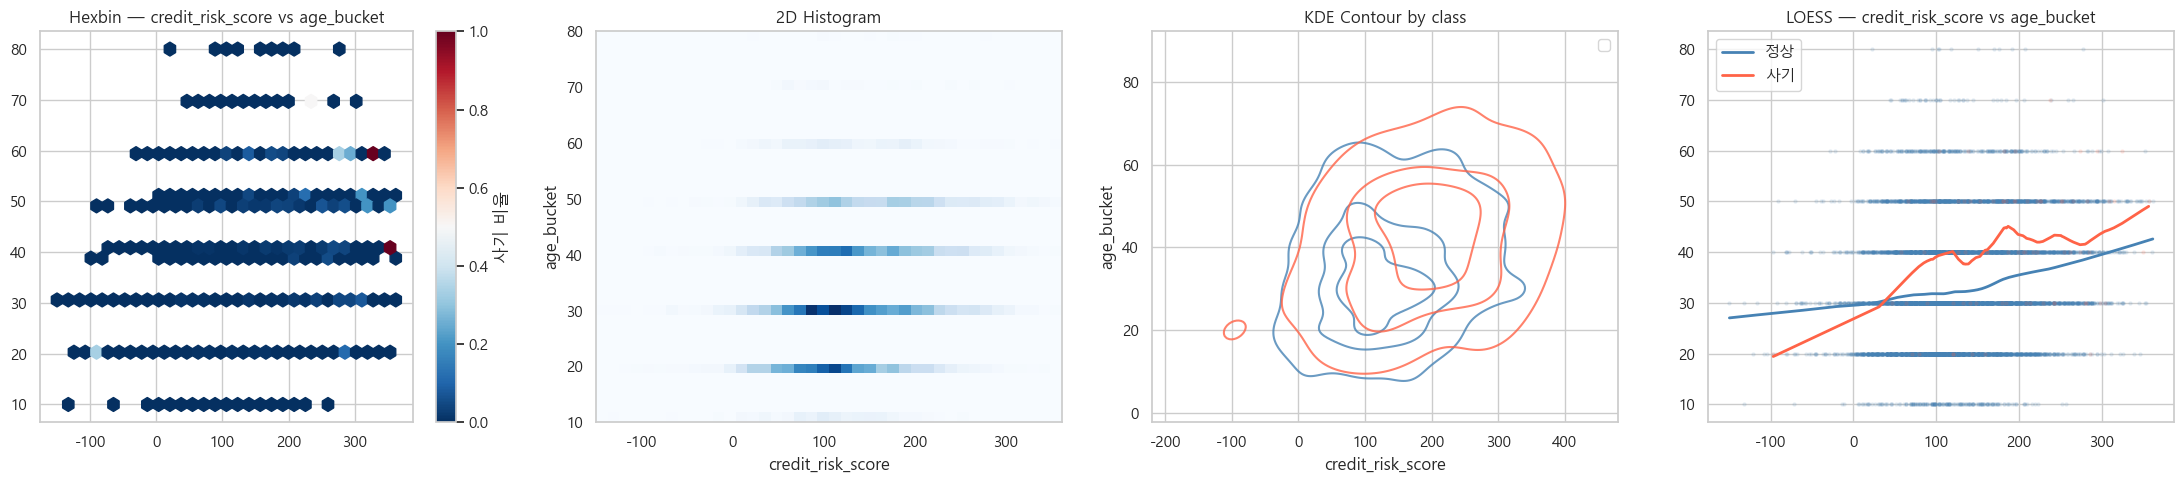

In [85]:
c1, c2 = top_corr[0], top_corr[1] if len(top_corr) > 1 else (num_cols[0], num_cols[1])
sub = train[[c1, c2, 'fraud_bool']].replace(-1, np.nan).dropna()
sub = sub.sample(min(8000, len(sub)), random_state=SEED)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Hexbin (색=사기 비율)
hb = axes[0].hexbin(sub[c1], sub[c2], C=sub['fraud_bool'],
                     reduce_C_function=np.mean, gridsize=30,
                     cmap='RdBu_r', vmin=0, vmax=1)
plt.colorbar(hb, ax=axes[0], label='사기 비율')
axes[0].set_title(f'Hexbin — {c1} vs {c2}')

# 2D Histogram
axes[1].hist2d(sub[c1], sub[c2], bins=40, cmap='Blues')
axes[1].set_title('2D Histogram')
axes[1].set_xlabel(c1); axes[1].set_ylabel(c2)

# Contour (KDE by class)
for lbl, df_c, col_c in [('정상', sub[sub['fraud_bool']==0].sample(min(500,len(sub)),random_state=SEED), 'steelblue'),
                           ('사기', sub[sub['fraud_bool']==1], 'tomato')]:
    if len(df_c) < 5:
        continue
    sns.kdeplot(data=df_c, x=c1, y=c2, ax=axes[2],
                color=col_c, levels=4, label=lbl, alpha=0.8)
axes[2].set_title('KDE Contour by class')
axes[2].legend()

# LOESS
from statsmodels.nonparametric.smoothers_lowess import lowess
for lbl, df_l, col_l in [('정상', sub[sub['fraud_bool']==0], 'steelblue'),
                           ('사기', sub[sub['fraud_bool']==1], 'tomato')]:
    if len(df_l) < 10:
        continue
    df_l = df_l.sort_values(c1)
    sm = lowess(df_l[c2].values, df_l[c1].values, frac=0.3)
    axes[3].scatter(df_l[c1], df_l[c2], color=col_l, alpha=0.1, s=5)
    axes[3].plot(sm[:, 0], sm[:, 1], color=col_l, lw=2, label=lbl)
axes[3].set_title(f'LOESS — {c1} vs {c2}')
axes[3].legend()

plt.tight_layout()
plt.show()



### 2-3. Joint plot / Binned scatter — 전체 주요 쌍

**다음 단계:**
- Binned scatter에서 특정 x 구간에서만 사기율이 튀면 → 그 구간만 `1`인 플래그 피처


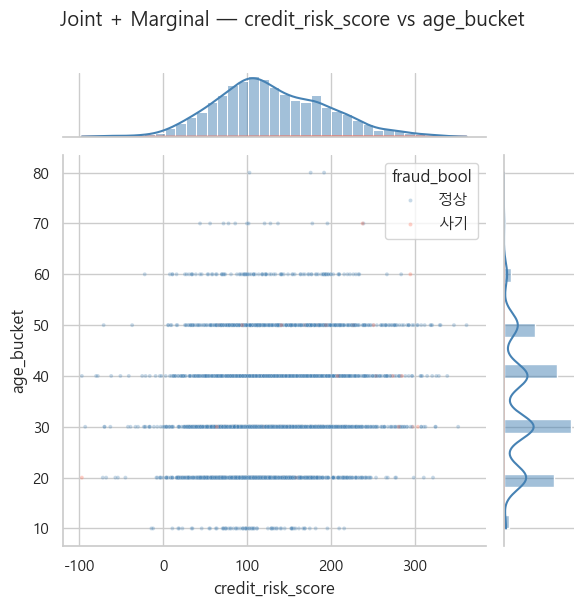

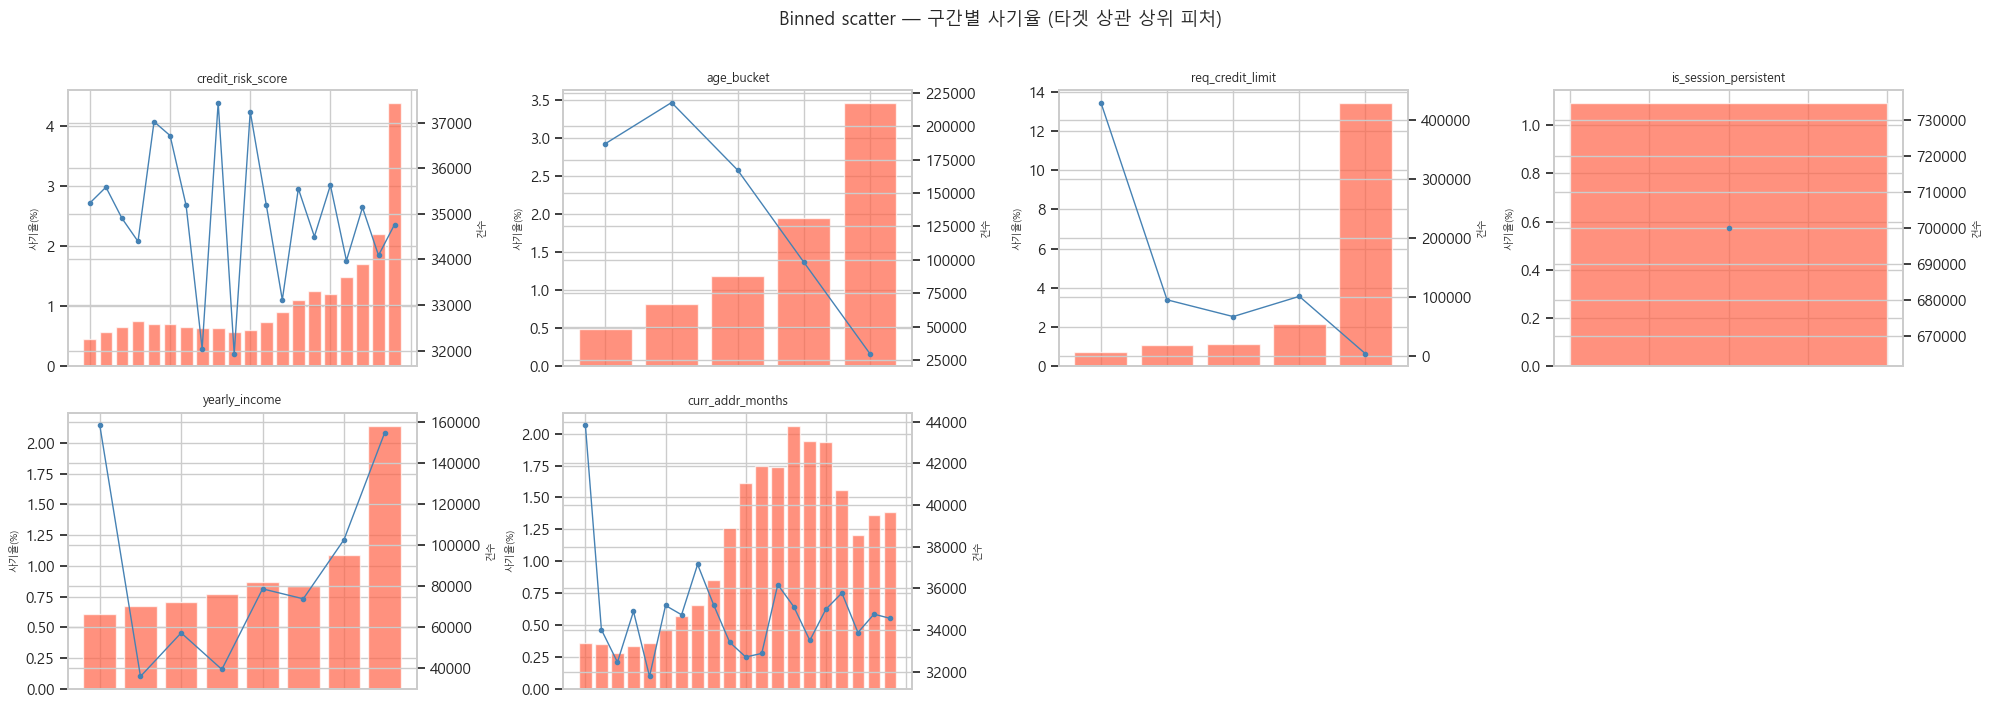

In [86]:
# ── Joint plot (상위 상관 쌍 1개) ──
c1, c2 = top_corr[0], top_corr[1] if len(top_corr) > 1 else (num_cols[0], num_cols[1])
sub = train[[c1, c2, 'fraud_bool']].replace(-1, np.nan).dropna()
sub = sub.sample(min(3000, len(sub)), random_state=SEED)

g = sns.JointGrid(data=sub, x=c1, y=c2, height=6)
g.plot_joint(sns.scatterplot, hue=sub['fraud_bool'].map({0: '정상', 1: '사기'}),
             palette={'정상': 'steelblue', '사기': 'tomato'}, alpha=0.3, s=8)
g.plot_marginals(sns.histplot, kde=True, hue=sub['fraud_bool'].map({0: '정상', 1: '사기'}),
                 palette={'정상': 'steelblue', '사기': 'tomato'})
g.fig.suptitle(f'Joint + Marginal — {c1} vs {c2}', y=1.01)
plt.tight_layout()
plt.show()

# ── Binned scatter — 상위 피처들의 구간별 사기율 그리드 ──
top_n = min(8, len(num_cols))
ncols = NCOLS_GRID
nrows = (top_n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 3.5))
axes = axes.flatten() if nrows > 1 else axes if top_n > 1 else [axes]

for i, col in enumerate(top_corr[:top_n]):
    ax = axes[i]
    df_bin = train[[col, 'fraud_bool']].replace(-1, np.nan).dropna()
    df_bin['bin'] = pd.qcut(df_bin[col], q=20, duplicates='drop')
    binned = df_bin.groupby('bin', observed=True)['fraud_bool'].agg(['mean', 'count']).reset_index()
    binned.index = range(len(binned))

    ax.bar(binned.index, binned['mean'] * 100, color='tomato', alpha=0.7)
    ax2 = ax.twinx()
    ax2.plot(binned.index, binned['count'], color='steelblue', marker='o', ms=3, lw=1)
    ax.set_title(f'{col}', fontsize=9)
    ax.set_ylabel('사기율(%)', fontsize=7)
    ax2.set_ylabel('건수', fontsize=7)
    ax.tick_params(axis='x', labelbottom=False)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Binned scatter — 구간별 사기율 (타겟 상관 상위 피처)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


---
## 3) 두 변수 관계 — 수치 × 범주


### 3-1. Grouped Box / Violin / Mean±CI — 전체 범주형 × 전체 수치형

각 범주형 칼럼마다, 수치형 피처 분포가 범주 값에 따라 달라지는지 봅니다.

**다음 단계:**
- 범주 내에서 분포가 크게 달라지면 → `그룹 내 z-score` 파생 피처
- 특정 범주에서 수치 평균이 튀면 → 해당 범주 × 수치 교차항 피처


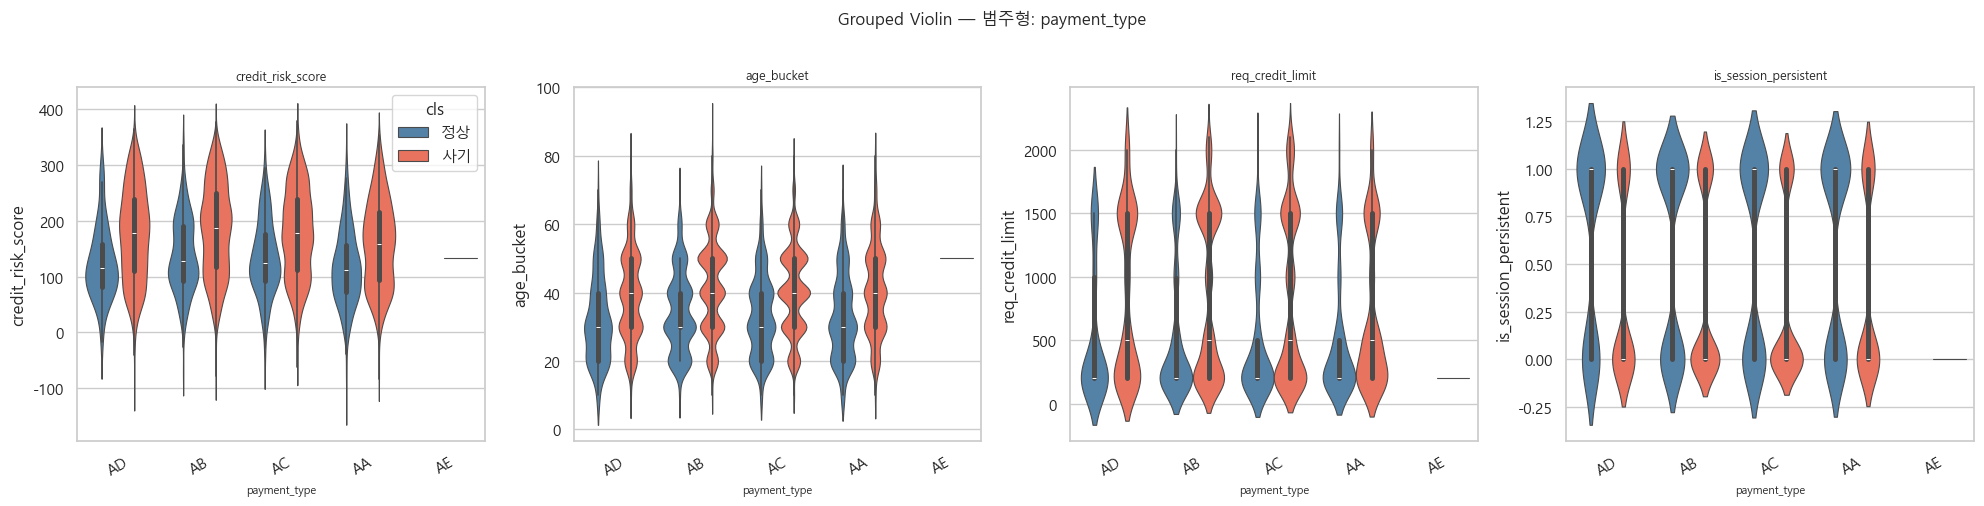

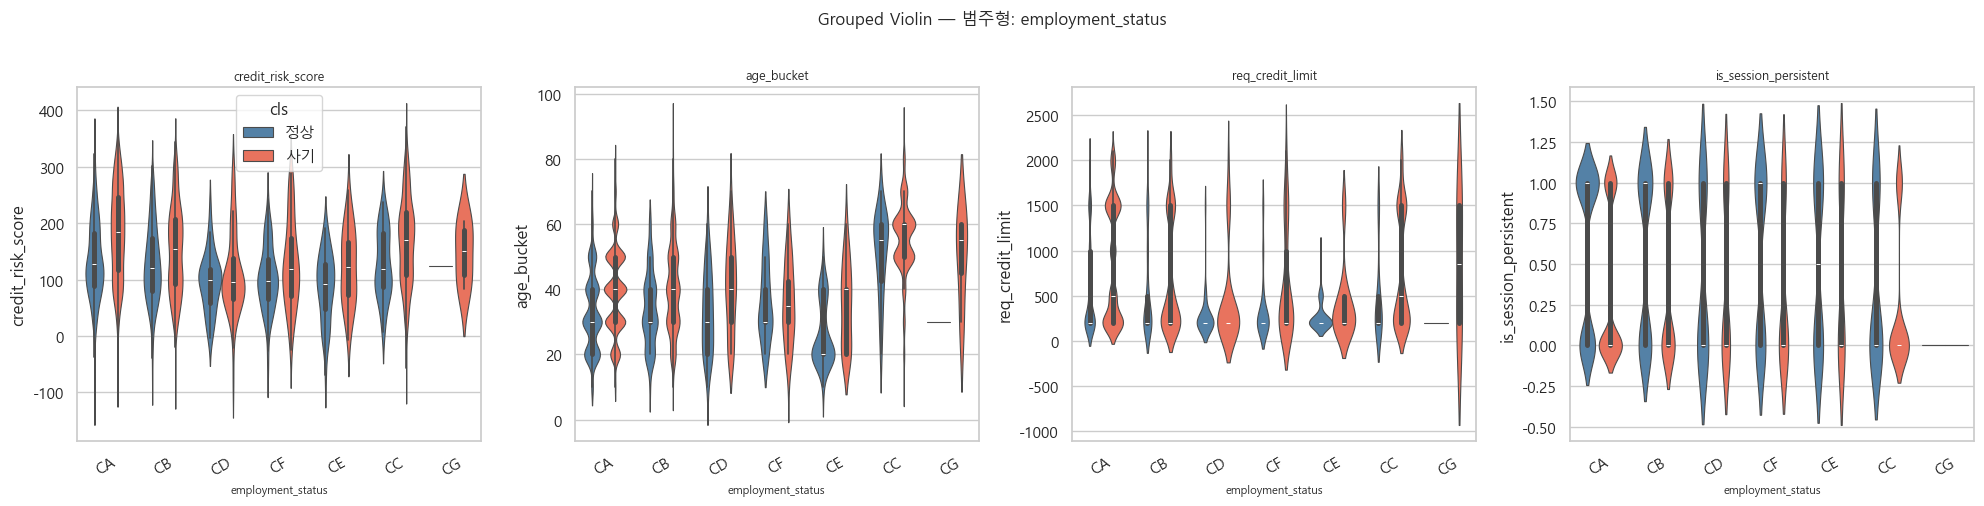

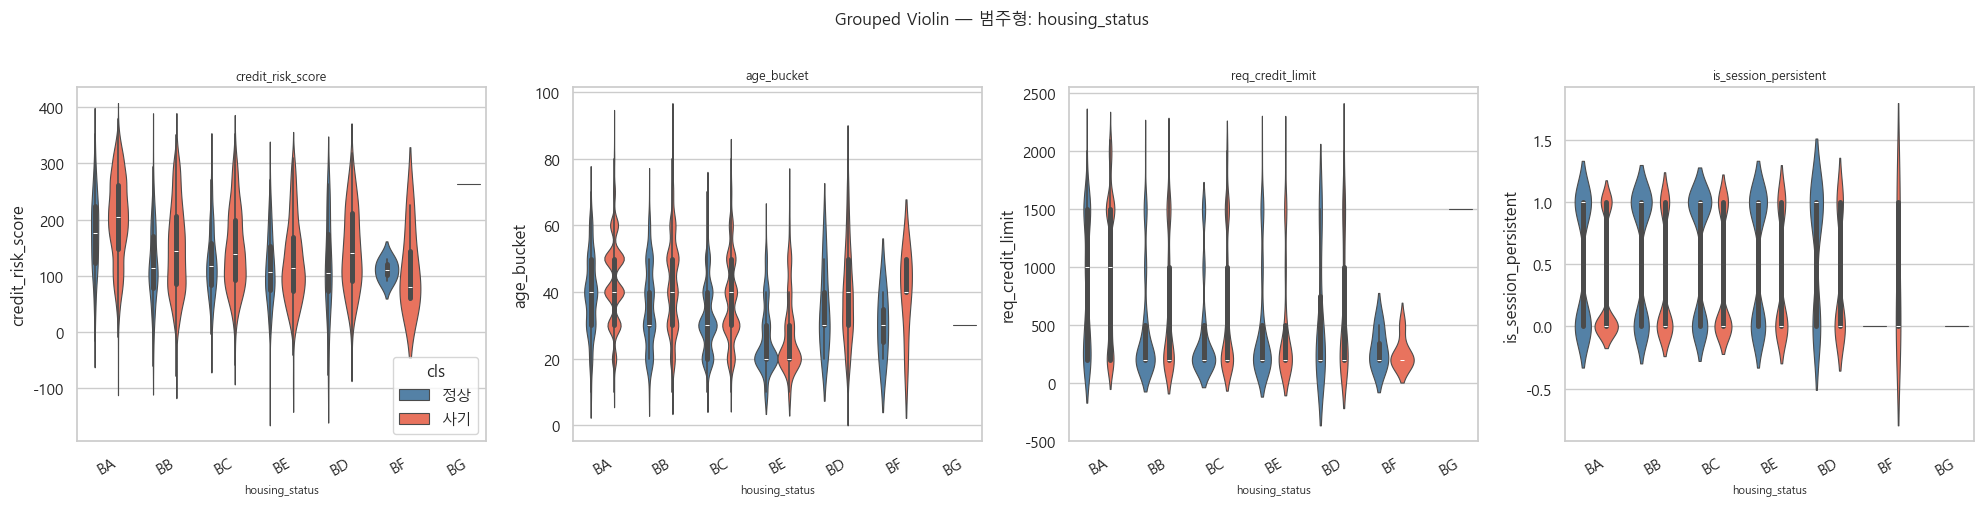

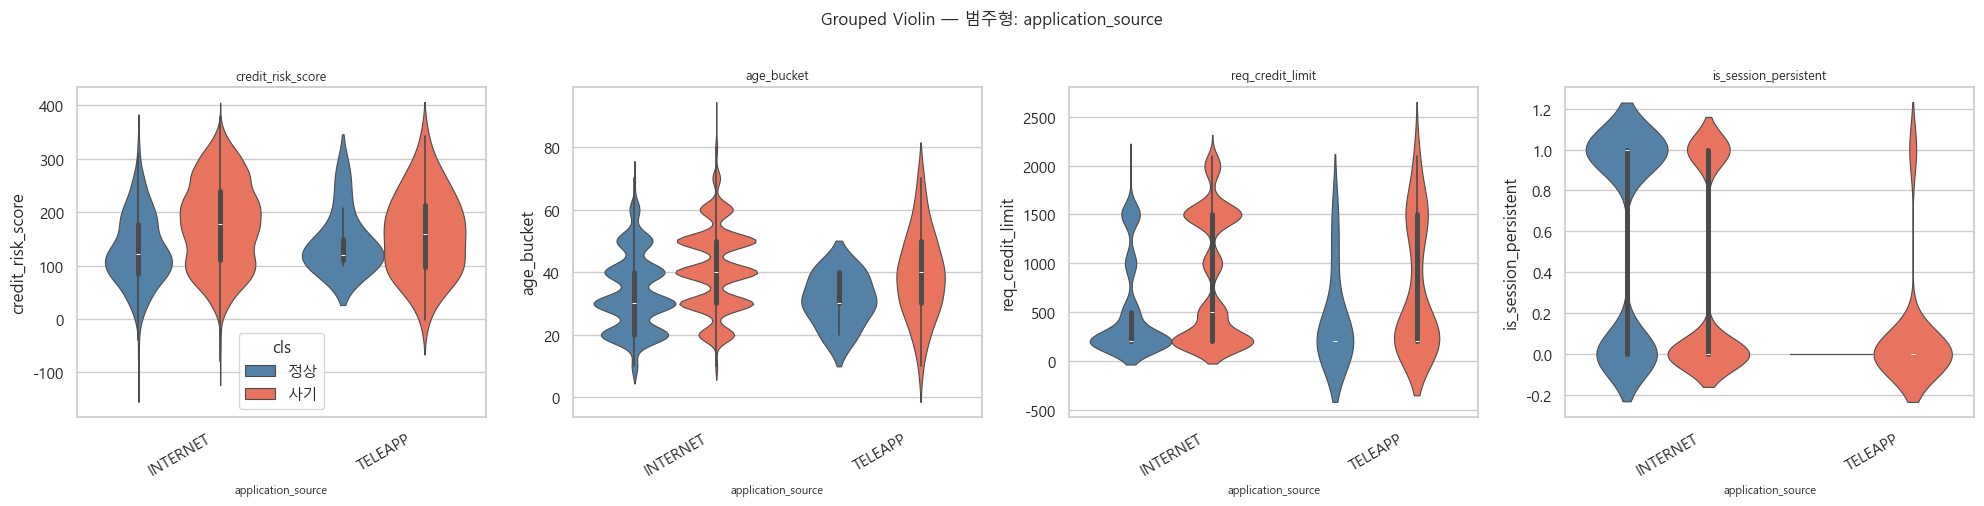

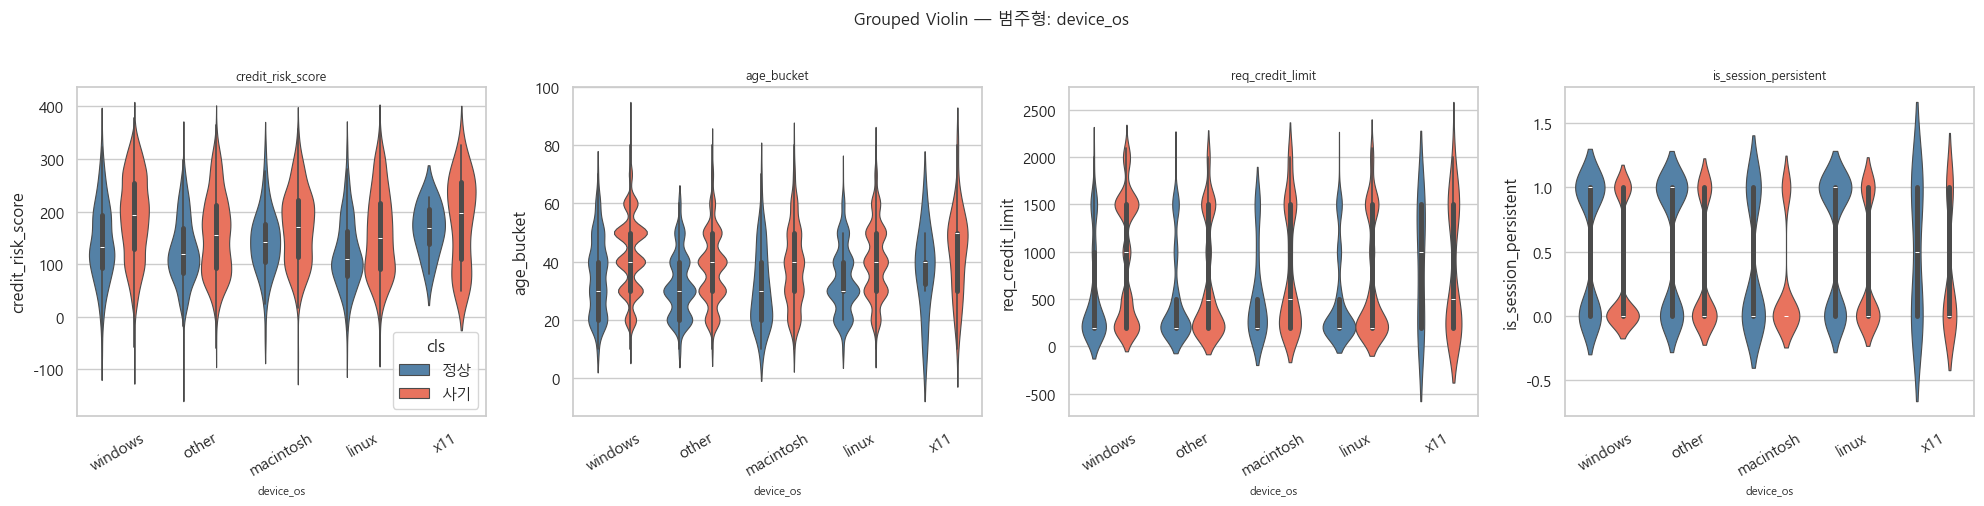

In [ ]:
if not cat_cols:
    print('범주형 칼럼 없음 — 건너뜁니다.')
else:
    for ccat in cat_cols:
        top_num = top_corr[:min(4, len(top_corr))]
        n_num = len(top_num)
        samp_n = normal.sample(min(1500, len(normal)), random_state=SEED)
        df_g = pd.concat([samp_n, fraud])[[ccat] + list(top_num) + ['fraud_bool']].dropna()
        df_g['cls'] = df_g['fraud_bool'].map({0: '정상', 1: '사기'})

        fig, axes = plt.subplots(1, n_num, figsize=(n_num * 5, 5))
        if n_num == 1:
            axes = [axes]

        for i, num_c in enumerate(top_num):
            ax = axes[i]
            try:
                sns.violinplot(data=df_g, x=ccat, y=num_c, hue='cls', ax=ax,
                               palette={'정상': 'steelblue', '사기': 'tomato'},
                               inner='box', linewidth=0.8)
            except Exception:
                sns.boxplot(data=df_g, x=ccat, y=num_c, hue='cls', ax=ax,
                            palette={'정상': 'steelblue', '사기': 'tomato'})
            ax.set_title(f'{num_c}', fontsize=9)
            ax.tick_params(axis='x', rotation=30)
            ax.set_xlabel(ccat, fontsize=8)
            if i > 0:
                ax.get_legend().remove()

        plt.suptitle(f'Grouped Violin — 범주형: {ccat}', y=1.01, fontsize=12)
        plt.tight_layout()
        plt.show()


### 3-2. Stacked bar / 100% Stacked / Side-by-side / Category-Target Heatmap — 전체 범주형

**다음 단계:**
- 특정 범주 값에 사기가 집중 → Target Encoding 우선 후보
- 히트맵에서 특정 범주 조합이 빨가면 → 교차 이진 피처


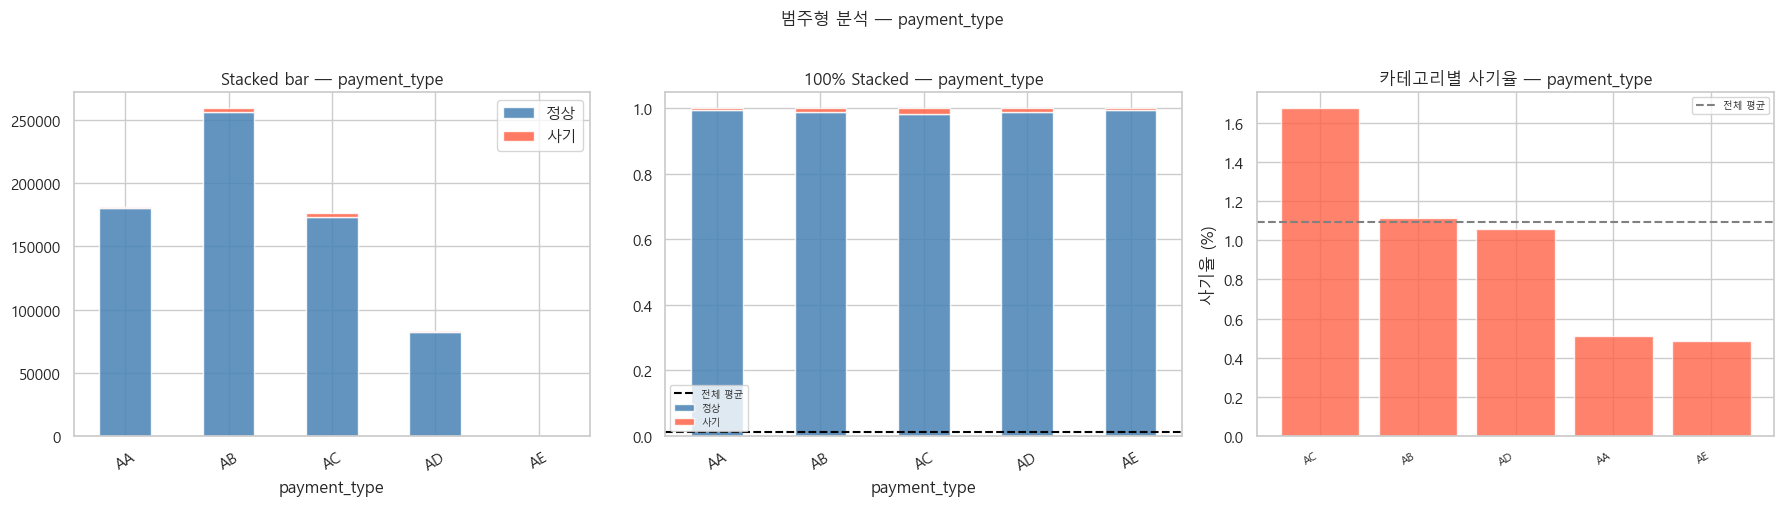

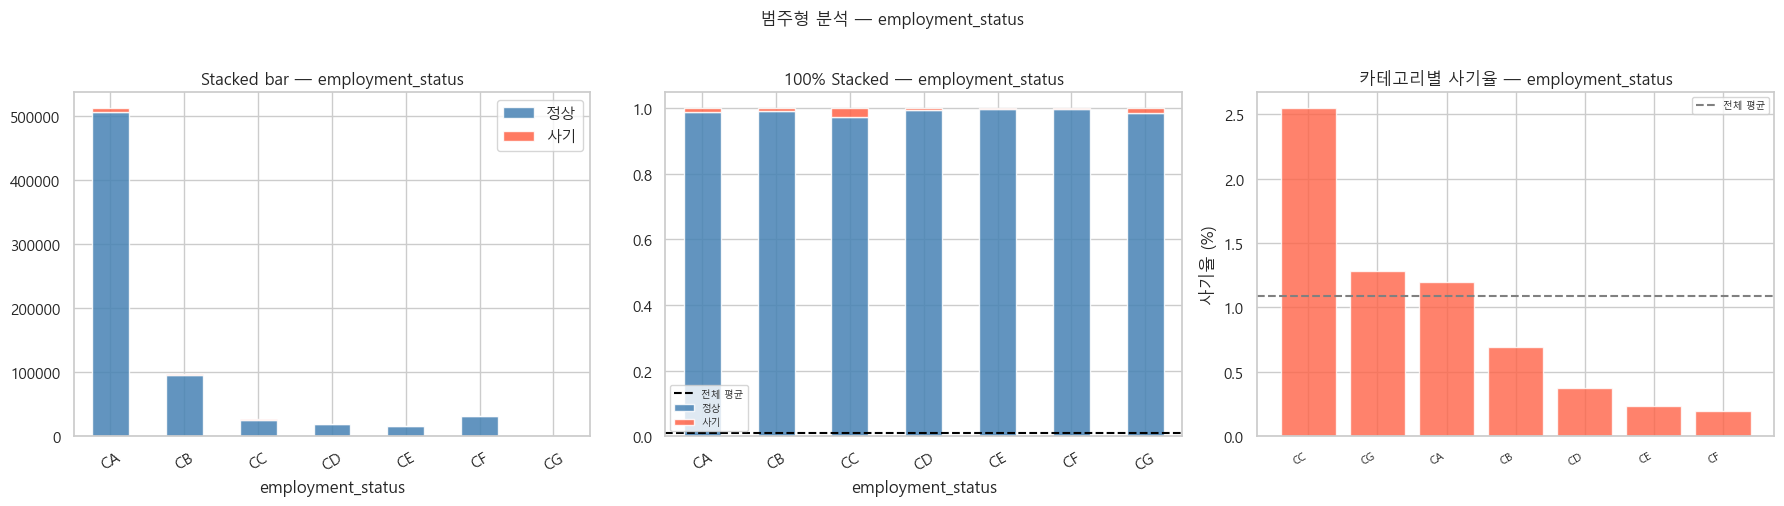

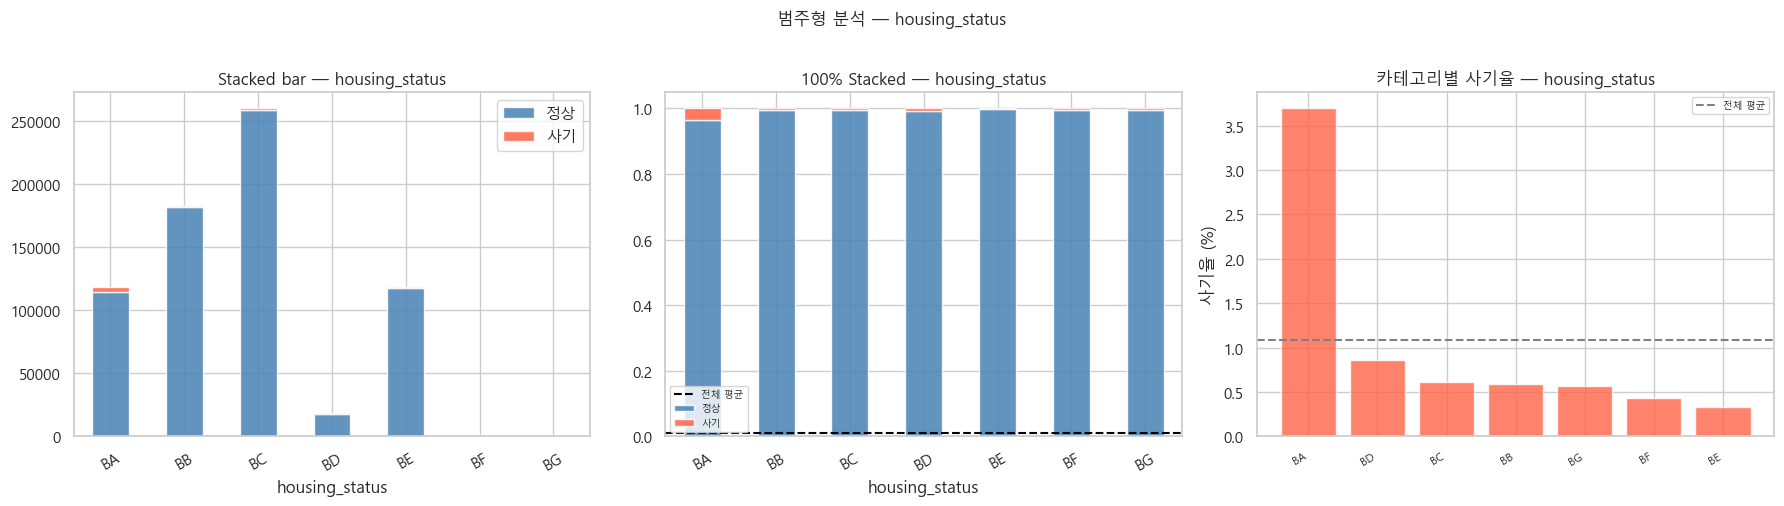

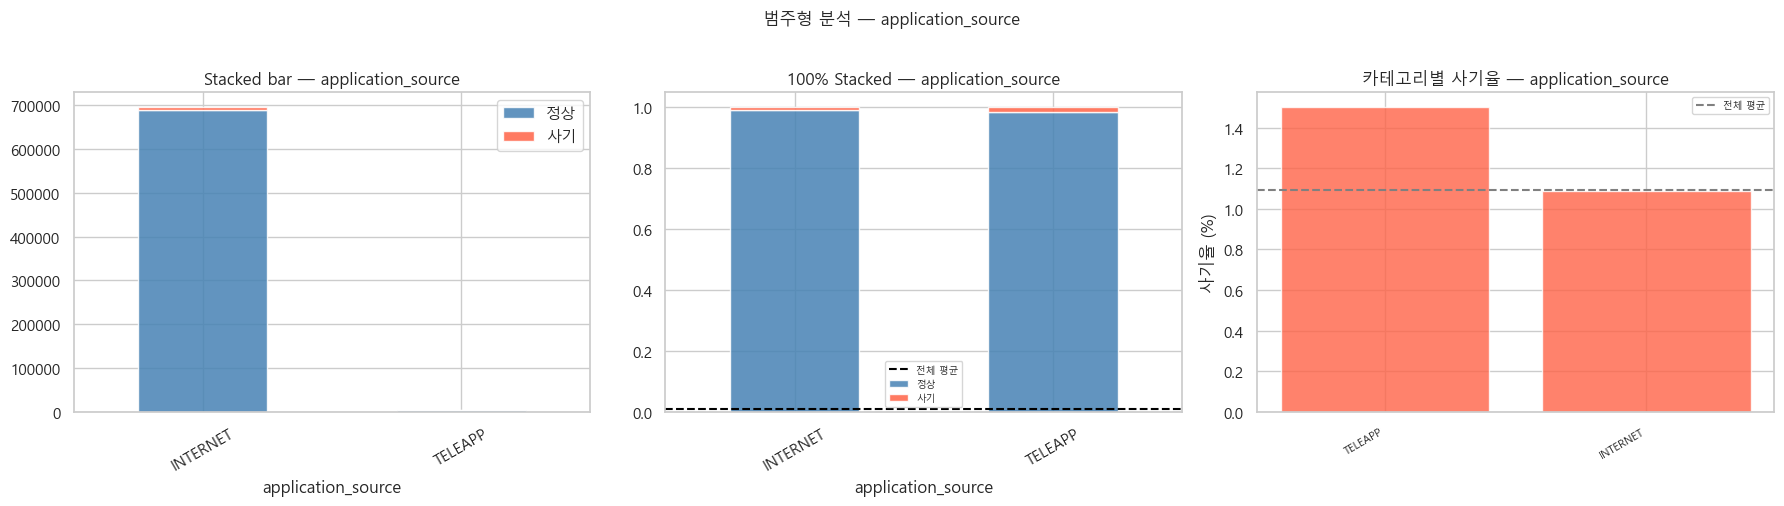

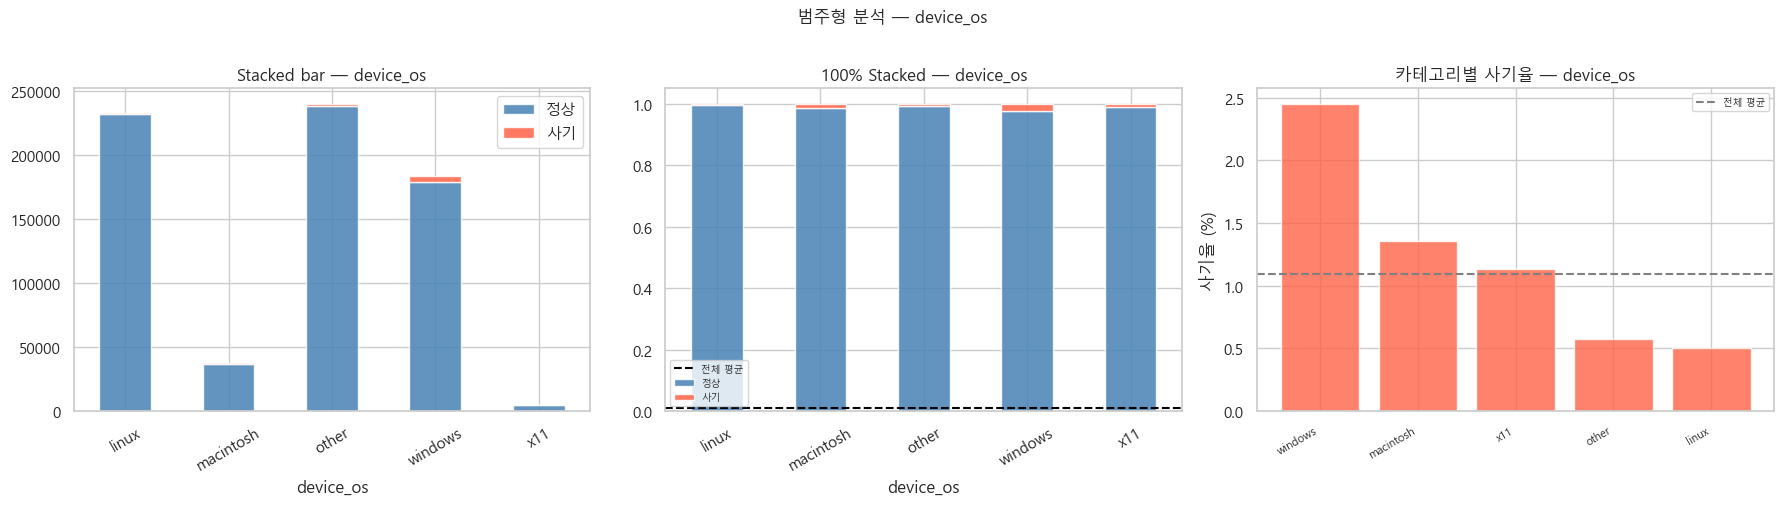

In [ ]:
if not cat_cols:
    print('범주형 칼럼 없음 — 건너뜁니다.')
else:
    for ccat in cat_cols:
        ct = pd.crosstab(train[ccat], train['fraud_bool'])
        ct.columns = ['정상', '사기']

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        ct.plot(kind='bar', stacked=True, ax=axes[0],
                color=['steelblue', 'tomato'], alpha=0.85)
        axes[0].set_title(f'Stacked bar — {ccat}')
        axes[0].tick_params(axis='x', rotation=30)

        ct_pct = ct.div(ct.sum(axis=1), axis=0)
        ct_pct.plot(kind='bar', stacked=True, ax=axes[1],
                    color=['steelblue', 'tomato'], alpha=0.85)
        axes[1].axhline(train['fraud_bool'].mean(), color='black',
                        linestyle='--', lw=1.5, label='전체 평균')
        axes[1].set_title(f'100% Stacked — {ccat}')
        axes[1].tick_params(axis='x', rotation=30)
        axes[1].legend(fontsize=7)

        fraud_rate = train.groupby(ccat)['fraud_bool'].mean().sort_values(ascending=False)
        axes[2].bar(range(len(fraud_rate)), fraud_rate.values * 100, color='tomato', alpha=0.8)
        axes[2].axhline(train['fraud_bool'].mean() * 100, color='gray',
                        linestyle='--', lw=1.5, label='전체 평균')
        axes[2].set_xticks(range(len(fraud_rate)))
        axes[2].set_xticklabels(fraud_rate.index, rotation=30, ha='right', fontsize=8)
        axes[2].set_title(f'카테고리별 사기율 — {ccat}')
        axes[2].set_ylabel('사기율 (%)')
        axes[2].legend(fontsize=7)

        plt.suptitle(f'범주형 분석 — {ccat}', y=1.01, fontsize=12)
        plt.tight_layout()
        plt.show()


---
## 4) 다변량


### 4-1. Correlation heatmap / Pairplot / Parallel coordinates / Radar

**뭐 보여주나:**
- Heatmap: 수치형 피처끼리 Spearman 상관
- Pairplot: 2차원 조합 산점 행렬 (상위 5개 피처)
- Parallel coordinates: 여러 축을 선으로 연결해 사기/정상 패턴 비교
- Radar: 클래스별 평균 비교

**다음 단계:**
- 상관이 높은 쌍 → 비율·차이 파생 또는 한쪽 제거
- Parallel에서 특정 축에서 사기 선이 갈라지면 → 그 변수 우선 피처화


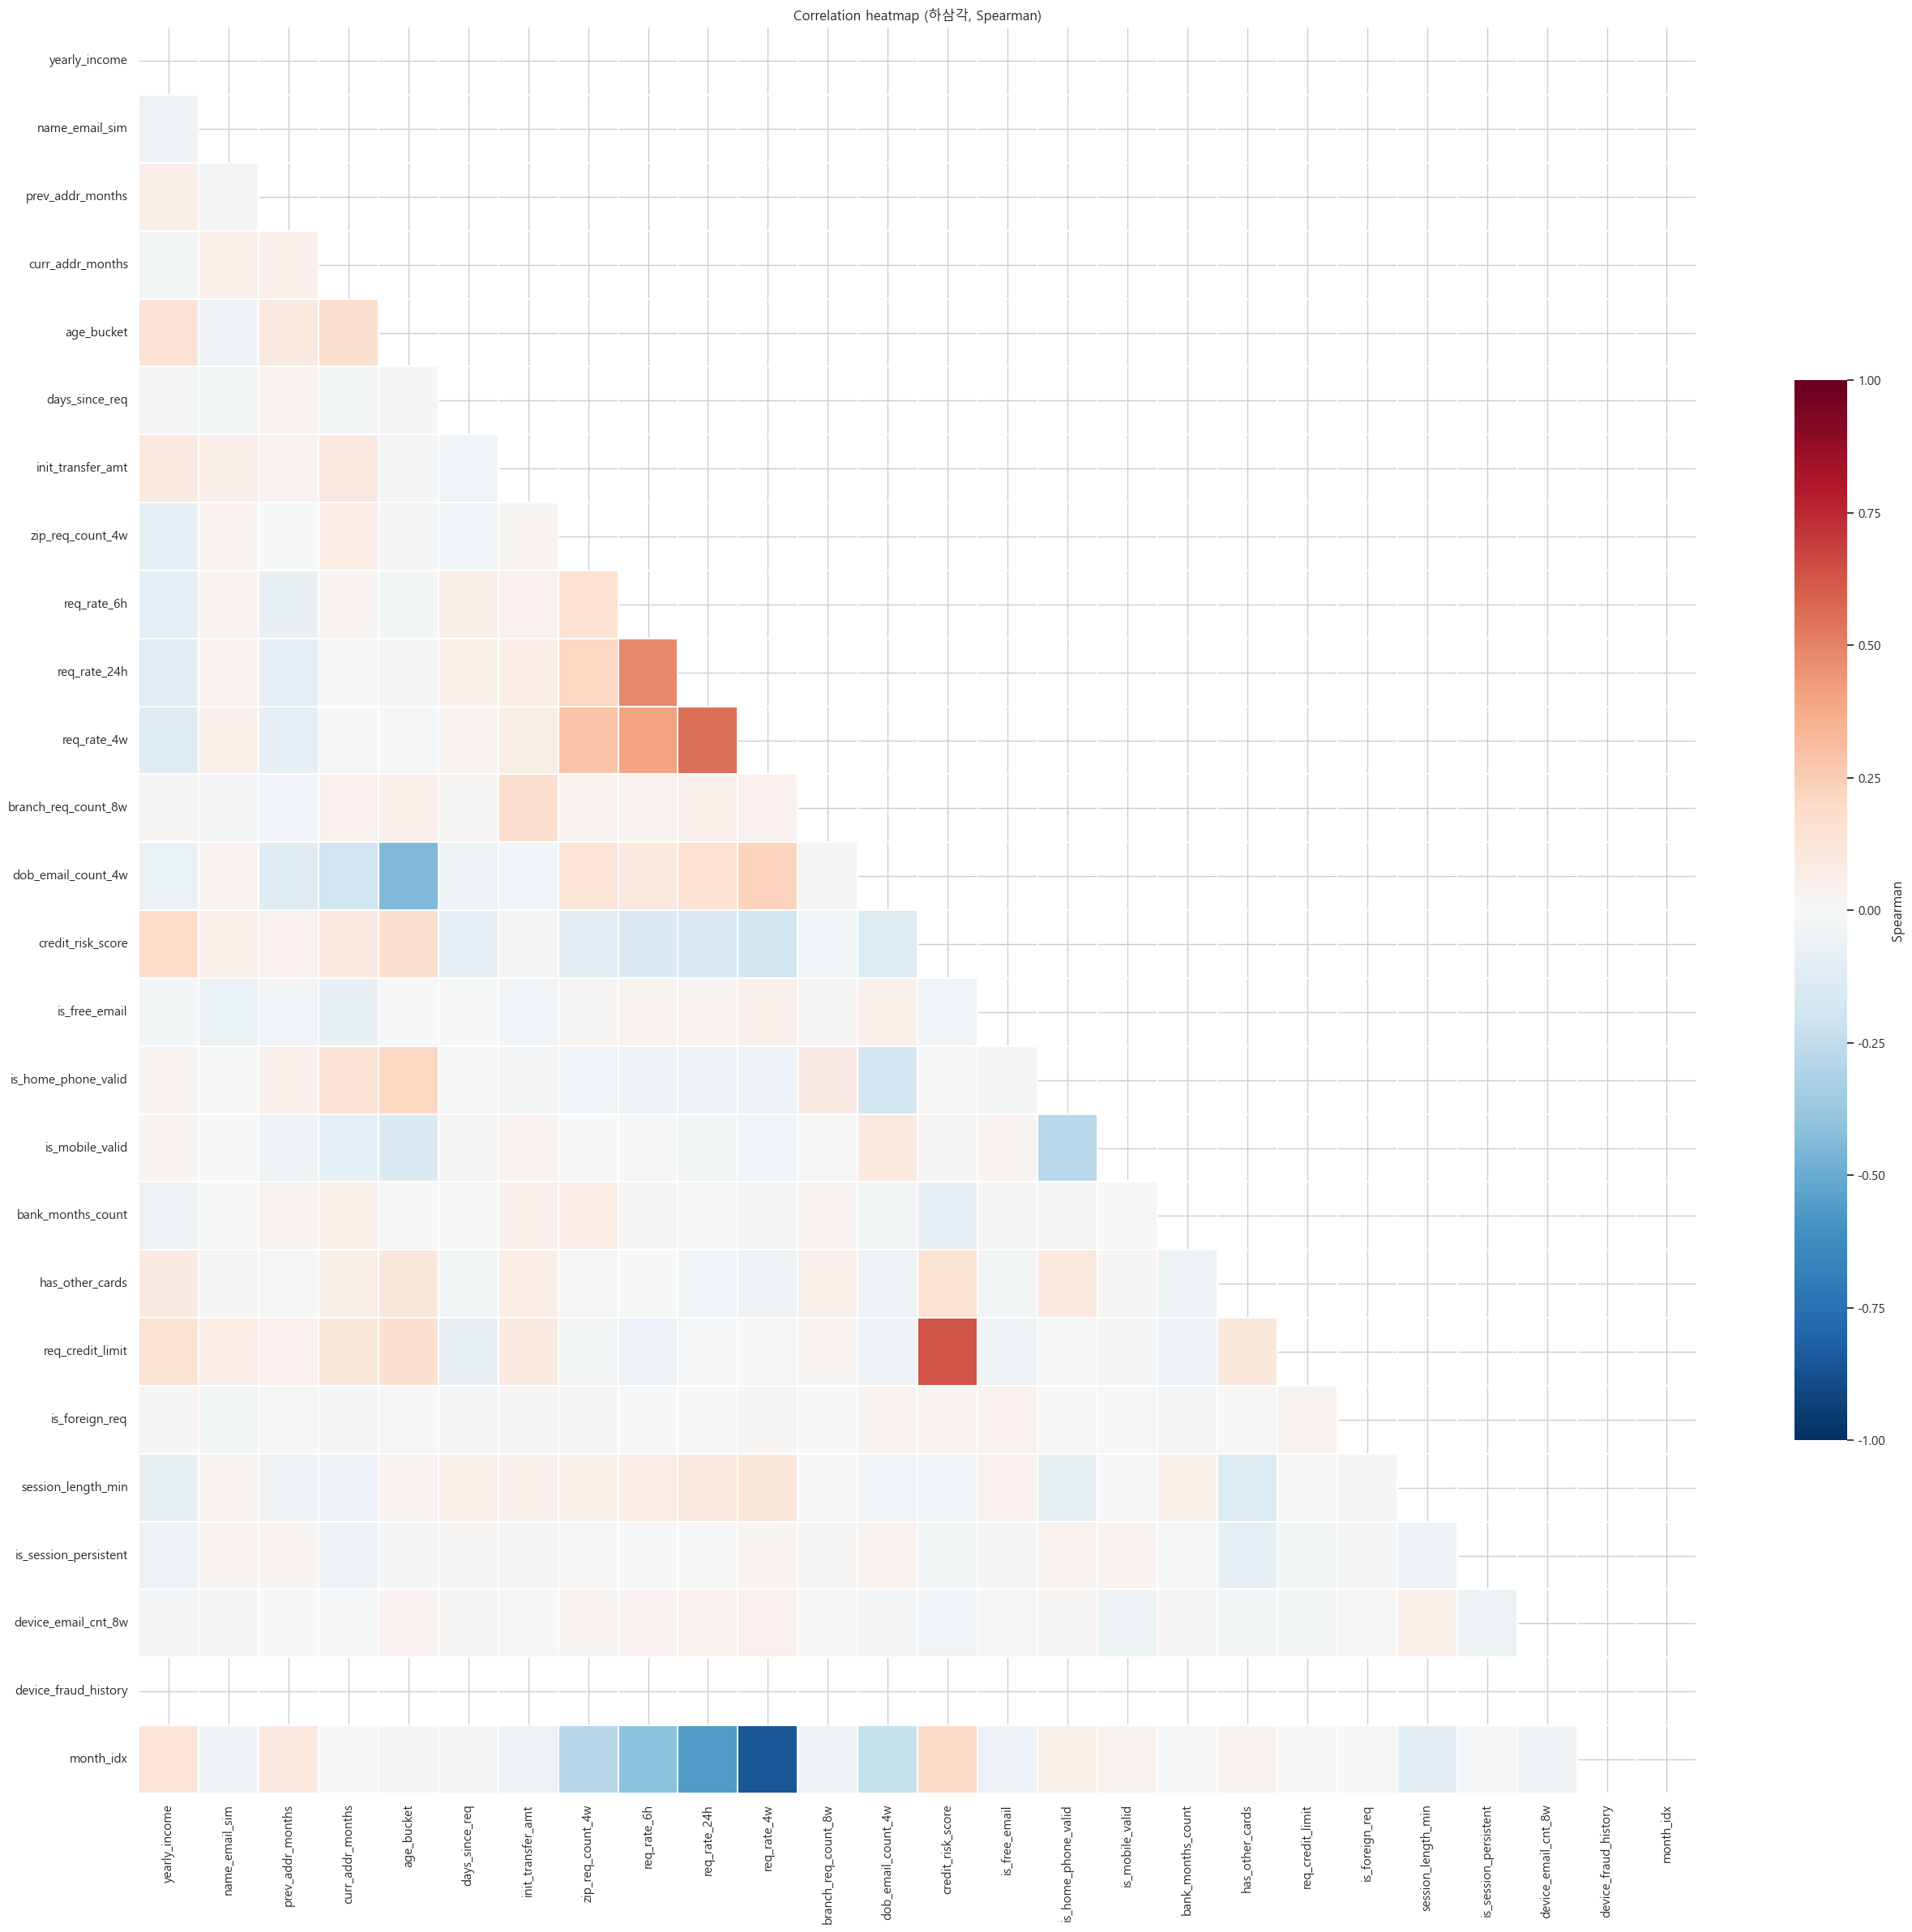

In [ ]:
# ── Correlation heatmap (전체 수치형) ──
sub_corr = train[num_cols].sample(min(30000, len(train)), random_state=SEED).replace(-1, np.nan)
cm = sub_corr.corr(method='spearman')
mask = np.triu(np.ones_like(cm, dtype=bool))
fig, ax = plt.subplots(figsize=(max(10, len(num_cols)), max(8, len(num_cols) - 2)))
sns.heatmap(cm, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.2, annot=len(num_cols) <= 15, fmt='.2f',
            cbar_kws={'shrink': 0.6, 'label': 'Spearman'}, ax=ax)
ax.set_title('Correlation heatmap (하삼각, Spearman)')
plt.tight_layout()
plt.show()


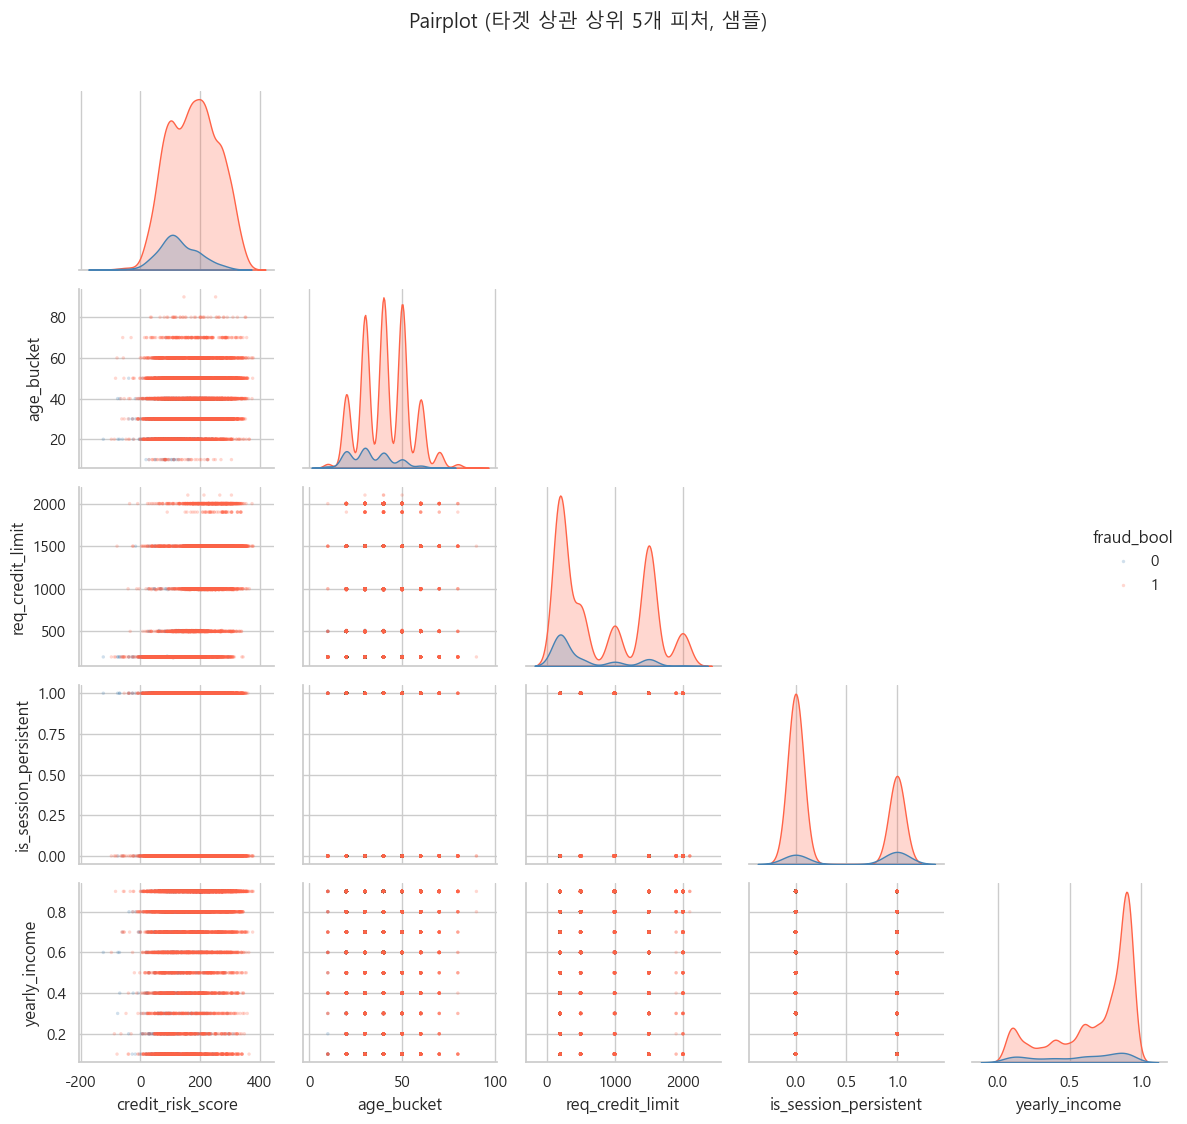

In [ ]:
# ── Pairplot (타겟 상관 상위 5개 피처) ──
top5 = top_corr[:min(5, len(top_corr))]
pp_df = pd.concat([
    normal[top5 + ['fraud_bool']].sample(min(1000, len(normal)), random_state=SEED),
    fraud[top5 + ['fraud_bool']]
]).replace(-1, np.nan).dropna()

g = sns.pairplot(pp_df, vars=top5, hue='fraud_bool', corner=True,
                 plot_kws={'alpha': 0.25, 's': 6, 'edgecolor': 'none'},
                 diag_kind='kde',
                 palette={0: 'steelblue', 1: 'tomato'}, height=2.2)
g.fig.suptitle('Pairplot (타겟 상관 상위 5개 피처, 샘플)', y=1.02)
plt.tight_layout()
plt.show()


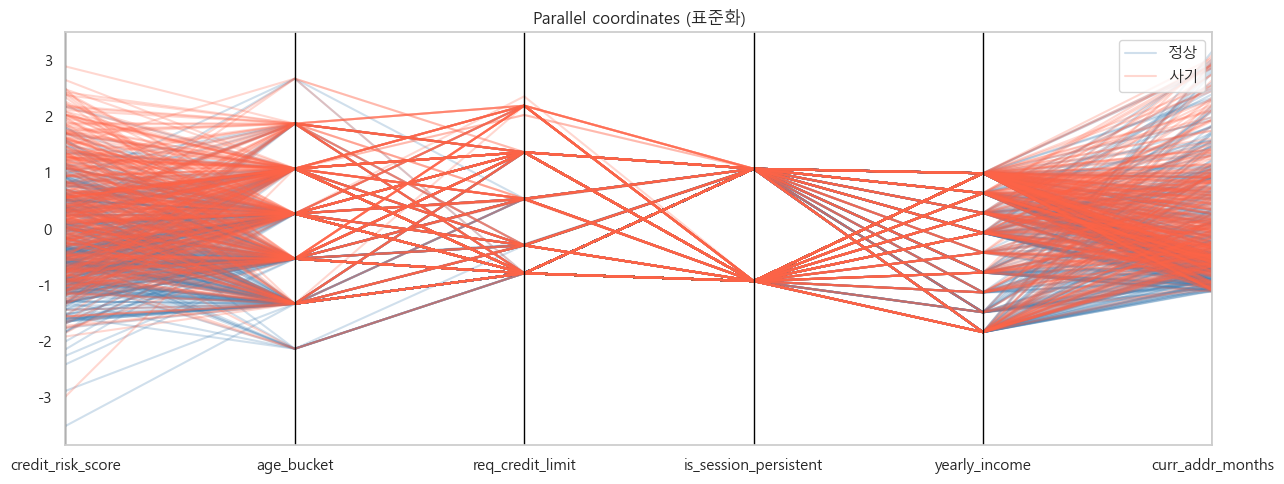

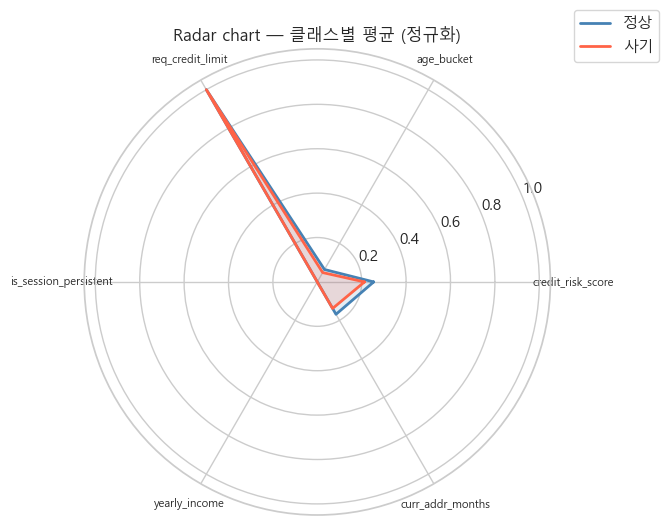

In [ ]:
from pandas.plotting import parallel_coordinates

# ── Parallel coordinates ──
pc_cols = top_corr[:min(6, len(top_corr))]
pc_df = pd.concat([
    normal[pc_cols + ['fraud_bool']].sample(min(400, len(normal)), random_state=SEED),
    fraud[pc_cols + ['fraud_bool']].sample(min(400, len(fraud)),  random_state=SEED)
]).replace(-1, np.nan).dropna()
pc_df['class_label'] = pc_df['fraud_bool'].map({0: '정상', 1: '사기'})
for c in pc_cols:
    pc_df[c] = (pc_df[c] - pc_df[c].mean()) / (pc_df[c].std() + 1e-9)

fig, ax = plt.subplots(figsize=(13, 5))
parallel_coordinates(pc_df[pc_cols + ['class_label']], 'class_label',
                     color=['steelblue', 'tomato'], alpha=0.25, ax=ax)
ax.set_title('Parallel coordinates (표준화)')
plt.tight_layout()
plt.show()

# ── Radar chart ──
radar_cols = top_corr[:min(8, len(top_corr))]
means = {}
for lbl, sub in [('정상', normal), ('사기', fraud)]:
    vals = sub[radar_cols].replace(-1, np.nan).mean()
    vn   = (vals - vals.min()) / (vals.max() - vals.min() + 1e-9)
    means[lbl] = vn.values.tolist()

N = len(radar_cols)
angles = [n / float(N) * 2 * np.pi for n in range(N)] + [0]
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for lbl, color in [('정상', 'steelblue'), ('사기', 'tomato')]:
    v = means[lbl] + [means[lbl][0]]
    ax.plot(angles, v, color=color, linewidth=2, label=lbl)
    ax.fill(angles, v, color=color, alpha=0.15)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_cols, fontsize=8)
ax.set_title('Radar chart — 클래스별 평균 (정규화)')
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1))
plt.tight_layout()
plt.show()


### 4-2. PCA / t-SNE

**무엇을 보여주나:**
- PCA: **전체 수치 피처**(`num_cols`)를 표준화·결측(·-1) 중앙값 대체 후, **전체 행**으로 투영·분산 설명
- t-SNE: 위와 **동일 행렬 X** 전체에 대해 2D 임베딩 (행·열 모두 샘플링 없음)

**주의:** 수십만 행 이상이면 t-SNE는 **매우 오래 걸리거나 메모리 부족**할 수 있습니다. 그럴 때만 셀 맨 아래 주석으로 예시된 대로 행을 줄여 실행하세요.

**다음 단계:**
- PCA 2D에서 클래스가 나뉘면 → PC1, PC2를 추가 피처로
- t-SNE 군집 소속 여부(k-means) → 군집 레이블 피처


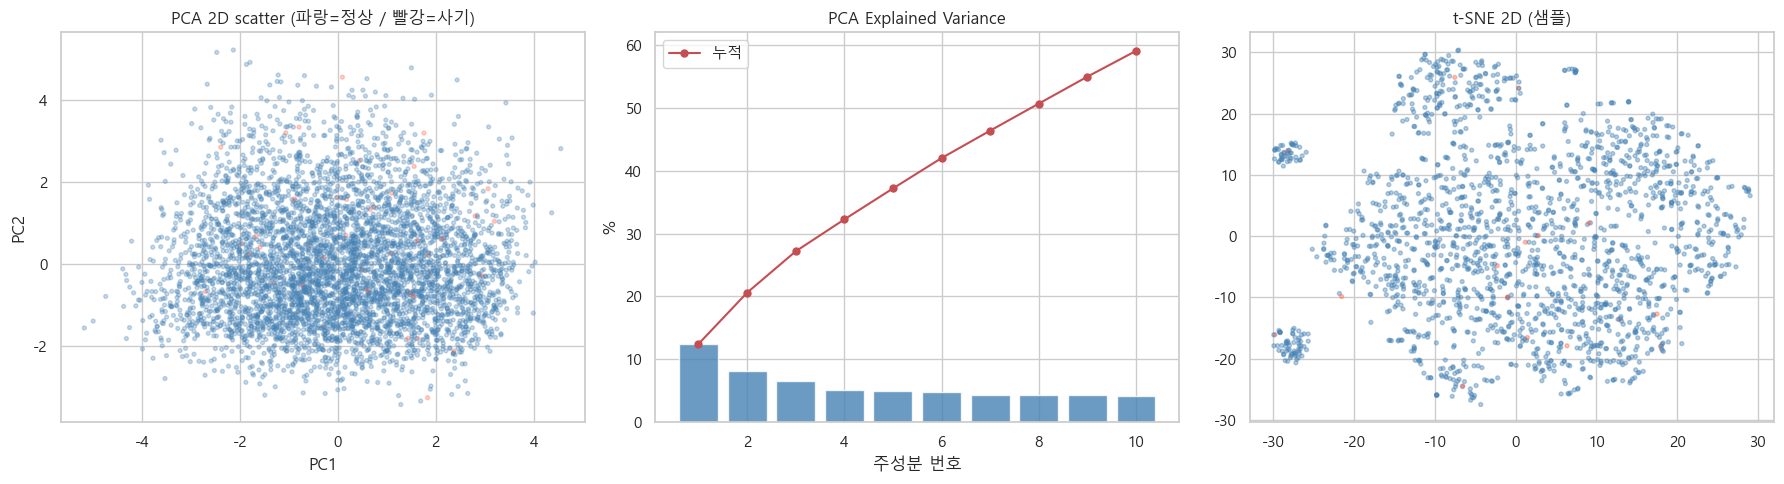

In [95]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE

# 전체 수치 피처 (샘플링 없음)
pca_cols = list(num_cols)

feat_df = train[pca_cols].replace(-1, np.nan)
imputer = SimpleImputer(strategy='median')
X_imp = imputer.fit_transform(feat_df)
X = StandardScaler().fit_transform(X_imp)
y = train['fraud_bool'].values

n_comp = min(10, X.shape[1])
pca = PCA(n_components=n_comp, random_state=SEED)
Xp = pca.fit_transform(X)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = np.array(['steelblue', 'tomato'])[y]

axes[0].scatter(Xp[:, 0], Xp[:, 1], c=colors, alpha=0.3, s=8)
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].set_title('PCA 2D scatter (파랑=정상 / 빨강=사기)')

ev = np.cumsum(pca.explained_variance_ratio_) * 100
axes[1].bar(range(1, n_comp + 1), pca.explained_variance_ratio_ * 100,
            color='steelblue', alpha=0.8)
axes[1].plot(range(1, n_comp + 1), ev, 'r-o', ms=5, label='누적')
axes[1].set_xlabel('주성분 번호'); axes[1].set_ylabel('%')
axes[1].set_title('PCA Explained Variance'); axes[1].legend()

# t-SNE: 전체 행 X (동일 피처)
# 메모리/시간 부담 시에만 예: X = X[np.random.RandomState(SEED).choice(len(X), 50000, replace=False)] 등으로 줄이기
perp = min(30, max(5, len(X) - 1))
Xt = TSNE(
    n_components=2,
    random_state=SEED,
    perplexity=perp,
    max_iter=1000,
    learning_rate='auto',
    init='pca',
).fit_transform(X)
c_tsne = np.array(['steelblue', 'tomato'])[y]
axes[2].scatter(Xt[:, 0], Xt[:, 1], c=c_tsne, alpha=0.4, s=8)
axes[2].set_title(f't-SNE 2D (n={len(X):,}행, 피처 {X.shape[1]}개)')

plt.tight_layout()
plt.show()


### 4-3. Feature Importance / Permutation / PDP / ICE / SHAP

XGBoost로 학습한 뒤 모델 기반 시각화를 모두 그립니다.

**다음 단계:**
- SHAP 상위 변수 → 우선 엔지니어링 대상
- PDP 꺾이는 구간 → 임계값 플래그 피처


In [107]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score

enc_cols = []
df_train = train.copy()
for c in cat_cols:
    df_train[c] = df_train[c].fillna('(없음)').astype(str)
    le = LabelEncoder()
    df_train[c + '_le'] = le.fit_transform(df_train[c])
    enc_cols.append(c + '_le')

feat_cols = num_cols + enc_cols
X_all_raw = df_train[feat_cols].replace(-1, np.nan)
X_all = X_all_raw.fillna(X_all_raw.median())
y_all = df_train['fraud_bool']

X_tr, X_va, y_tr, y_va = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)

model = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    tree_method='hist',
    max_bin=256,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(),
    random_state=SEED,
    verbosity=0,
    n_jobs=-1,
    eval_metric='logloss',
)
model.fit(X_tr, y_tr)

y_prob = model.predict_proba(X_va)[:, 1]
print(f'모델 학습 완료. val AP = {average_precision_score(y_va, y_prob):.4f}')


모델 학습 완료. val AP = 0.1757


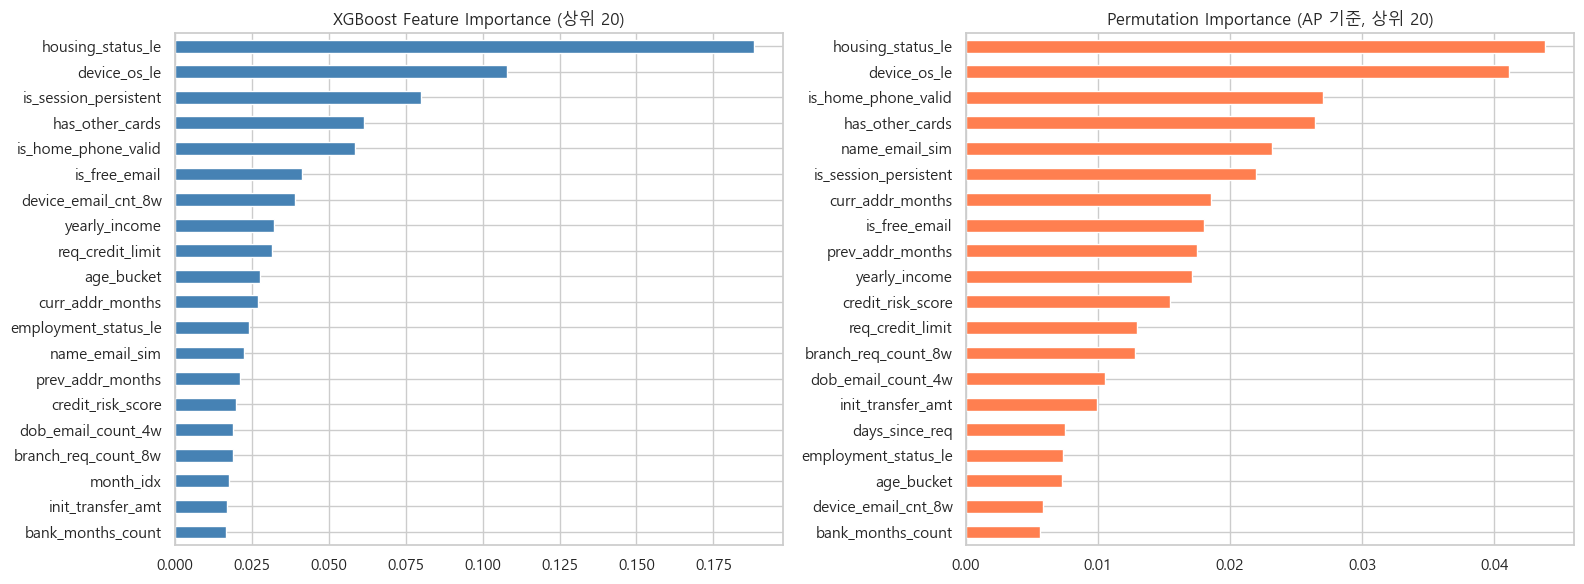

In [108]:
# ── Feature Importance ──
fi = pd.Series(model.feature_importances_, index=feat_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fi.head(20).sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('XGBoost Feature Importance (상위 20)')

# ── Permutation Importance ──
from sklearn.inspection import permutation_importance
r = permutation_importance(model, X_va, y_va, n_repeats=5,
                            random_state=SEED, scoring='average_precision', n_jobs=-1)
perm = pd.Series(r.importances_mean, index=feat_cols).sort_values(ascending=False)
perm.head(20).sort_values().plot.barh(ax=axes[1], color='coral')
axes[1].set_title('Permutation Importance (AP 기준, 상위 20)')

plt.tight_layout()
plt.show()


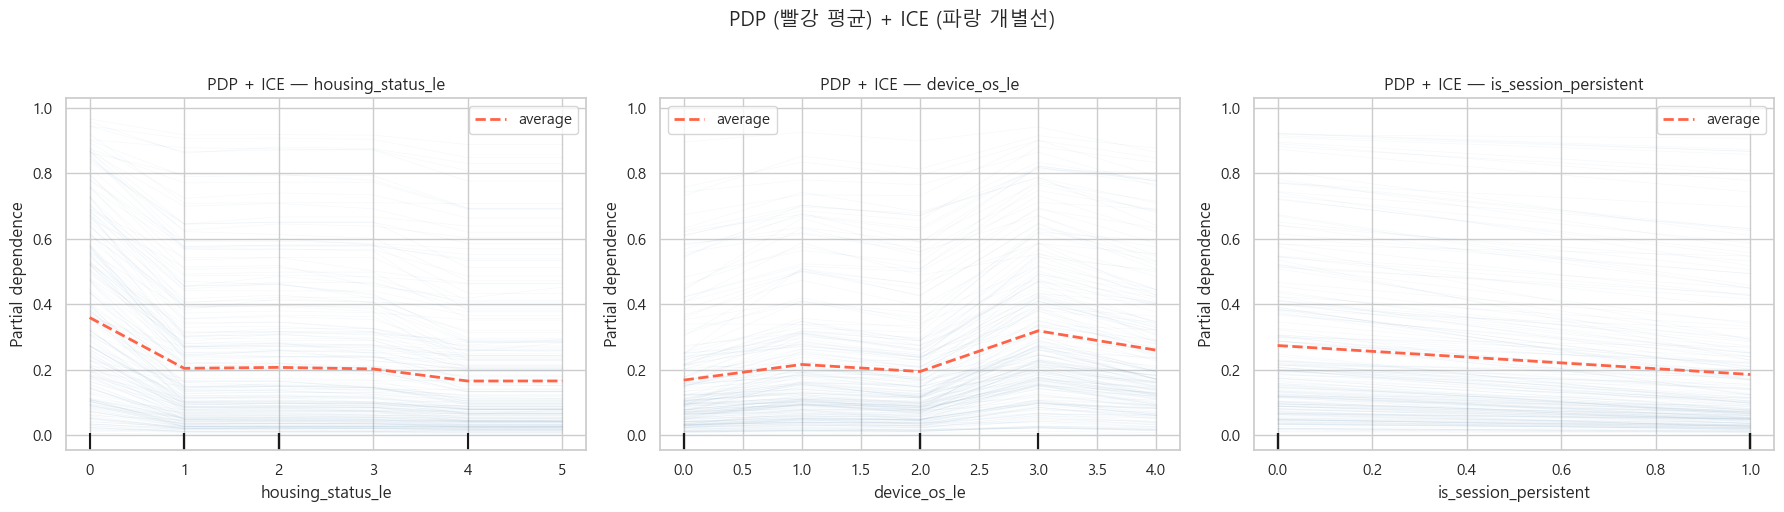

In [109]:
# ── PDP + ICE (상위 3개 피처) ──
from sklearn.inspection import PartialDependenceDisplay

pdp_features = fi.index[:3].tolist()
n_pdp = len(pdp_features)
fig, axes = plt.subplots(1, n_pdp, figsize=(6 * n_pdp, 5))
if n_pdp == 1:
    axes = [axes]

PartialDependenceDisplay.from_estimator(
    model,
    X_va.sample(min(1000, len(X_va)), random_state=SEED),
    features=pdp_features,
    kind='both',
    subsample=200,
    ax=axes,
    pd_line_kw={'color': 'tomato', 'lw': 2},
    ice_lines_kw={'color': 'steelblue', 'alpha': 0.05, 'lw': 0.5}
)
for ax, feat in zip(axes, pdp_features):
    ax.set_title(f'PDP + ICE — {feat}')
plt.suptitle('PDP (빨강 평균) + ICE (파랑 개별선)', y=1.02)
plt.tight_layout()
plt.show()


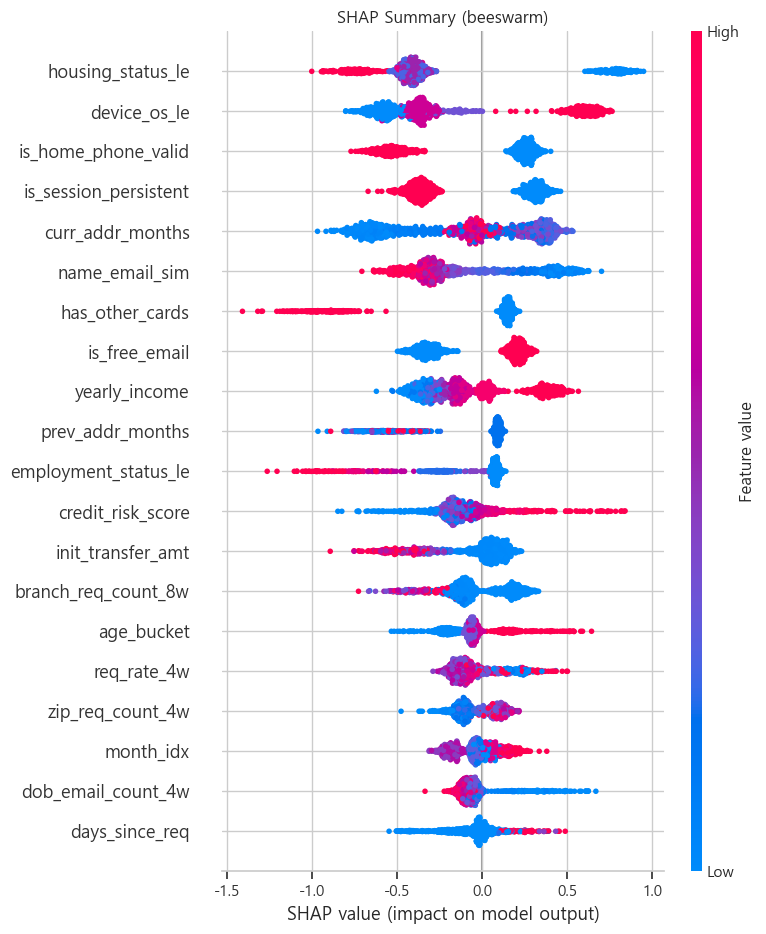

<Figure size 800x500 with 0 Axes>

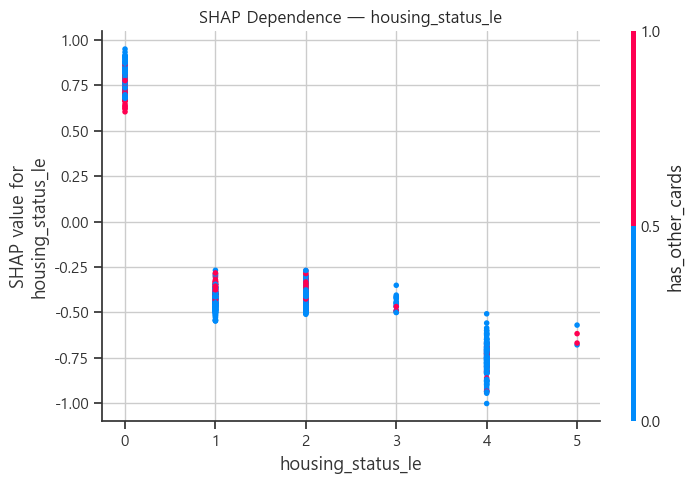

In [110]:
# ── SHAP ──
try:
    import shap
    explainer = shap.TreeExplainer(model)
    X_shap = X_va.sample(min(1000, len(X_va)), random_state=SEED)
    sv = explainer.shap_values(X_shap)
    sv_use = sv[1] if isinstance(sv, list) else sv

    # Summary beeswarm
    plt.figure()
    shap.summary_plot(sv_use, X_shap, feature_names=feat_cols,
                      show=False, max_display=20)
    plt.title('SHAP Summary (beeswarm)')
    plt.tight_layout()
    plt.show()

    # Dependence plot (상위 피처)
    top_feat = fi.index[0]
    plt.figure(figsize=(8, 5))
    shap.dependence_plot(top_feat, sv_use, X_shap,
                         feature_names=feat_cols, show=False)
    plt.title(f'SHAP Dependence — {top_feat}')
    plt.tight_layout()
    plt.show()
except ImportError:
    print('SHAP 설치 필요: pip install shap')


---
## 5) 이진 타겟 분리력 시각화


### 5-1. PR curve / ROC curve / Threshold sweep

**뭐 보여주나:**
- PR curve: 불균형 데이터에서 핵심 (AP 높을수록 좋음)
- ROC curve: TPR vs FPR 트레이드오프
- Threshold sweep: F1이 최대인 임계값 찾기

**다음 단계:**
- AP → 피처 추가 후 얼마나 올랐는지 비교 기준
- Threshold sweep → 실무 목적에 맞는 임계값 선택


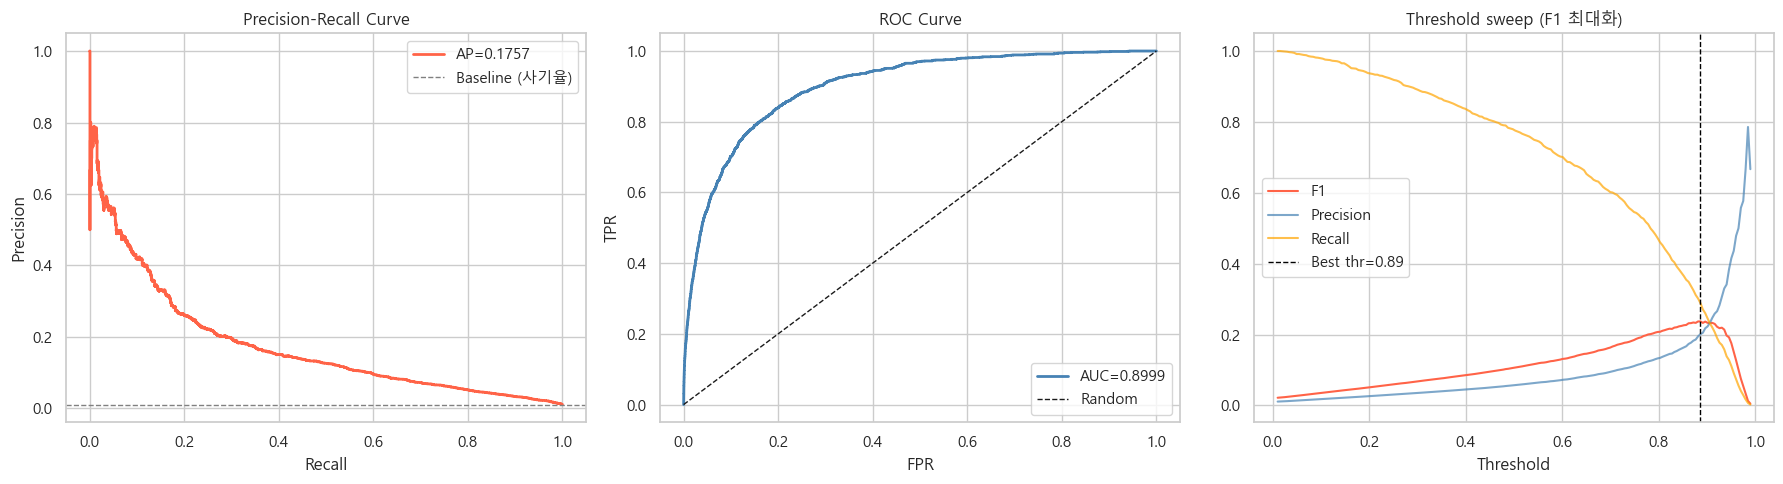

최적 임계값: 0.887  F1: 0.2372


In [111]:
from sklearn.metrics import (precision_recall_curve, roc_curve, roc_auc_score,
                              average_precision_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# PR Curve
prec, rec, thr_pr = precision_recall_curve(y_va, y_prob)
ap = average_precision_score(y_va, y_prob)
axes[0].step(rec, prec, color='tomato', where='post', lw=2, label=f'AP={ap:.4f}')
axes[0].axhline(y_va.mean(), color='gray', linestyle='--', lw=1, label='Baseline (사기율)')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve'); axes[0].legend()

# ROC Curve
fpr, tpr, _ = roc_curve(y_va, y_prob)
ra = roc_auc_score(y_va, y_prob)
axes[1].plot(fpr, tpr, color='steelblue', lw=2, label=f'AUC={ra:.4f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve'); axes[1].legend()

# Threshold sweep
thresholds = np.linspace(0.01, 0.99, 200)
f1s = [f1_score(y_va, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
precs_sw = [precision_recall_curve(y_va, y_prob)[0][np.searchsorted(thr_pr, t, side='right') - 1]
            if t < thr_pr[-1] else 1.0 for t in thresholds]
recs_sw  = [precision_recall_curve(y_va, y_prob)[1][np.searchsorted(thr_pr, t, side='right') - 1]
            if t < thr_pr[-1] else 0.0 for t in thresholds]
best_t = thresholds[np.argmax(f1s)]
axes[2].plot(thresholds, f1s,    label='F1',       color='tomato')
axes[2].plot(thresholds, precs_sw, label='Precision', color='steelblue', alpha=0.7)
axes[2].plot(thresholds, recs_sw,  label='Recall',    color='orange',    alpha=0.7)
axes[2].axvline(best_t, color='black', linestyle='--', lw=1, label=f'Best thr={best_t:.2f}')
axes[2].set_xlabel('Threshold'); axes[2].set_title('Threshold sweep (F1 최대화)')
axes[2].legend()

plt.tight_layout()
plt.show()
print(f'최적 임계값: {best_t:.3f}  F1: {max(f1s):.4f}')


### 5-2. Lift / Gain / Confusion matrix / Calibration

**다음 단계:**
- Lift가 낮은 구간 → 중위 스코어 영역 개선 피처 탐색
- Calibration이 어긋나면 → `CalibratedClassifierCV` 레이어 추가


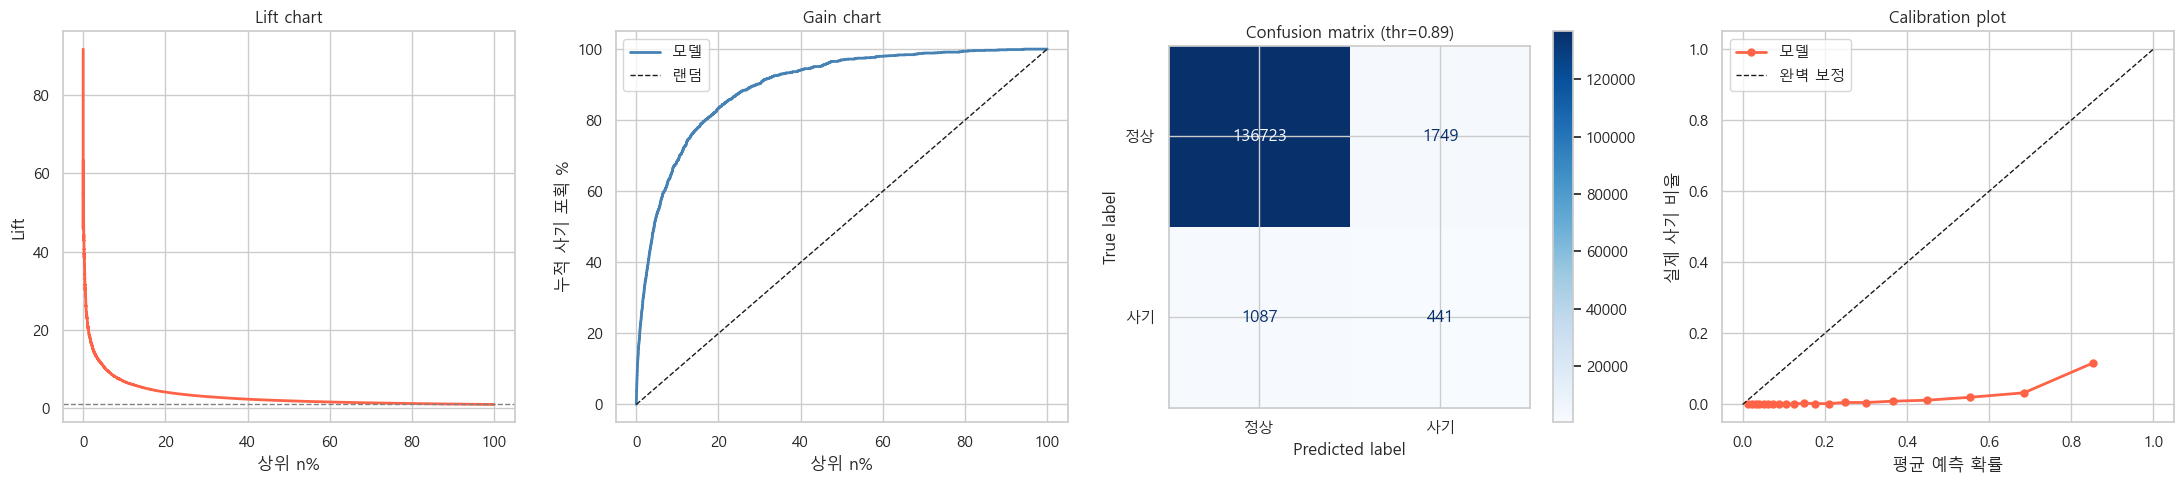

In [112]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Lift & Gain
df_lift = pd.DataFrame({'prob': y_prob, 'actual': y_va.values})
df_lift = df_lift.sort_values('prob', ascending=False).reset_index(drop=True)
df_lift['cum_actual'] = df_lift['actual'].cumsum()
total_pos = df_lift['actual'].sum()
n_lift = len(df_lift)
pct  = np.arange(1, n_lift + 1) / n_lift * 100
gain = df_lift['cum_actual'] / total_pos * 100
lift = gain / pct

axes[0].plot(pct, lift, color='tomato', lw=2)
axes[0].axhline(1, color='gray', linestyle='--', lw=1)
axes[0].set_xlabel('상위 n%'); axes[0].set_ylabel('Lift')
axes[0].set_title('Lift chart')

axes[1].plot(pct, gain, color='steelblue', lw=2, label='모델')
axes[1].plot([0, 100], [0, 100], 'k--', lw=1, label='랜덤')
axes[1].set_xlabel('상위 n%'); axes[1].set_ylabel('누적 사기 포획 %')
axes[1].set_title('Gain chart'); axes[1].legend()

# Confusion matrix
best_pred = (y_prob >= best_t).astype(int)
cm_val = confusion_matrix(y_va, best_pred)
ConfusionMatrixDisplay(cm_val, display_labels=['정상', '사기']).plot(ax=axes[2], cmap='Blues')
axes[2].set_title(f'Confusion matrix (thr={best_t:.2f})')

# Calibration
frac_pos, mean_pred = calibration_curve(y_va, y_prob, n_bins=20, strategy='quantile')
axes[3].plot(mean_pred, frac_pos, 'o-', color='tomato', lw=2, ms=5, label='모델')
axes[3].plot([0, 1], [0, 1], 'k--', lw=1, label='완벽 보정')
axes[3].set_xlabel('평균 예측 확률'); axes[3].set_ylabel('실제 사기 비율')
axes[3].set_title('Calibration plot'); axes[3].legend()

plt.tight_layout()
plt.show()


---
## 6) 시간/순서 (이 데이터에 적용 가능한 기법)


### 6-1. 순서형 변수의 시계열 스타일 분석 — 전체 기간형 피처

`days_since_req` 등 기간·일수 계열 변수 전체를 대상으로 구간별 사기율을 봅니다.

**다음 단계:**
- 특정 기간 구간에서 사기율이 높으면 → `기간 구간 피처` (예: 30일 이내 = 1)
- ACF에서 자기상관 → rolling 집계 피처 (누수 주의)


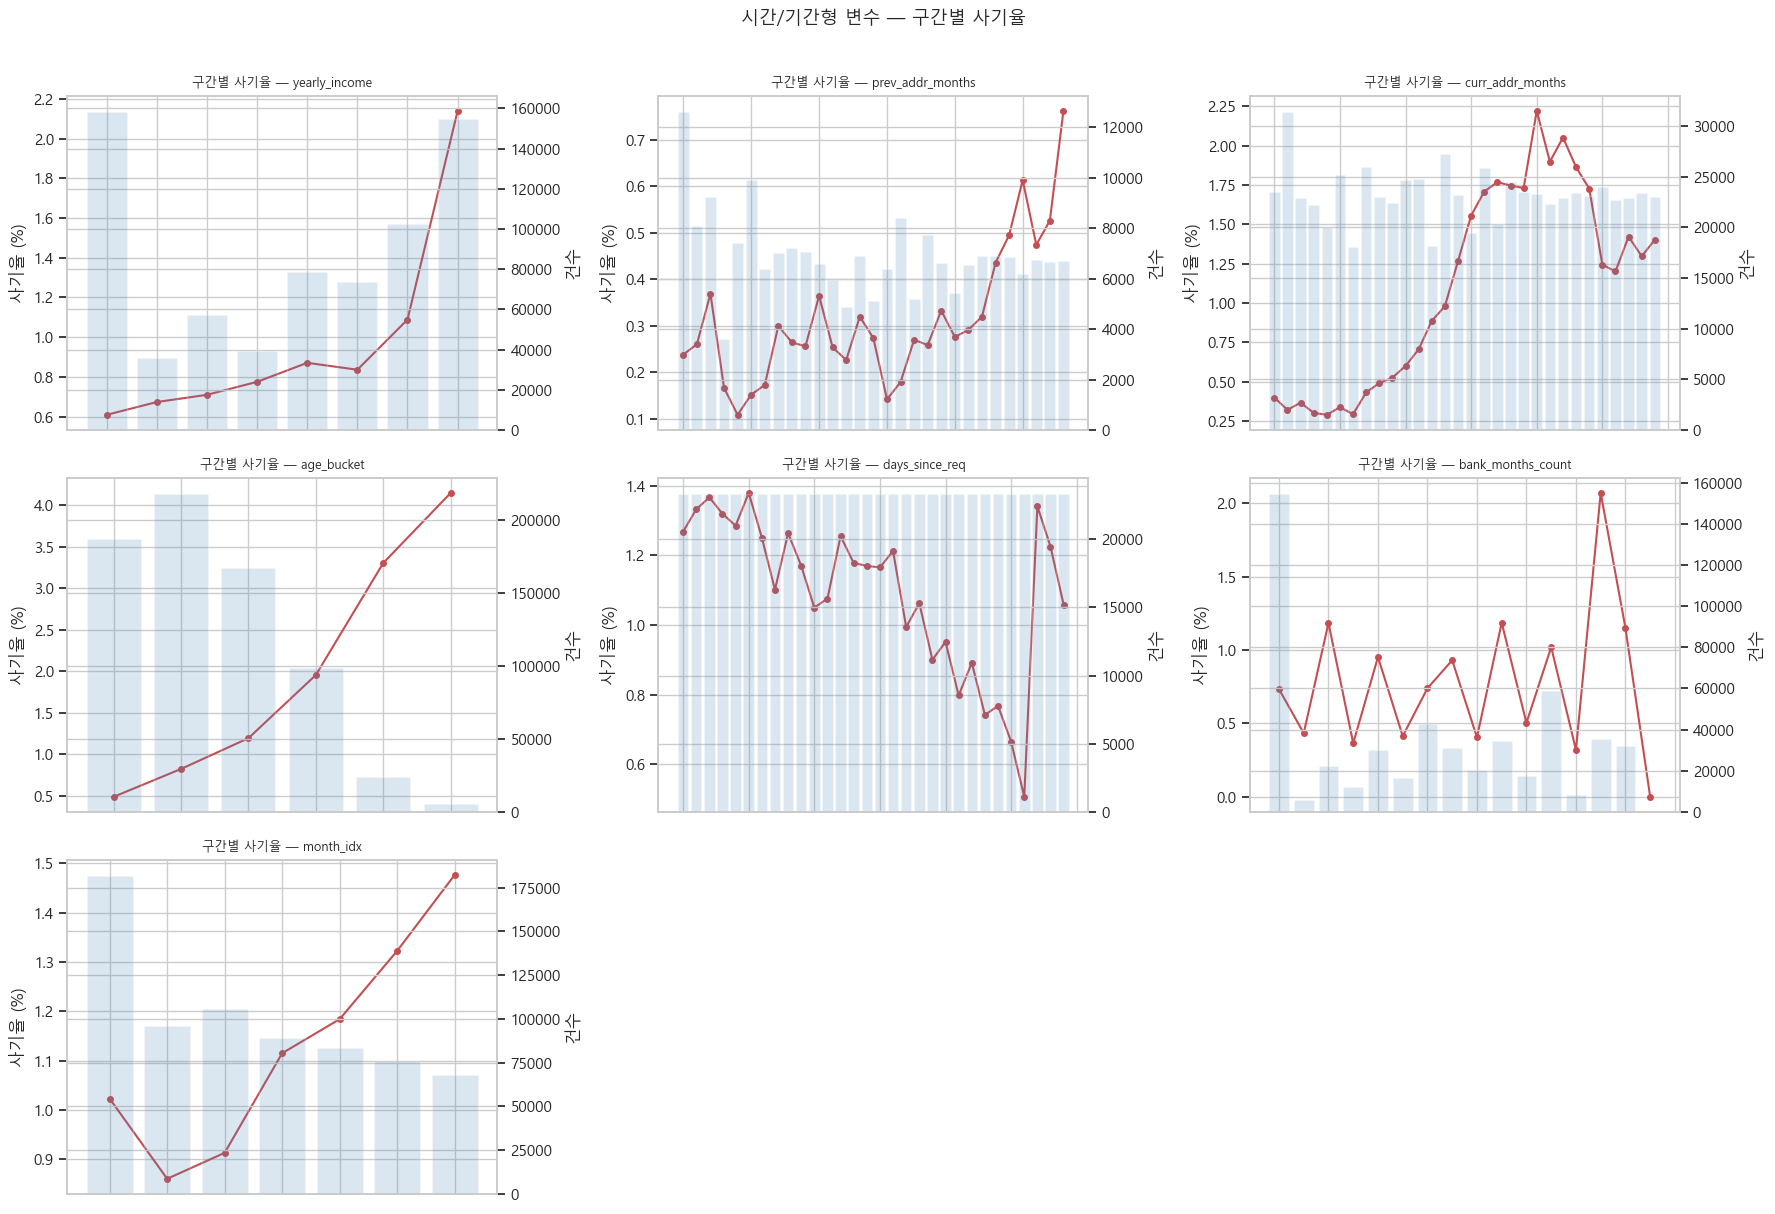

In [113]:
# 기간/일수 관련 컬럼 자동 선택 (이름에 day, month 포함)
time_candidates = [c for c in num_cols
                   if any(kw in c.lower() for kw in ['day', 'month', 'year', 'age', 'time'])]
if not time_candidates:
    time_candidates = num_cols[:3]

ncols = min(3, len(time_candidates))
nrows = (len(time_candidates) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 6, nrows * 4))
axes = axes.flatten() if nrows > 1 else axes if len(time_candidates) > 1 else [axes]

for i, tc in enumerate(time_candidates):
    ax = axes[i]
    df_t = train[[tc, 'fraud_bool']].replace(-1, np.nan).dropna()
    df_t['bin'] = pd.qcut(df_t[tc], q=30, duplicates='drop')
    binned = df_t.groupby('bin', observed=True)['fraud_bool'].agg(['mean', 'count']).reset_index()
    binned.index = range(len(binned))

    ax.plot(binned.index, binned['mean'] * 100, 'r-o', ms=4, lw=1.5, label='사기율')
    ax2 = ax.twinx()
    ax2.bar(binned.index, binned['count'], alpha=0.2, color='steelblue', label='건수')
    ax.set_title(f'구간별 사기율 — {tc}', fontsize=9)
    ax.set_ylabel('사기율 (%)')
    ax2.set_ylabel('건수')
    ax.tick_params(axis='x', labelbottom=False)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('시간/기간형 변수 — 구간별 사기율', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


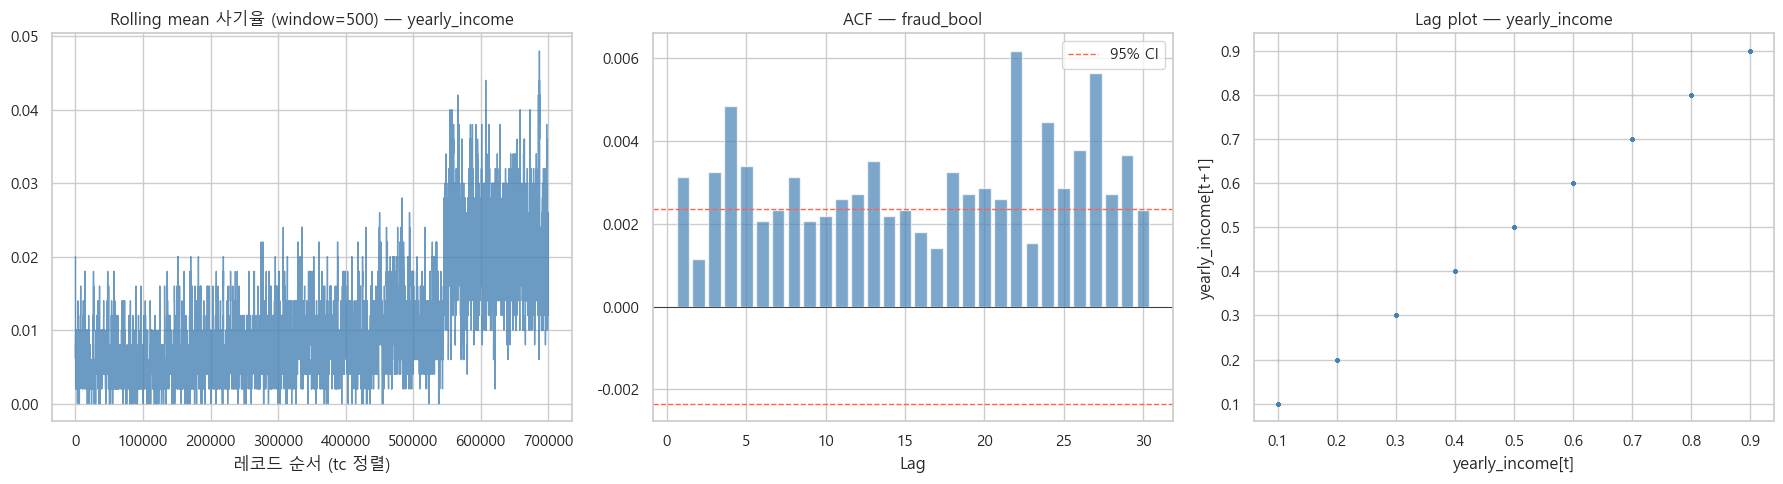

In [114]:
# ── Rolling mean / ACF / Lag plot (여러 lag) ──
tc = time_candidates[0]
df_t = train[[tc, 'fraud_bool']].replace(-1, np.nan).dropna().sort_values(tc)
y_s = df_t[tc].values

# 1) Rolling + ACF
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

roll = df_t['fraud_bool'].rolling(window=500, min_periods=50).mean()
axes[0].plot(roll.values, color='steelblue', lw=1, alpha=0.8)
axes[0].set_title(f'Rolling mean 사기율 (window=500) — {tc}')
axes[0].set_xlabel('레코드 순서 (tc 정렬)')

y_acf = df_t['fraud_bool'].values - df_t['fraud_bool'].mean()
lags = range(1, 31)
acf_vals = [np.corrcoef(y_acf[:-l], y_acf[l:])[0, 1] for l in lags]
sig = 1.96 / np.sqrt(len(y_acf))
axes[1].bar(list(lags), acf_vals, color='steelblue', alpha=0.7)
axes[1].axhline(0,    color='black', lw=0.5)
axes[1].axhline( sig, color='tomato', linestyle='--', lw=1, label='95% CI')
axes[1].axhline(-sig, color='tomato', linestyle='--', lw=1)
axes[1].set_title('ACF — fraud_bool'); axes[1].set_xlabel('Lag'); axes[1].legend()

plt.tight_layout()
plt.show()

# 2) Lag plot — lag 값을 바꿔가며 (x[t] vs x[t+lag])
LAG_LIST = [1, 2, 5, 10, 20, 50]
nrows, ncols = 2, 3
fig2, axes2 = plt.subplots(nrows, ncols, figsize=(16, 10))
axes2 = np.atleast_1d(axes2).ravel()

for ax, lag in zip(axes2, LAG_LIST):
    if len(y_s) <= lag:
        ax.set_visible(False)
        continue
    a, b = y_s[:-lag], y_s[lag:]
    ax.scatter(a, b, alpha=0.05, s=3, color='steelblue')
    r = np.corrcoef(a, b)[0, 1] if len(a) > 1 else np.nan
    ax.set_xlabel(f'{tc}[t]')
    ax.set_ylabel(f'{tc}[t+{lag}]')
    ax.set_title(f'Lag={lag}   r={r:.4f}')

plt.suptitle(f'Lag plot — {tc} (다양한 lag)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


---
## 7) 텍스트/범주 텍스트 시각화


### 7. 텍스트 시각화 (이 데이터셋에는 텍스트 컬럼 없음)

| 기법 | 뭐 보여주나 | 언제 쓰나 |
|------|-------------|-----------|
| **Word Cloud** | 자주 나오는 단어를 크기로 | 고객 메모, 리뷰, 이메일 |
| **Top-N terms bar** | 상위 단어 빈도 막대 | 단어 빈도 비교 |
| **TF-IDF bar** | 클래스별 특징 단어 | 사기/정상 메시지에서 차별 단어 |
| **Sentiment distribution** | 감성(긍/부) 분포 | 고객 불만 접수 텍스트 |
| **LDA topic scatter** | 토픽 모델링 결과 | 다량 문서 분류 |

이 데이터에서는 `device_os`, `housing_status` 등 범주 이름이 의미를 담고 있어  
위 3) 카테고리의 "카테고리별 사기율 막대"가 같은 역할을 합니다.


---
## 8) 데이터 품질 / 누수 진단


### 8-1. Train vs Test 분포 비교 / KS test — 전체 피처

**뭐 보여주나:** train과 test의 분포가 얼마나 다른지. p < 0.05이면 분포 차이 있음.

**다음 단계:**
- KS p값이 낮은 변수 → train 과적합 위험 → 해당 변수 제거 또는 변환
- 분포가 크게 다르면 → log·clip·robust scaling으로 스케일 맞추기


              feature  KS_stat  p_value 분포 다름
       name_email_sim   0.0232 0.135561    no
  branch_req_count_8w   0.0228 0.148610    no
        yearly_income   0.0192 0.315388    no
     prev_addr_months   0.0180 0.392763    no
     zip_req_count_4w   0.0170 0.465358    no
          req_rate_4w   0.0160 0.544187    no
          req_rate_6h   0.0156 0.577046    no
     curr_addr_months   0.0150 0.627218    no
       days_since_req   0.0144 0.677788    no
  is_home_phone_valid   0.0144 0.677788    no
    bank_months_count   0.0140 0.711289    no
   session_length_min   0.0136 0.744274    no
            month_idx   0.0132 0.776418    no
         req_rate_24h   0.0128 0.807376    no
    credit_risk_score   0.0116 0.889652    no
    init_transfer_amt   0.0112 0.912466    no
   dob_email_count_4w   0.0106 0.941502    no
     req_credit_limit   0.0102 0.957217    no
           age_bucket   0.0086 0.992633    no
is_session_persistent   0.0072 0.999490    no
  device_email_cnt_8w   0.0040 1.0

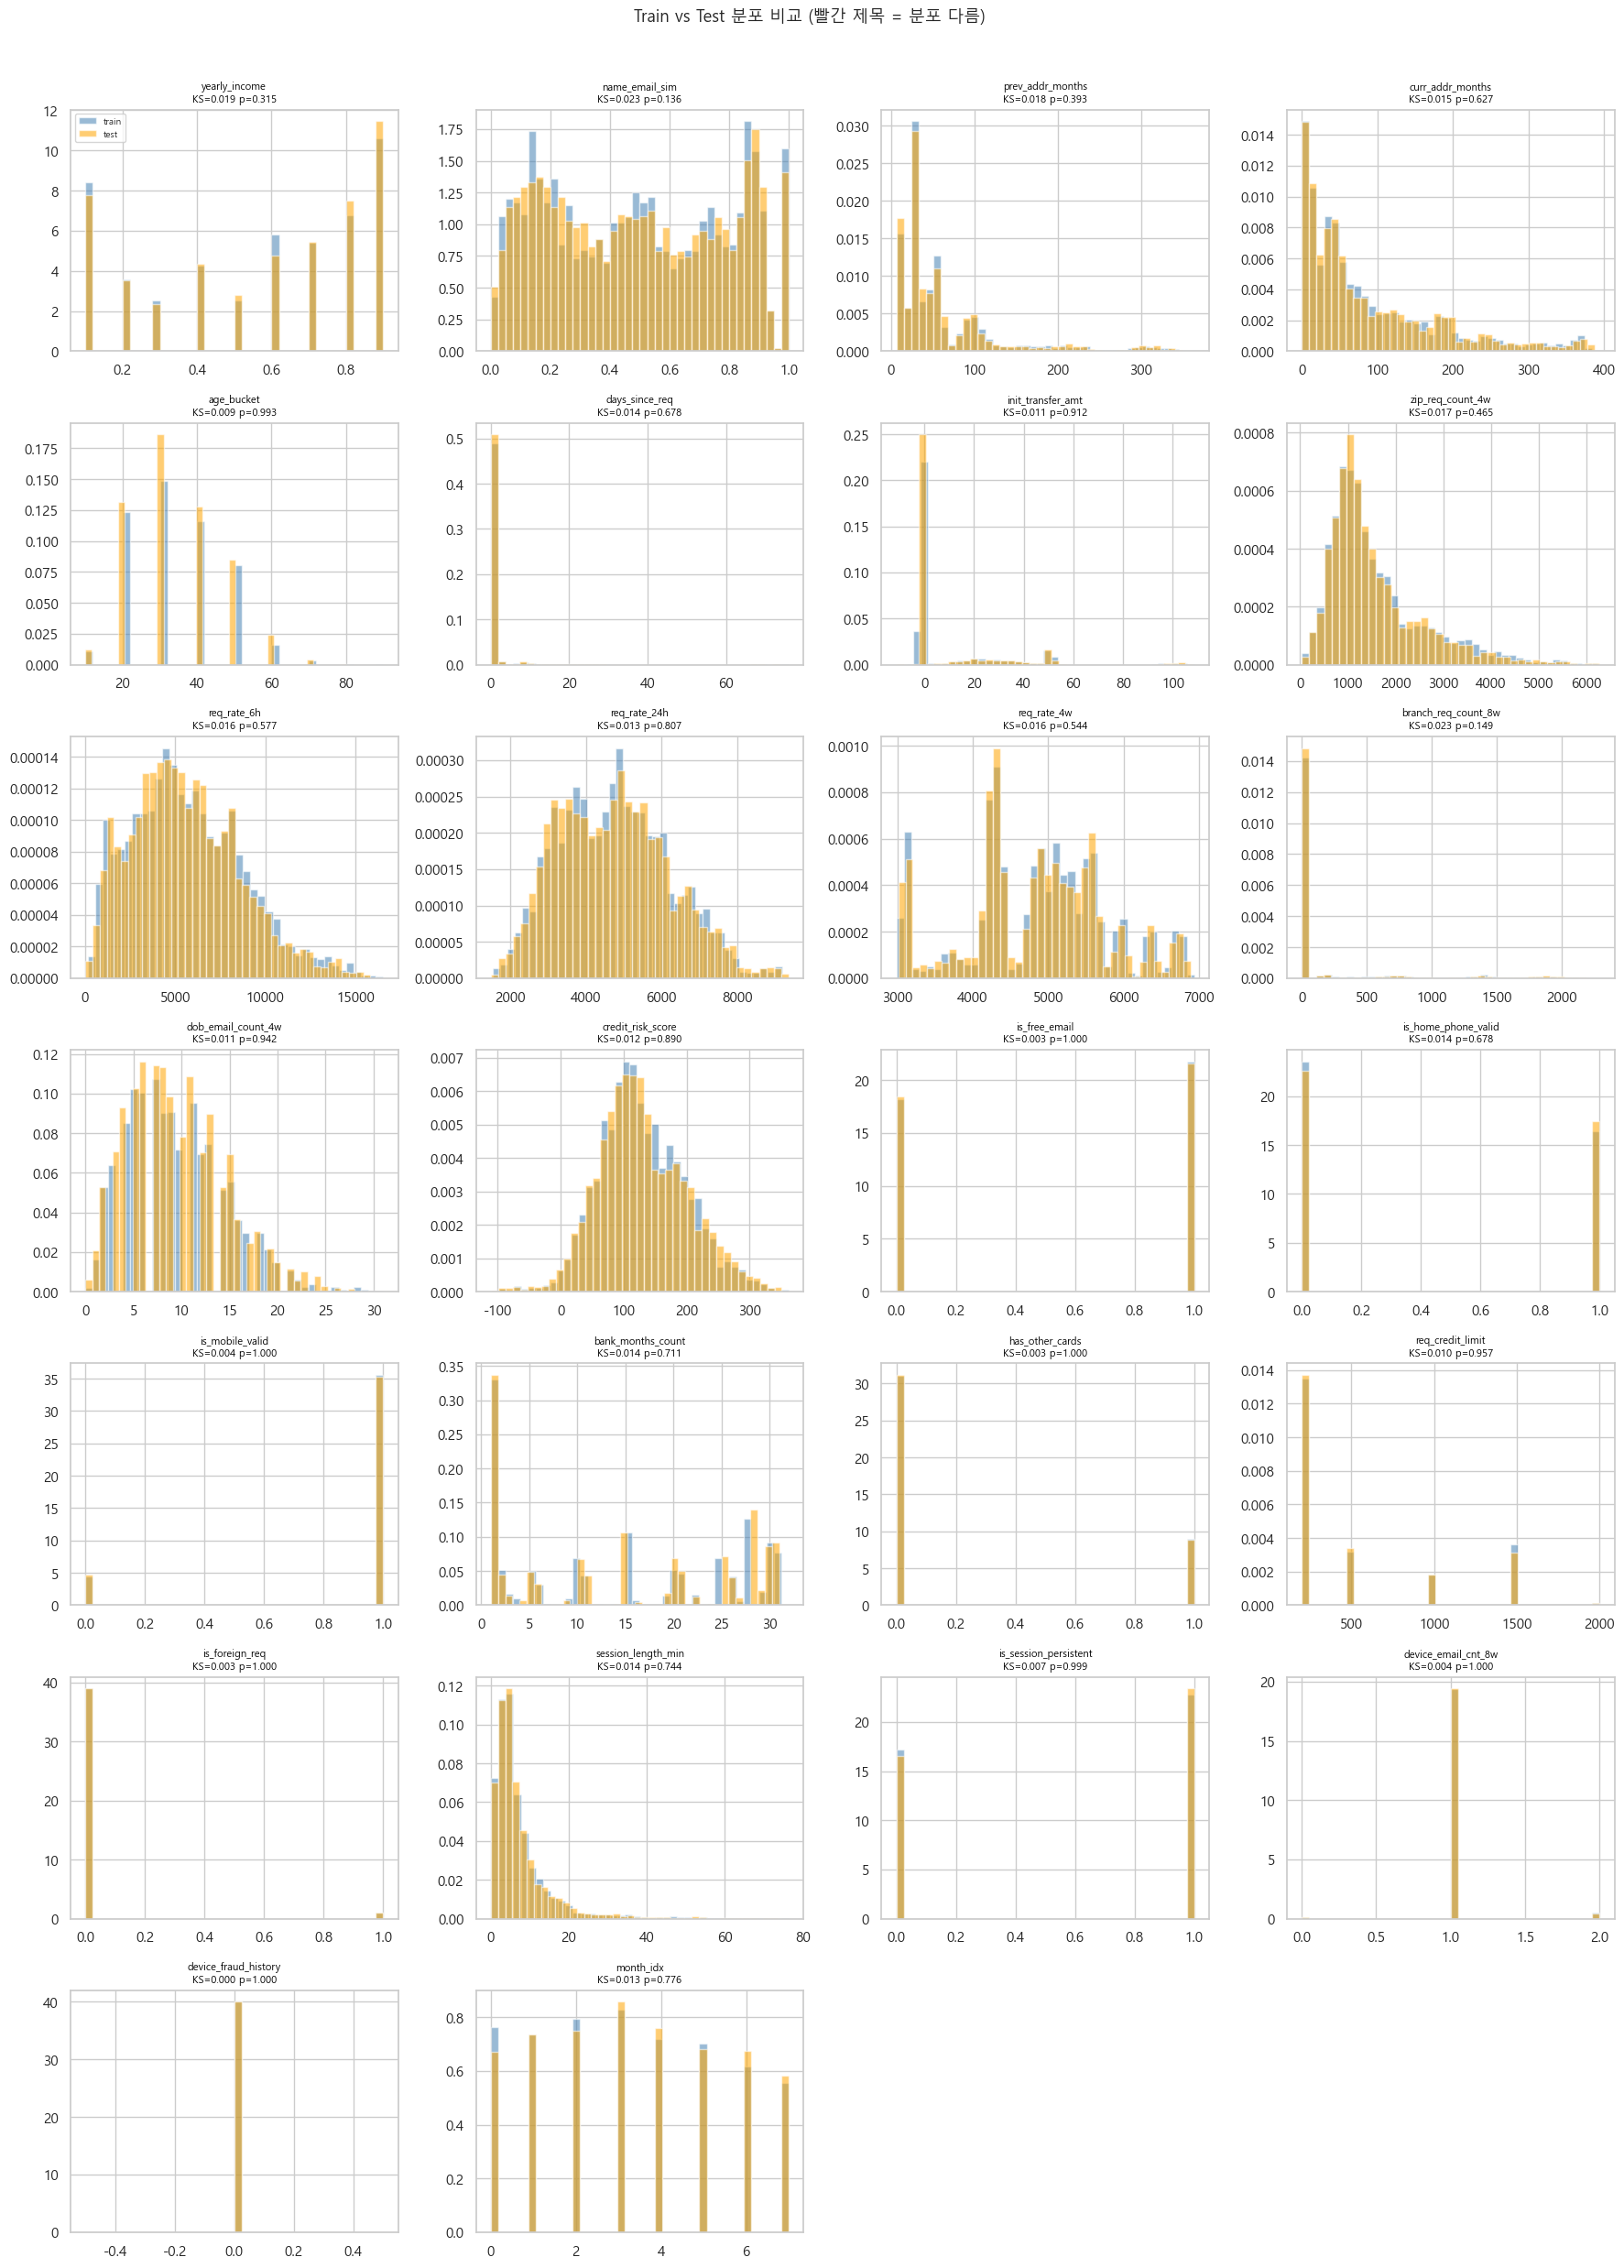

In [115]:
# 전체 수치형 피처에 대해 KS test
ks_results = []
for col in num_cols:
    tr_v = train[col].replace(-1, np.nan).dropna()
    te_v = test[col].replace(-1, np.nan).dropna()
    if len(tr_v) < 10 or len(te_v) < 10:
        continue
    ks_stat, ks_p = ks_2samp(
        tr_v.sample(min(5000, len(tr_v)), random_state=SEED),
        te_v.sample(min(5000, len(te_v)), random_state=SEED)
    )
    ks_results.append({'feature': col, 'KS_stat': round(ks_stat, 4),
                        'p_value': round(ks_p, 6), '분포 다름': '★YES' if ks_p < 0.05 else 'no'})

ks_df = pd.DataFrame(ks_results).sort_values('KS_stat', ascending=False)
print(ks_df.to_string(index=False))

# 시각화 — 전체 피처 그리드
n = len(num_cols)
ncols = NCOLS_GRID
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 3.5))
axes = axes.flatten() if nrows > 1 else axes if n > 1 else [axes]

for i, col in enumerate(num_cols):
    ax = axes[i]
    tr_v = train[col].replace(-1, np.nan).dropna()
    te_v = test[col].replace(-1, np.nan).dropna()
    row = ks_df[ks_df['feature'] == col]
    ks_stat_val = row['KS_stat'].values[0] if len(row) else float('nan')
    ks_p_val    = row['p_value'].values[0]  if len(row) else float('nan')

    ax.hist(tr_v.sample(min(3000, len(tr_v)), random_state=SEED), bins=40,
            alpha=0.55, density=True, color='steelblue', label='train')
    ax.hist(te_v.sample(min(3000, len(te_v)), random_state=SEED), bins=40,
            alpha=0.55, density=True, color='orange', label='test')
    title_color = 'red' if ks_p_val < 0.05 else 'black'
    ax.set_title(f'{col}\nKS={ks_stat_val:.3f} p={ks_p_val:.3f}',
                 fontsize=8, color=title_color)
    if i == 0:
        ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Train vs Test 분포 비교 (빨간 제목 = 분포 다름)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


### 8-2. Missingness vs Class / Rare category / Drift 요약표

**다음 단계:**
- 결측 여부가 클래스에 따라 다르면 → `is_missing` 플래그 피처가 유효
- Rare category → `Other`로 묶거나 빈도 인코딩
- 평균 drift가 큰 변수 → clip·log로 스케일 맞추기


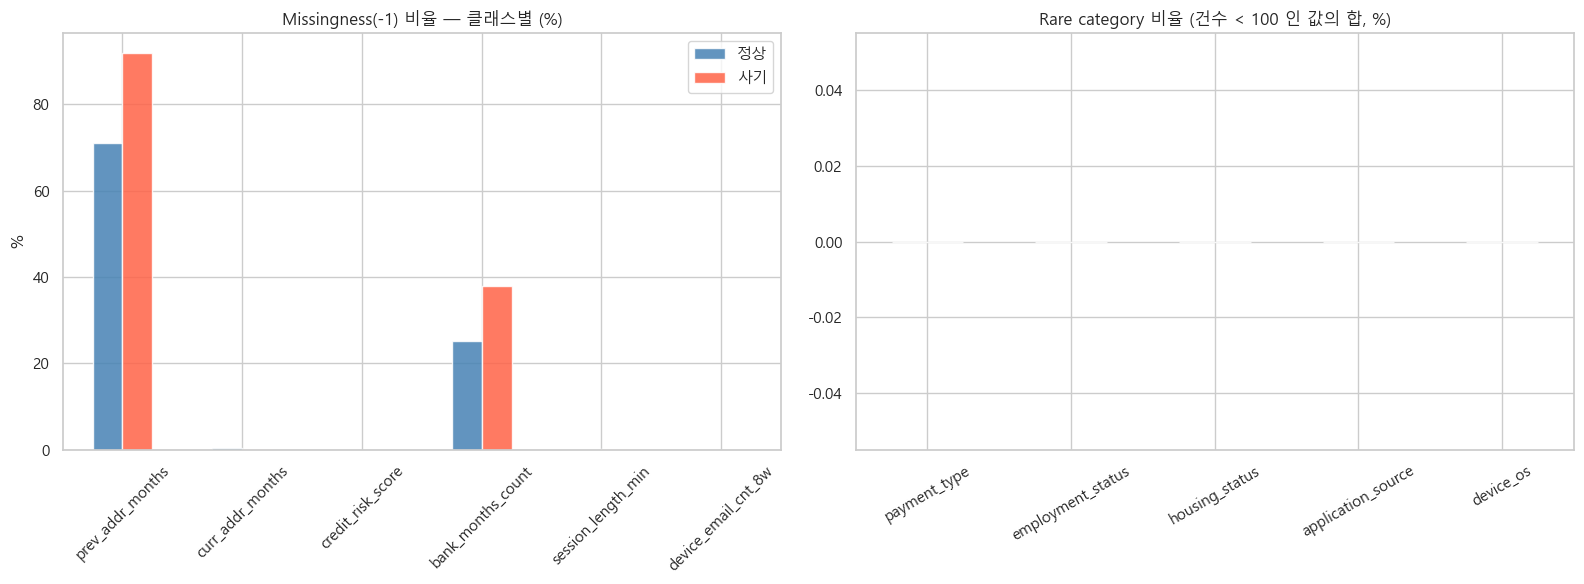


[데이터 드리프트 요약]
                   칼럼  train_mean  test_mean  diff_%  train_std  test_std
       is_foreign_req       0.025      0.025    1.18      0.157     0.156
    init_transfer_amt       8.684      8.609    0.86     20.259    20.183
   session_length_min       7.548      7.595    0.62      8.017     8.067
  branch_req_count_8w     184.606    183.791    0.44    460.046   458.644
  is_home_phone_valid       0.417      0.418    0.39      0.493     0.493
    bank_months_count      14.851     14.890    0.26     11.525    11.535
     req_credit_limit     515.476    516.725    0.24    487.297   488.172
     zip_req_count_4w    1571.703   1575.000    0.21   1005.214  1005.747
    credit_risk_score     130.976    131.236    0.20     69.637    69.639
            month_idx       3.290      3.285    0.15      2.210     2.210
       days_since_req       1.026      1.025    0.14      5.380     5.386
is_session_persistent       0.577      0.577    0.13      0.494     0.494
     prev_addr_months  

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Missingness vs class (센티넬 -1)
miss_by_class = {}
for col in num_cols:
    r0 = (normal[col] == -1).mean()
    r1 = (fraud[col]  == -1).mean()
    if r0 > 0 or r1 > 0:
        miss_by_class[col] = {'정상': r0 * 100, '사기': r1 * 100}

if miss_by_class:
    miss_bc = pd.DataFrame(miss_by_class).T
    miss_bc.plot(kind='bar', ax=axes[0], color=['steelblue', 'tomato'], alpha=0.85)
    axes[0].set_title('Missingness(-1) 비율 — 클래스별 (%)')
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].set_ylabel('%')
else:
    axes[0].text(0.5, 0.5, '-1 센티넬 없음', transform=axes[0].transAxes, ha='center')
    axes[0].set_title('Missingness vs class')

# Rare category rate
if cat_cols:
    rare_info = {}
    for c in cat_cols:
        vc = train[c].value_counts()
        rare_info[c] = (vc[vc < 100].sum() / len(train)) * 100
    pd.Series(rare_info).plot.bar(ax=axes[1], color='orchid', alpha=0.85)
    axes[1].set_title('Rare category 비율 (건수 < 100 인 값의 합, %)')
    axes[1].tick_params(axis='x', rotation=30)
else:
    axes[1].text(0.5, 0.5, '범주형 칼럼 없음', transform=axes[1].transAxes, ha='center')

plt.tight_layout()
plt.show()

# 드리프트 요약표
drift_rows = []
for col in num_cols:
    tr_v = train[col].replace(-1, np.nan).dropna()
    te_v = test[col].replace(-1, np.nan).dropna()
    drift_rows.append({
        '칼럼': col,
        'train_mean': round(tr_v.mean(), 3),
        'test_mean':  round(te_v.mean(), 3),
        'diff_%': round(abs(tr_v.mean() - te_v.mean()) / (abs(tr_v.mean()) + 1e-9) * 100, 2),
        'train_std': round(tr_v.std(), 3),
        'test_std':  round(te_v.std(), 3),
    })
print('\n[데이터 드리프트 요약]')
print(pd.DataFrame(drift_rows).sort_values('diff_%', ascending=False).to_string(index=False))


---
## 전체 요약 — 기법별 다음 단계 한눈에 보기

| 카테고리 | 핵심 기법 | 피처 엔지니어링 행동 |
|----------|-----------|---------------------|
| 1) 단일 분포 | Histogram·KDE·ECDF·Violin·QQ | 치우침→log, 피크차이→bin 플래그 |
| 2) 수치-수치 | Hexbin·LOESS·Contour·Binned | 두 축의 밀집 구간→비율·교차 피처 |
| 3) 수치-범주 | Grouped Violin·100% stack | 그룹 내 z-score, 범주×수치 교차 |
| 4) 다변량 | PCA·t-SNE·SHAP·PDP·ICE | 상위 변수 집중 파생, PDP 꺾임→임계값 |
| 5) 분리력 | PR·ROC·Lift·Calibration | 최적 임계값, 보정 레이어 추가 |
| 6) 시간/순서 | Rolling·ACF·Lag | 기간 구간 피처, rolling 집계 (누수 주의) |
| 7) 텍스트 | (이 데이터 해당 없음) | — |
| 8) 품질 진단 | KS test·Drift·Missingness vs class | 드리프트 변수 변환, missing 플래그 |
